# Agri EdgeAI Research — Mango Leaf Disease Classification (v8 EDA & Clean Modular, logic v5)

**Pipeline thị giác máy tính cổ điển có khả năng giải thích cho bệnh lá xoài**

Phiên bản này tập trung vào một hệ sinh thái dữ liệu: **MangoLeafBD (8 lớp)** làm tập nguồn và **MLDID (5 lớp chung)** làm kiểm thử ngoài. Các bản sửa v5 tập trung vào độ bền với nhiễu, tiền xử lý nhận biết tiền cảnh, chọn ngưỡng confidence nhất quán với validation, benchmark transfer-learning có đóng băng backbone, và căn chỉnh miền CORAL theo từng khối đặc trưng.

**Nguyên tắc thực nghiệm**
- Group-Split theo cụm gần-trùng là kết quả chính; Random-Split chỉ là phép tham chiếu có nguy cơ rò rỉ.
- Threshold/gate và checkpoint CNN được chọn trên validation; test chỉ dùng để báo cáo.
- Bảng 5 là đánh giá robustness trên các phép biến đổi tổng hợp; không khẳng định trước hệ thống sẽ thắng mọi perturbation.
- Bảng 6 đo latency CPU thực tế; các phép đo proxy trong bảng ablation được ghi rõ là ước lượng.
- MLDID zero-shot không dùng nhãn/statistics target để huấn luyện hoặc căn chỉnh. CORAL dùng đặc trưng target không nhãn nên được ghi rõ là transductive.
- Các chỉ số từ HTML phiên v4 là kết quả lịch sử, không được sao chép thành kết quả v5; hãy chạy lại notebook trước khi dùng trong paper.


## Cách đọc và thực thi notebook modular v8

Notebook được chia theo các bước công việc độc lập: cấu hình, chuẩn bị dữ liệu, định nghĩa hàm, chạy thí nghiệm và tổng hợp kết quả. Các hàm được đặt trong những cell riêng để dễ tìm, kiểm tra và chạy lại.

Phần giải thích đặt trong cell Markdown ngay trước nhóm code liên quan. Comment trong code chỉ giữ lại ở những chỗ cần làm rõ quyết định xử lý hoặc lưu ý kỹ thuật; các comment lặp lại nội dung từng câu lệnh đã được bỏ.

**Quy tắc thực nghiệm được giữ nguyên:** Group-Split là kết quả chính; validation dùng để chọn hyperparameter/view/gate/checkpoint; test chỉ dùng để báo cáo; MLDID zero-shot và CORAL transductive vẫn là hai protocol riêng biệt.

Output của phiên v7 cũ đã được dọn để không trộn với kết quả EDA mới. Khi chạy toàn bộ notebook trong Colab, các bảng và biểu đồ EDA sẽ được tạo từ đúng dữ liệu đang nằm trên Google Drive.

## 1. Cấu trúc Google Drive

Gốc dữ liệu: `/content/drive/MyDrive/Agri_EdgeAI_Research/`

```text
Agri_EdgeAI_Research/
└── MANGO/
    ├── main_data/
    │   └── MangoLeafBD Dataset.zip
    └── external_data/
        └── Raw Images of Five Class (Resized).zip
```

Notebook giải nén ZIP vào SSD tạm `/content/agri_edgeai_ssd/MANGO/`, không sửa dữ liệu nguồn trên Drive. Sau giải nén, nó dò thư mục dataset theo các tên root đã xác nhận. Nếu Drive đã chứa thư mục giải nén, notebook cũng hỗ trợ sao chép sang SSD.

**Lưu ý về cache:** v5 thay đổi thuật toán tiền xử lý/LBP/CORAL. Feature cache được tăng phiên bản để buộc trích xuất lại các vector tương thích.


## 2. Khởi tạo môi trường
Thư viện, cấu hình random seed và trạng thái runtime. Google Drive được mount nếu notebook đang chạy trong Colab.


### Import thư viện và khởi tạo runtime

**Mục đích:** Nạp thư viện nền tảng, thư viện xử lý ảnh, học máy, thống kê và tiện ích notebook.

**Đầu ra / tác động:** Tạo namespace và trạng thái seed; Google Drive chỉ mount khi môi trường là Colab.


In [ ]:
import os
import re
import cv2
import time
import json
import glob
import math
import shutil
import zipfile
import warnings
import traceback
import gc
from concurrent.futures import ThreadPoolExecutor
import psutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from IPython.display import display, Markdown
from scipy.stats import binomtest
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report, f1_score,
    precision_recall_curve, auc
)

warnings.filterwarnings("ignore", category=FutureWarning)

# Google Colab: mount Drive only if it is not already mounted.
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except ImportError:
    print("[INFO] Non-Colab environment detected; Drive mounting skipped.")

SEED = 20261022
np.random.seed(SEED)
try:
    cv2.setNumThreads(1)
except Exception:
    pass
print(f"[INIT OK] Environment ready | Seed={SEED} | OpenCV={cv2.__version__}")


Mounted at /content/drive
[INIT OK] Environment ready | Seed=20261022 | OpenCV=4.14.0


## 3. Cấu hình nghiên cứu chuyên sâu — MANGO

| Vai trò | Dataset | Quy mô dự kiến | Sử dụng |
|---|---|---:|---|
| Tập nguồn | MangoLeafBD Dataset | 8 lớp, khoảng 4.000 ảnh | Group-Split, kiểm toán near-duplicate, ablation, robustness, benchmark |
| Tập kiểm thử ngoài | Raw Images of Five Class (Resized) / MLDID | 5 lớp chung, khoảng 3.000 ảnh | Đánh giá cross-dataset trên các nhãn giao nhau |

Tám lớp nguồn được chuẩn hóa thành `Anthracnose`, `Bacterial_Canker`, `Cutting_Weevil`, `Die_Back`, `Gall_Midge`, `Healthy`, `Powdery_Mildew` và `Sooty_Mold`. Tên `Sooty Mould`/`Sooty Mold` và `Gall Mid` ở external được ánh xạ có quy tắc về nhãn chuẩn. Bảng 7 chỉ sử dụng năm nhãn chung; không giả định external có ba lớp mà nguồn còn lại.

CNN benchmark bật mặc định ở bản đơn-track này, nhưng tổng thời gian phụ thuộc runtime, tải pretrained weights và khả năng GPU. Mạng được train trên GPU nếu có, sau đó latency inference được đo trên CPU để so sánh với pipeline cổ điển.


### Cấu hình track MANGO và tham số nghiên cứu

**Mục đích:** Khai báo root Drive/SSD, tên dataset, số lớp, cache schema, chế độ benchmark và số worker.

**Đầu ra / tác động:** Tạo thư mục cần thiết và in ra cấu hình đã chọn.


In [ ]:
BASE_DRIVE_DIR = "/content/drive/MyDrive/Agri_EdgeAI_Research"
LOCAL_SSD_BASE = "/content/agri_edgeai_ssd"
VALID_EXTS = {".jpg", ".jpeg", ".jpe", ".png", ".bmp", ".webp", ".tif", ".tiff"}

TRACKS = [{
    "track_name": "MANGO",
    "drive_folder": "MANGO",
    "main_source_role": "main_data",
    "main_root_hints": [["MangoLeafBD Dataset"]],
    "external_root_hints": [["Resize mango leaf disease"]],
    "expected_class_count": 8,
    "main_dataset": "MangoLeafBD Dataset (8 classes, ~4,000 images)",
    "external_dataset": "Raw Images of Five Class (Resized) / MLDID (5 shared classes, ~3,000 images)",
}]
TRACK_FOLDER_MAP = {t["track_name"]: t["drive_folder"] for t in TRACKS}

RUN_BACKGROUND_SHORTCUT_AUDIT = True
RUN_CNN_BENCHMARK = True
CNN_EPOCHS = 6
CNN_MODELS = ["mobilenet_v3_small", "mobilenet_v2", "resnet50"]
CNN_LATENCY_SAMPLE_LIMIT = 300
FEATURE_EXTRACTION_WORKERS = min(4, max(1, os.cpu_count() or 1))

# Bump both values whenever a feature formula, preprocessing path, or split schema changes.
MANIFEST_SCHEMA_VERSION = "manifest-v6-mango-mad-lut-fastfg-blockcoral"
FEATURE_CACHE_VERSION = "handcrafted-v8-mango-mad-lut-fastfg-blockcoral"
CANONICAL_COLOR_MODE = "lab_l"  # lab_l preserves leaf chroma; gray_world_bounded is an optional sensitivity check.

os.makedirs(BASE_DRIVE_DIR, exist_ok=True)
os.makedirs(LOCAL_SSD_BASE, exist_ok=True)
print("Focused paper track:", [t["track_name"] for t in TRACKS])
print("Google Drive:", BASE_DRIVE_DIR)
print("Local SSD:", LOCAL_SSD_BASE)
print("CNN benchmark:", RUN_CNN_BENCHMARK, "| epochs/model:", CNN_EPOCHS)


Focused paper track: ['MANGO']
Google Drive: /content/drive/MyDrive/Agri_EdgeAI_Research
Local SSD: /content/agri_edgeai_ssd
CNN benchmark: True | epochs/model: 6


## 4. Chuẩn bị dữ liệu — giải nén ZIP vào SSD Colab

Cell kế tiếp chỉ xử lý hai vị trí của MANGO (`main_data` và `external_data`). Mỗi ZIP được giải nén vào một thư mục theo tên archive; marker cho phép bỏ qua việc giải nén lại nếu file nguồn không đổi. Các file nguồn trên Google Drive được giữ nguyên.


### Đếm nhanh ảnh hợp lệ trong một thư mục

**Thành phần:** `_count_images_quick(folder)`

**Mục đích:** Đầu vào là đường dẫn thư mục. Hàm chỉ xét phần mở rộng nằm trong `VALID_EXTS`, bỏ file ẩn và không đọc pixel.

**Đầu ra / tác động:** Trả về số lượng ảnh; dùng để kiểm tra ZIP đã giải nén hay thư mục đã có dữ liệu.


In [ ]:
# Mỗi ZIP được giải nén vào:
# /content/agri_edgeai_ssd/<DATASET>/<main_data|external_data>/<ZIP_STEM>/
# Marker tương thích với lần giải nén trước để không giải nén lại nếu archive
# và đích không thay đổi. Các file nguồn trên Drive không bị sửa.

def _count_images_quick(folder):
    count = 0
    if not os.path.isdir(folder):
        return 0
    for root, _, files in os.walk(folder):
        count += sum(
            1 for name in files
            if not name.startswith(".") and os.path.splitext(name)[1].lower() in VALID_EXTS
        )
    return count


### Giải nén ZIP có kiểm tra đường dẫn

**Thành phần:** `_safe_extract_zip(zip_path, destination)`

**Mục đích:** Nhận đường dẫn archive và thư mục đích. Trước khi giải nén, từng thành viên ZIP được kiểm tra để ngăn path traversal.

**Đầu ra / tác động:** Giải nén vào thư mục đích hoặc phát sinh lỗi nếu archive chứa đường dẫn không an toàn.


In [ ]:
def _safe_extract_zip(zip_path, destination):
    destination_abs = os.path.abspath(destination)
    with zipfile.ZipFile(zip_path, "r") as zf:
        # Reject archive traversal entries before extracting.
        for member in zf.infolist():
            target = os.path.abspath(os.path.join(destination, member.filename))
            if os.path.commonpath([destination_abs, target]) != destination_abs:
                raise RuntimeError(f"Unsafe path inside ZIP: {member.filename}")
        zf.extractall(destination)


### Chuẩn bị ZIP và dữ liệu cục bộ

**Mục đích:** Duyệt các role main_data/external_data và dùng marker để tránh giải nén lặp lại.

**Đầu ra / tác động:** Tạo dataset tree trên SSD tạm; file nguồn trên Drive được giữ nguyên.


In [ ]:
roles_to_prepare = sorted({
    (cfg["drive_folder"], role)
    for cfg in TRACKS
    for role in ("main_data", "external_data")
})

for drive_folder, role in roles_to_prepare:
    drive_dir = os.path.join(BASE_DRIVE_DIR, drive_folder, role)
    local_root = os.path.join(LOCAL_SSD_BASE, drive_folder, role)

    if not os.path.isdir(drive_dir):
        print(f"[DATA SOURCE MISSING] {drive_dir}")
        continue

    zip_paths = sorted(glob.glob(os.path.join(drive_dir, "*.zip")))
    if zip_paths:
        os.makedirs(local_root, exist_ok=True)
        for zip_path in zip_paths:
            stem = os.path.splitext(os.path.basename(zip_path))[0]
            dest = os.path.join(local_root, stem)
            marker = os.path.join(dest, ".unzip_complete")
            expected_marker = (
                f"archive={zip_path}\n"
                f"size={os.path.getsize(zip_path)}\n"
                f"mtime={os.path.getmtime(zip_path)}\n"
            )

            marker_matches = False
            if os.path.isfile(marker):
                try:
                    marker_matches = (
                        open(marker, "r", encoding="utf-8").read() == expected_marker
                        and _count_images_quick(dest) > 0
                    )
                except OSError:
                    marker_matches = False

            if marker_matches:
                print(f"[ZIP SKIP] {drive_folder}/{role}/{os.path.basename(zip_path)} (unchanged)")
                continue

            if os.path.isdir(dest):
                shutil.rmtree(dest)

            os.makedirs(dest, exist_ok=True)
            print(f"[ZIP EXTRACT] {drive_folder}/{role}/{os.path.basename(zip_path)}")
            _safe_extract_zip(zip_path, dest)

            with open(marker, "w", encoding="utf-8") as f:
                f.write(expected_marker)

            print(f"[ZIP READY] {_count_images_quick(dest):,} image files -> {dest}")
    else:
        # Also support folders that were manually extracted on Drive.
        existing_local_count = _count_images_quick(local_root)
        drive_count = _count_images_quick(drive_dir)
        if existing_local_count:
            print(f"[LOCAL READY] {local_root} | {existing_local_count:,} image files")
        elif drive_count:
            shutil.copytree(drive_dir, local_root, dirs_exist_ok=True)
            print(f"[COPY TO SSD] {drive_folder}/{role} | {drive_count:,} image files")
        else:
            print(f"[NO ZIP OR IMAGES] {drive_dir}")

print("[DATA PREPARATION COMPLETE] Exact dataset roots will be resolved in the next section.")

[ZIP EXTRACT] MANGO/external_data/Raw Images of Five Class (Resized).zip
[ZIP READY] 3,000 image files -> /content/agri_edgeai_ssd/MANGO/external_data/Raw Images of Five Class (Resized)
[ZIP EXTRACT] MANGO/main_data/MangoLeafBD Dataset.zip
[ZIP READY] 4,000 image files -> /content/agri_edgeai_ssd/MANGO/main_data/MangoLeafBD Dataset
[DATA PREPARATION COMPLETE] Exact dataset roots will be resolved in the next section.


## 5. Ánh xạ nhãn theo folder MANGO

Nhãn được đọc từ tên folder lớp dọc theo đường dẫn tương đối. `Train`, `Test`, `Val` và tên dataset không được xem là nhãn. Các folder `Augmented`, `Balanced` hoặc component chỉ rõ augmentation bị loại khỏi scan của tập nguồn chính; ảnh gần trùng trong các folder lớp vẫn được xử lý bằng kiểm toán pHash/HSV và Group-Split.

Các tên lớp được chuẩn hóa rõ ràng; nhãn external không thuộc tám lớp chuẩn sẽ bị loại khỏi phép đo. Bảng 7 sử dụng phần giao nhãn nguồn–đích và ghi riêng số lớp dùng để đánh giá.


### Định nghĩa `_norm_token`

**Thành phần:** `_norm_token(value)`

**Mục đích:** Normalize a folder name for matching, while retaining original names in manifests.

**Đầu ra / tác động:** Đăng ký hàm/lớp vào namespace của notebook; chưa thực thi pipeline tại bước định nghĩa.


In [ ]:
def _norm_token(value):
    """Normalize a folder name for matching, while retaining original names in manifests."""
    value = str(value).strip().casefold()
    value = value.replace("&", " and ")
    value = re.sub(r"[^a-z0-9]+", "_", value)
    return re.sub(r"_+", "_", value).strip("_")


### Các thư mục không được xem là nhãn lớp

Danh sách này loại các tên thư mục mang tính cấu trúc như `train`, `test`, `images` hoặc tên dataset. Chỉ các folder khớp quy tắc nhãn của track mới được đưa vào manifest.

In [ ]:
GENERIC_DIRS = {
    "", "main_data", "external_data", "original", "originals", "raw", "raw_data",
    "dataset", "data", "train", "training", "test", "testing", "val",
    "valid", "validation", "images", "image", "fruit", "stem", "leaf", "leaves",
    "archive", "mangoleafbd_dataset", "dragonfruit_multiorgan_dataset",
    "dragon_leaf_and_fruit", "dragon_fruit_and_leaf", "dragon_fruit_balanced",
    "durian_leaf_diseases", "dld_finaldataset_224_spit",
}


### Chuẩn hóa tên folder thành nhãn nghiên cứu

**Thành phần:** `standardize_label(raw_folder_name, track_name, is_external, rel_parts)`

**Mục đích:** Nhận tên thư mục, track và cờ external; sử dụng quy tắc ánh xạ đã khai báo trong notebook.

**Đầu ra / tác động:** Trả về tên lớp chuẩn hoặc `None` nếu folder không phải folder lớp được hỗ trợ.


In [ ]:
def standardize_label(raw_folder_name, track_name, is_external=False, rel_parts=None):
    """
    Map only names supported by the inspected directory structure.
    rel_parts is the relative directory path split into components; it is used
    for DF-MOD, where the organ (Fruit/Stem) is needed to map into UDCAD's 4 groups.
    """
    raw = _norm_token(raw_folder_name)
    parts = [_norm_token(p) for p in (rel_parts or [])]

    if raw in GENERIC_DIRS:
        return None

    if track_name == "DURIAN":
        if "algal" in raw:
            return "Algal_Leaf_Spot"
        if "allocaridara" in raw or "psyllid" in raw:
            return "Allocaridara_Attack"
        if "healthy" in raw:
            return "Healthy_Leaf"
        if "blight" in raw:
            return "Leaf_Blight"
        if "phomopsis" in raw:
            return "Phomopsis_Leaf_Spot"
        # VNDurLeaf's Colletotrichum and Rhizoctonia have no corresponding
        # labels in DurianLDD and are excluded from cross-dataset metrics.
        return None

    if track_name == "MANGO":
        if "anthracnose" in raw:
            return "Anthracnose"
        if "bacteri" in raw or "canker" in raw or "cancer" in raw:
            return "Bacterial_Canker"
        if "weevil" in raw or "cutting" in raw:
            return "Cutting_Weevil"
        if "die_back" in raw or "dieback" in raw:
            return "Die_Back"
        if "gall" in raw or "midge" in raw or "mid_disease" in raw or "gall_mid" in raw:
            return "Gall_Midge"
        if "healthy" in raw:
            return "Healthy"
        if "powdery" in raw or "mildew" in raw:
            return "Powdery_Mildew"
        if "sooty" in raw or "mold" in raw or "mould" in raw:
            return "Sooty_Mold"
        return None

    if track_name == "DRAGONFRUIT_UDCAD_4C":
        # Main UDCAD labels are exactly Good/Bad fruit and Good/Bad leaf.
        if not is_external:
            mapping = {
                "good_fruit": "Healthy_Fruit",
                "bad_fruit": "Diseased_Fruit",
                "good_leaf": "Healthy_Leaf",
                "bad_leaf": "Diseased_Leaf",
            }
            return mapping.get(raw)

        # External DF-MOD labels are mapped by organ + healthy/diseased status.
        # This is a four-group protocol, not an eight-disease taxonomy.
        organ = next((p for p in reversed(parts) if p in {"fruit", "stem"}), None)
        if organ == "fruit":
            if raw in {"healthy_fruit", "healthy"}:
                return "Healthy_Fruit"
            if raw in {"black_rot", "fungi", "rot", "fungus"}:
                return "Diseased_Fruit"
        elif organ == "stem":
            if raw in {"healthy_leaf", "healthy"}:
                return "Healthy_Leaf"
            if raw in {"rust", "scab", "stem_canker", "sunburn"}:
                return "Diseased_Leaf"
        return None

    if track_name == "DRAGONFRUIT_MULTIORGAN_8C":
        # Preserve the eight observed DF-MOD class names; do not invent
        # unverified disease-to-disease mappings.
        mapping = {
            "black_rot": "Black_Rot",
            "fungi": "Fungi",
            "healthy_fruit": "Healthy_Fruit",
            "healthy_leaf": "Healthy_Leaf",
            "rust": "Rust",
            "scab": "Scab",
            "stem_canker": "Stem_Canker",
            "sunburn": "Sunburn",
        }
        return mapping.get(raw)

    return None


### Tìm nhãn từ đường dẫn tương đối

**Thành phần:** `resolve_label_from_relpath(rel_dir, track_name, is_external)`

**Mục đích:** Nhận các thành phần đường dẫn tương đối và duyệt từ folder sâu nhất lên trên.

**Đầu ra / tác động:** Trả về nhãn chuẩn cùng tên folder gốc đã khớp.


In [ ]:
def resolve_label_from_relpath(rel_dir, track_name, is_external=False):
    """Search from the leaf folder upward and retain the source folder matched."""
    parts = [p for p in str(rel_dir).replace("\\", "/").split("/") if p and p != "."]
    for index in range(len(parts) - 1, -1, -1):
        label = standardize_label(
            parts[index], track_name, is_external=is_external, rel_parts=parts
        )
        if label is not None:
            return label, parts[index]
    return None, (parts[-1] if parts else "")


### Quét dataset và lập danh sách ảnh có nhãn

**Thành phần:** `scan_dataset_records(data_root, track_name, is_external)`

**Mục đích:** Nhận root dataset; duyệt cấu trúc folder, bỏ folder metadata/augmentation và kiểm tra phần mở rộng.

**Đầu ra / tác động:** Trả về danh sách record ảnh và các folder có ảnh để chẩn đoán ánh xạ nhãn.


In [ ]:
def scan_dataset_records(data_root, track_name, is_external=False):
    """
    Scan only the configured dataset root.
    - Folder names are preserved.
    - Augmented/Balanced branches are skipped component-wise, not by substring
      over the entire absolute path.
    - Return image records and discovered image-containing folders for diagnostics.
    """
    records = []
    discovered_folders = set()
    root_abs = os.path.abspath(data_root)

    for root, dirs, files in os.walk(root_abs):
        dirs[:] = sorted(
            d for d in dirs
            if d.casefold() not in {"__macosx", ".ipynb_checkpoints", "__pycache__"}
        )
        rel_dir = os.path.relpath(root, root_abs)
        rel_parts = [] if rel_dir == "." else rel_dir.replace("\\", "/").split("/")
        normalized_parts = [_norm_token(p) for p in rel_parts]

        # Skip only actual augmentation/balanced directory components.
        if any(
            ("augment" in part) or ("balanced" in part)
            for part in normalized_parts
        ):
            dirs[:] = []
            continue

        valid_files = [
            f for f in sorted(files)
            if not f.startswith(".")
            and not f.startswith("._")
            and os.path.splitext(f)[1].casefold() in VALID_EXTS
        ]
        if not valid_files:
            continue

        label_name, matched_folder = resolve_label_from_relpath(
            rel_dir, track_name, is_external=is_external
        )
        if label_name is None:
            discovered_folders.add(rel_dir)
            continue

        discovered_folders.add(rel_dir)
        for filename in valid_files:
            path = os.path.join(root, filename)
            try:
                size_kb = os.path.getsize(path) / 1024.0
            except OSError:
                size_kb = np.nan
            records.append({
                "file_path": path,
                "filename": filename,
                "raw_folder": matched_folder,
                "label_name": label_name,
                "file_size_kb": size_kb,
                "relative_folder": rel_dir,
            })

    records.sort(key=lambda row: (row["label_name"], row["file_path"].casefold()))
    return records, discovered_folders


### Đếm ảnh đệ quy trong cây thư mục

**Thành phần:** `count_images_in_dir(directory)`

**Mục đích:** Nhận đường dẫn thư mục; không giải mã ảnh mà chỉ kiểm tra tên file và phần mở rộng.

**Đầu ra / tác động:** Trả về số ảnh để quyết định sử dụng SSD, copy hay giải nén.


In [ ]:
def count_images_in_dir(directory):
    if not directory or not os.path.isdir(directory):
        return 0
    total = 0
    for root, _, files in os.walk(directory):
        total += sum(
            1 for name in files
            if not name.startswith(".")
            and os.path.splitext(name)[1].casefold() in VALID_EXTS
        )
    return total


### Chuẩn bị bản dữ liệu local trên SSD

**Thành phần:** `prepare_data_directory(drive_subdir, local_ssd_subdir, role_name)`

**Mục đích:** Nhận thư mục trên Drive, thư mục SSD và vai trò MAIN/EXTERNAL.

**Đầu ra / tác động:** Trả về thư mục local sẵn sàng; external được phép thiếu, còn nguồn chính thì phải tồn tại.


In [ ]:
def prepare_data_directory(drive_subdir, local_ssd_subdir, role_name="MAIN"):
    """Use extracted SSD data where available; otherwise unzip/copy to local SSD."""
    local_count = count_images_in_dir(local_ssd_subdir)
    if local_count > 0:
        print(f"[{role_name} SSD READY] {local_ssd_subdir} | {local_count:,} image files")
        return local_ssd_subdir

    if not os.path.isdir(drive_subdir):
        if role_name == "EXTERNAL":
            print(f"[EXTERNAL INFO] Missing optional source: {drive_subdir}")
            return None
        raise FileNotFoundError(f"Missing required source folder: {drive_subdir}")

    zip_paths = sorted(glob.glob(os.path.join(drive_subdir, "*.zip")))
    if zip_paths:
        os.makedirs(local_ssd_subdir, exist_ok=True)
        for archive in zip_paths:
            dest = os.path.join(
                local_ssd_subdir, os.path.splitext(os.path.basename(archive))[0]
            )
            os.makedirs(dest, exist_ok=True)
            _safe_extract_zip(archive, dest)
        local_count = count_images_in_dir(local_ssd_subdir)
        if local_count:
            return local_ssd_subdir

    drive_count = count_images_in_dir(drive_subdir)
    if drive_count:
        os.makedirs(os.path.dirname(local_ssd_subdir), exist_ok=True)
        shutil.copytree(drive_subdir, local_ssd_subdir, dirs_exist_ok=True)
        print(f"[COPY TO SSD] {local_count:,} image files from Drive")
        return local_ssd_subdir

    if role_name == "EXTERNAL":
        print(f"[EXTERNAL INFO] No images/ZIP available under {drive_subdir}; external test skipped.")
        return None
    raise FileNotFoundError(f"No images or ZIP archives found under {drive_subdir}")


### Phân giải đúng root dataset từ tên folder gợi ý

**Thành phần:** `_find_dataset_root_by_hints(base_root, hints, required)`

**Mục đích:** Duyệt các thành phần đường dẫn và so khớp chính xác sau chuẩn hóa token, tránh match substring nhầm.

**Đầu ra / tác động:** Trả về root có ảnh phù hợp nhất hoặc `None`/lỗi theo cờ `required`.


In [ ]:
def _find_dataset_root_by_hints(base_root, hints, required=True):
    """
    Resolve a dataset's exact subdirectory by ordered path-component hints.
    Example: ['DragonFruit-MultiOrgan Dataset', 'Dragon Fruit'].
    Matching uses complete normalized component names, not substring checks.
    """
    if base_root is None or not os.path.isdir(base_root):
        return None

    if not hints:
        return base_root

    if isinstance(hints[0], str):
        hints = [hints]

    candidate_matches = []
    for current, dirs, _ in os.walk(base_root):
        dirs.sort(key=str.casefold)
        rel = os.path.relpath(current, base_root)
        parts = [] if rel == "." else rel.replace("\\", "/").split("/")
        norm_parts = [_norm_token(p) for p in parts]

        for hint in hints:
            norm_hint = [_norm_token(p) for p in hint]
            if len(norm_parts) >= len(norm_hint) and norm_parts[-len(norm_hint):] == norm_hint:
                n_images = count_images_in_dir(current)
                if n_images:
                    candidate_matches.append((n_images, current, hint))

    if candidate_matches:
        candidate_matches.sort(key=lambda x: (-x[0], x[1].casefold()))
        n_images, resolved, matched_hint = candidate_matches[0]
        print(
            f"[ROOT RESOLVED] {matched_hint} -> {resolved} "
            f"({n_images:,} images in branch)"
        )
        return resolved

    if required:
        # Print candidate folder names to make incorrect archive layouts easy to diagnose.
        visible = []
        for current, dirs, _ in os.walk(base_root):
            dirs.sort(key=str.casefold)
            rel = os.path.relpath(current, base_root)
            if rel != ".":
                visible.append(rel)
            if len(visible) >= 60:
                break
        raise FileNotFoundError(
            f"Could not resolve dataset root under {base_root}; expected one of {hints}. "
            f"First discovered folders: {visible[:30]}"
        )
    return None


### Tạo bảng kiểm kê dữ liệu nguồn trên Google Drive

**Thành phần:** `summarize_drive_inventory()`

**Mục đích:** Đọc cấu hình `TRACKS` và kiểm tra folder/ZIP/ảnh ở từng role.

**Đầu ra / tác động:** Trả về DataFrame dùng để xác nhận dữ liệu đã được đặt đúng vị trí.


In [ ]:
def summarize_drive_inventory():
    rows = []
    handled = set()
    for cfg in TRACKS:
        for role in ("main_data", "external_data"):
            key = (cfg["drive_folder"], role)
            if key in handled:
                continue
            handled.add(key)
            path = os.path.join(BASE_DRIVE_DIR, *key)
            archives = sorted(glob.glob(os.path.join(path, "*.zip"))) if os.path.isdir(path) else []
            rows.append({
                "Dataset folder": cfg["drive_folder"],
                "Role": role,
                "Drive path": path,
                "Folder exists": os.path.isdir(path),
                "ZIP count": len(archives),
                "ZIP names": ", ".join(os.path.basename(p) for p in archives) or "(none)",
                "Extracted image files on Drive": count_images_in_dir(path),
            })
    return pd.DataFrame(rows)


### Kiểm tra cấu trúc dữ liệu trên Google Drive

Bảng bên dưới cho biết từng role có tồn tại hay không, có bao nhiêu ZIP và có ảnh đã giải nén trực tiếp trên Drive hay không.

In [ ]:
display(summarize_drive_inventory())


,Dataset folder,Role,Drive path,Folder exists,ZIP count,ZIP names,Extracted image files on Drive
0,MANGO,main_data,/content/drive/MyDrive/Agri_EdgeAI_Research/MA...,True,1,MangoLeafBD Dataset.zip,0
1,MANGO,external_data,/content/drive/MyDrive/Agri_EdgeAI_Research/MA...,True,1,Raw Images of Five Class (Resized).zip,0


## 6. Manifest và kiểm toán gần-trùng

Mỗi ảnh được kiểm tra khả năng đọc, độ phân giải và chữ ký perceptual-hash/HSV. Manifest có version và được làm mới khi schema, đường dẫn hoặc phiên bản thay đổi. `Group-Split` là kết quả chính; `Random-Split` được báo riêng để định lượng mức nhạy với rò rỉ.


### Tạo chữ ký ảnh pHash và HSV

**Thành phần:** `compute_phash_and_hsv_signature(img_bgr)`

**Mục đích:** Nhận ảnh BGR đã đọc được từ OpenCV.

**Đầu ra / tác động:** Trả về vector pHash 64-bit dạng nhị phân và histogram HSV đã chuẩn hóa để phát hiện near-duplicate.


In [ ]:
def compute_phash_and_hsv_signature(img_bgr):
    """Tính 64-bit DCT Perceptual Hash và biểu đồ màu HSV vùng tâm (60% ROI) để bắt các ảnh xoay/zoom/gần-trùng."""
    gray_32 = cv2.resize(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
    dct_mat = cv2.dct(gray_32)[:8, :8]
    med_val = np.median(dct_mat[1:, 1:])
    bits = (dct_mat > med_val).flatten().astype(np.int8)

    h, w, _ = img_bgr.shape
    crop = img_bgr[int(h*0.2):int(h*0.8), int(w*0.2):int(w*0.8)]
    hsv_small = cv2.cvtColor(cv2.resize(crop, (64, 64), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2HSV)
    hist_hs = cv2.calcHist([hsv_small], [0, 1], None, [12, 8], [0, 180, 0, 256]).flatten().astype(np.float32)
    hist_hs /= (np.linalg.norm(hist_hs) + 1e-8)
    return bits, hist_hs


### Tổng hợp bảng kiểm toán manifest đã có

**Thành phần:** `_write_manifest_audit_table(df, output_dir)`

**Mục đích:** Nhận manifest đã có cột group/split/resolution.

**Đầu ra / tác động:** Ghi Table 1 và trả về số lượng ảnh, cụm ảnh và tỷ lệ rò rỉ của Random-Split.


In [ ]:
def _write_manifest_audit_table(df, output_dir):
    """Rebuild Table 1 from a validated manifest."""
    rows = []
    for class_id, (class_name, group) in enumerate(df.groupby("label_name", sort=True)):
        n_images = len(group)
        n_clusters = group["group_id"].nunique()
        mode_values = group["resolution"].mode()
        rows.append({
            "Class ID": class_id,
            "Class Name": class_name,
            "Total Images": n_images,
            "Unique Specimen Clusters (pHash<=6 | HSV cosine>=0.992)": n_clusters,
            "Near-Duplicate / Aug-Mix Ratio (%)": round((1 - n_clusters / max(1, n_images)) * 100, 2),
            "Dominant Resolution": mode_values.iloc[0] if not mode_values.empty else "Unknown",
        })
    train_groups = set(df.loc[df["split_random"] == "Train_Orig", "group_id"])
    random_test = df[df["split_random"] == "Test_Orig"]
    leaked = sum(g in train_groups for g in random_test["group_id"].values)
    leak_pct = 100.0 * leaked / max(1, len(random_test))
    summary = pd.DataFrame(rows)
    summary["Random-Split Test Leakage (%)"] = round(leak_pct, 2)
    summary.to_csv(os.path.join(output_dir, "Table1_Dataset_Leakage_and_Group_Audit.csv"), index=False)
    return summary


### Xây dựng manifest, gom cụm near-duplicate và chia tập

**Thành phần:** `build_audited_manifest(data_root, track_name, manifest_csv_path, output_dir, seed)`

**Mục đích:** Nhận root dataset, track, đường dẫn CSV và output directory. Cache chỉ được dùng khi schema/root/file hợp lệ.

**Đầu ra / tác động:** Trả về DataFrame manifest và danh sách lớp; Group-Split là giao thức chính, Random-Split chỉ là tham chiếu nhạy rò rỉ.


### 6.3.1 — Đọc và xác thực manifest cache

Cell này chỉ tái sử dụng manifest khi schema, root dataset và các file nguồn đều còn hợp lệ. Nếu không, hàm trả về `None` để buộc xây dựng lại.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _load_valid_manifest_cache(data_root, manifest_csv_path, output_dir):
    """Return (manifest, classes) only when the existing cache is fully compatible."""
    if not os.path.isfile(manifest_csv_path):
        return None

    required_columns = {
        "file_path", "label_name", "label_id", "group_id", "split_group",
        "split_random", "fold_id", "resolution", "manifest_schema"
    }
    try:
        cached = pd.read_csv(manifest_csv_path)
        # Check both schema and the actual source location to avoid stale-cache reuse.
        cache_valid = (
            not cached.empty
            and required_columns.issubset(cached.columns)
            and cached["manifest_schema"].astype(str).eq(MANIFEST_SCHEMA_VERSION).all()
            and cached["file_path"].map(os.path.isfile).all()
            and cached["file_path"].map(lambda p: os.path.commonpath(
                [os.path.abspath(str(p)), os.path.abspath(data_root)]
            ) == os.path.abspath(data_root)).all()
        )
        if not cache_valid:
            print("[MANIFEST CACHE REBUILD] Schema, root, or source files changed.")
            return None

        class_names = sorted(cached["label_name"].unique().tolist())
        audit = _write_manifest_audit_table(cached, output_dir)
        print(f"[MANIFEST CACHE HIT] {manifest_csv_path} | {len(cached):,} images")
        display(audit)
        return cached, class_names
    except Exception as exc:
        print(f"[MANIFEST CACHE REBUILD] Could not validate old manifest: {exc}")
        return None


### 6.3.2 — Quét ảnh, tạo chữ ký và xác thực nhãn

Bước này đọc từng ảnh đúng một lần để loại ảnh lỗi, ghi nhận độ phân giải, pHash/HSV signature và xác nhận số lớp phải khớp cấu hình track.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _scan_and_validate_manifest_images(data_root, track_name):
    """Scan labeled files, decode images, and prepare signatures for duplicate grouping."""
    records, discovered_folders = scan_dataset_records(
        data_root, track_name, is_external=False
    )
    if not records:
        examples = sorted(discovered_folders)[:30]
        raise RuntimeError(
            f"No images could be mapped under {data_root} for {track_name}. "
            f"Image-containing folders seen: {examples}. "
            "Check the configured root hint and class-folder spellings."
        )

    # Remove duplicate paths before doing expensive image decoding/signature work.
    df = pd.DataFrame(records).drop_duplicates(subset=["file_path"]).reset_index(drop=True)
    df = df.sort_values(["label_name", "file_path"], kind="stable").reset_index(drop=True)

    valid_rows, bits_list, hist_list = [], [], []
    for _, row in tqdm(
        df.iterrows(), total=len(df), desc=f"Image signature audit — {track_name}"
    ):
        bgr = cv2.imread(row["file_path"], cv2.IMREAD_COLOR)
        if bgr is None:
            continue
        bits, hsv_sig = compute_phash_and_hsv_signature(bgr)
        record = row.to_dict()
        record["resolution"] = f"{bgr.shape[1]}x{bgr.shape[0]}"
        valid_rows.append(record)
        bits_list.append(bits)
        hist_list.append(hsv_sig)

    df = pd.DataFrame(valid_rows).reset_index(drop=True)
    if df.empty:
        raise RuntimeError(f"No decodable images found under {data_root}.")

    class_names = sorted(df["label_name"].unique().tolist())
    expected_classes = next(
        (int(cfg["expected_class_count"]) for cfg in TRACKS if cfg["track_name"] == track_name),
        None,
    )
    if expected_classes is not None and len(class_names) != expected_classes:
        raise RuntimeError(
            f"{track_name}: mapped {len(class_names)} classes but expected {expected_classes}. "
            f"Observed labels: {class_names}. Refusing to train with a mismatched label map."
        )

    # Stable integer IDs are assigned from sorted canonical class names.
    label_to_id = {name: idx for idx, name in enumerate(class_names)}
    df["label_id"] = df["label_name"].map(label_to_id).astype(int)
    df["manifest_schema"] = MANIFEST_SCHEMA_VERSION
    bits_matrix = np.asarray(bits_list, dtype=np.int8)
    hsv_matrix = np.asarray(hist_list, dtype=np.float32)
    return df, class_names, bits_matrix, hsv_matrix


### 6.3.3 — Gom nhóm ảnh gần trùng theo từng lớp

Tạo đồ thị gần-trùng trong từng lớp. Hai ảnh được nối cạnh khi pHash Hamming ≤ 6 hoặc cosine similarity của histogram HSV ≥ 0.992; connected components trở thành group dùng để chia tập.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _assign_near_duplicate_groups(df, bits_mat_all, hist_mat_all, class_names):
    """Assign connected-component group IDs class by class to cap peak memory."""
    df = df.copy()
    df["group_id"] = -1
    audit_rows = []

    for class_id, class_name in enumerate(class_names):
        class_idx = df.index[df["label_id"] == class_id].to_numpy()
        n = len(class_idx)
        if n == 0:
            continue

        bits_mat = bits_mat_all[class_idx]
        hsv_mat = hist_mat_all[class_idx]
        # Pairwise Hamming and cosine matrices define the near-duplicate graph.
        hamming = np.abs(bits_mat[:, None, :] - bits_mat[None, :, :]).sum(axis=2)
        cosine = hsv_mat @ hsv_mat.T
        adjacency = (hamming <= 6) | (cosine >= 0.992)

        visited = np.zeros(n, dtype=bool)
        n_clusters = 0
        for u in range(n):
            if visited[u]:
                continue
            n_clusters += 1
            cluster_id = int(class_idx[u])
            stack = [u]
            visited[u] = True
            while stack:
                cur = stack.pop()
                df.loc[class_idx[cur], "group_id"] = cluster_id
                neighbors = np.flatnonzero(adjacency[cur] & (~visited))
                for nb in neighbors:
                    visited[nb] = True
                    stack.append(int(nb))

        # Keep the same per-class summary fields used by Table 1.
        modes = df.loc[class_idx, "resolution"].mode()
        audit_rows.append({
            "Class ID": class_id,
            "Class Name": class_name,
            "Total Images": n,
            "Unique Specimen Clusters (pHash<=6 | HSV cosine>=0.992)": n_clusters,
            "Near-Duplicate / Aug-Mix Ratio (%)": round((1 - n_clusters / max(1, n)) * 100, 2),
            "Dominant Resolution": modes.iloc[0] if not modes.empty else "Unknown",
        })
    return df, audit_rows


### 6.3.4 — Tạo Group-Split chính và Random-Split tham chiếu

Tách fold 0 làm test, fold 1 làm validation và fold 2–4 làm train. Đồng thời tạo Random-Split 60/20/20 chỉ để đối chiếu nguy cơ leakage, không thay thế kết quả chính.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _assign_manifest_splits(df, seed):
    """Add the primary stratified-group split and the leakage-sensitive random split."""
    min_count = df["label_id"].value_counts().min()
    if min_count < 5:
        raise RuntimeError(
            f"At least one class has fewer than five decodable images (minimum={min_count}); "
            "cannot form a 5-fold stratified group split."
        )

    # Group-based split: fold 0 test, fold 1 validation, folds 2–4 training.
    df = df.copy()
    df["split_group"] = "Train_Orig"
    df["fold_id"] = -1
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    y_all = df["label_id"].values
    groups_all = df["group_id"].values
    for fold_num, (_, test_pos) in enumerate(sgkf.split(df, y_all, groups_all)):
        df.loc[test_pos, "fold_id"] = fold_num
        if fold_num == 0:
            df.loc[test_pos, "split_group"] = "Test_Orig"
        elif fold_num == 1:
            df.loc[test_pos, "split_group"] = "Val_Orig"

    # Random split is deliberately retained only as a leakage-sensitive reference.
    df["split_random"] = "Train_Orig"
    tr_idx, tmp_idx = train_test_split(
        df.index.values, test_size=0.40, stratify=df["label_id"].values,
        random_state=seed
    )
    val_idx, test_idx = train_test_split(
        tmp_idx, test_size=0.50,
        stratify=df.loc[tmp_idx, "label_id"].values,
        random_state=seed
    )
    df.loc[val_idx, "split_random"] = "Val_Orig"
    df.loc[test_idx, "split_random"] = "Test_Orig"
    return df


### 6.3.5 — Điều phối manifest và lưu artifact

Hàm công khai giữ nguyên giao diện mà các cell phía sau đang gọi. Nó điều phối các helper ở trên, tạo Table 1 và lưu CSV manifest.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def build_audited_manifest(data_root, track_name, manifest_csv_path, output_dir, seed=SEED):
    """Build the audited manifest; Group-Split remains the primary evaluation protocol."""
    os.makedirs(output_dir, exist_ok=True)

    # Fast path: reuse a manifest only if it matches the source and schema.
    cached_result = _load_valid_manifest_cache(data_root, manifest_csv_path, output_dir)
    if cached_result is not None:
        return cached_result

    # Full path: scan, validate labels, group near-duplicates, then split.
    df, class_names, bits_matrix, hsv_matrix = _scan_and_validate_manifest_images(
        data_root, track_name
    )
    df, audit_rows = _assign_near_duplicate_groups(
        df, bits_matrix, hsv_matrix, class_names
    )
    df = _assign_manifest_splits(df, seed)

    # Calculate random-split leakage for reporting only.
    audit = pd.DataFrame(audit_rows)
    random_train_groups = set(df.loc[df["split_random"] == "Train_Orig", "group_id"].values)
    random_test = df[df["split_random"] == "Test_Orig"]
    leaked_count = sum(g in random_train_groups for g in random_test["group_id"].values)
    audit["Random-Split Test Leakage (%)"] = round(
        100.0 * leaked_count / max(1, len(random_test)), 2
    )

    # Persist the two research artifacts with UTF-8 labels intact.
    audit.to_csv(
        os.path.join(output_dir, "Table1_Dataset_Leakage_and_Group_Audit.csv"),
        index=False, encoding="utf-8-sig"
    )
    df.to_csv(manifest_csv_path, index=False, encoding="utf-8-sig")

    print(f"\n=== TABLE 1 | DATASET AUDIT — {track_name} ===")
    display(audit)
    print("Mapped class folders:", class_names)
    print("Group split sizes:", df["split_group"].value_counts().to_dict())
    return df, class_names


### 6.4. Khảo sát dữ liệu ảnh (EDA) — MangoLeafBD và MLDID

Sau khi manifest được tạo, em khảo sát dữ liệu ở cấp từng ảnh trước khi bước vào trích xuất đặc trưng và huấn luyện. Phần EDA dùng đúng các ảnh đã qua bước quét, giải mã và ánh xạ nhãn; các thư mục augmentation/balanced đã bị loại từ khâu lập manifest nên không được đưa ngược vào thống kê.

Các nội dung được kiểm tra gồm: số lượng ảnh theo lớp và split, số cụm ảnh gần trùng, kích thước/ tỷ lệ khung hình, độ sáng, tương phản, độ bão hòa màu, độ sắc nét tương đối, entropy ảnh và một gallery ảnh mẫu theo lớp. Nếu tìm thấy nguồn MLDID độc lập, cùng quy trình thống kê được chạy riêng cho tập external.

**Phạm vi đo:** các chỉ số độ sáng, màu và độ sắc nét được tính trên toàn khung ảnh sau khi thu nhỏ tối đa cạnh dài còn 320 pixel. Đây là thống kê mô tả nhanh, không phải phép đo chất lượng ảnh tuyệt đối hay phân đoạn riêng phần lá.

#### 6.4.1. Đo các thuộc tính cơ bản của từng ảnh

Mỗi dòng trong bảng metrics tương ứng với một file ảnh. Ngoài chiều rộng, chiều cao và dung lượng file, notebook ghi nhận một số thống kê pixel trên ảnh thu nhỏ để giảm chi phí tính toán. Ảnh không đọc được vẫn được giữ lại trong bảng với trạng thái lỗi để tiện đối chiếu.

In [ ]:
def _measure_image_for_eda(record, max_side=320):
    """Đo thông tin hình học và một số thống kê pixel cho một file ảnh."""
    path = str(record["file_path"])
    result = {
        "file_path": path,
        "label_name": str(record.get("label_name", "Unknown")),
        "split_group": record.get("split_group", "Unassigned"),
        "group_id": record.get("group_id", np.nan),
        "read_ok": False,
    }

    try:
        image_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
        if image_bgr is None:
            result["read_error"] = "cv2.imread returned None"
            return result

        height, width = image_bgr.shape[:2]
        scale = min(1.0, max_side / max(height, width))
        if scale < 1.0:
            image_small = cv2.resize(
                image_bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA
            )
        else:
            image_small = image_bgr

        gray = cv2.cvtColor(image_small, cv2.COLOR_BGR2GRAY)
        hsv = cv2.cvtColor(image_small, cv2.COLOR_BGR2HSV)
        lab = cv2.cvtColor(image_small, cv2.COLOR_BGR2LAB)
        lightness = lab[:, :, 0].astype(np.float32)
        saturation = hsv[:, :, 1].astype(np.float32)

        gray_hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
        gray_prob = gray_hist / max(gray_hist.sum(), 1.0)
        nonzero_prob = gray_prob[gray_prob > 0]
        entropy = -np.sum(nonzero_prob * np.log2(nonzero_prob))

        result.update({
            "read_ok": True,
            "width_px": int(width),
            "height_px": int(height),
            "min_side_px": int(min(width, height)),
            "max_side_px": int(max(width, height)),
            "pixel_count": int(width * height),
            "aspect_ratio": float(width / max(height, 1)),
            "file_size_kb": float(os.path.getsize(path) / 1024.0),
            "brightness_l_mean": float(np.mean(lightness)),
            "brightness_l_std": float(np.std(lightness)),
            "brightness_l_p05": float(np.percentile(lightness, 5)),
            "brightness_l_p95": float(np.percentile(lightness, 95)),
            "contrast_l_p95_p05": float(np.percentile(lightness, 95) - np.percentile(lightness, 5)),
            "saturation_mean": float(np.mean(saturation)),
            "saturation_p95": float(np.percentile(saturation, 95)),
            "sharpness_laplacian_var": float(cv2.Laplacian(gray, cv2.CV_32F).var()),
            "gray_entropy_bits": float(entropy),
            "rgb_mean_r": float(np.mean(image_small[:, :, 2])),
            "rgb_mean_g": float(np.mean(image_small[:, :, 1])),
            "rgb_mean_b": float(np.mean(image_small[:, :, 0])),
            "lab_a_mean": float(np.mean(lab[:, :, 1])),
            "lab_b_mean": float(np.mean(lab[:, :, 2])),
            "read_error": "",
        })
    except Exception as exc:
        result["read_error"] = f"{type(exc).__name__}: {exc}"

    return result

#### 6.4.2. Quét toàn bộ manifest và lưu metrics

Để EDA phản ánh toàn bộ tập dữ liệu thay vì một vài ảnh được chọn thủ công, notebook đo lần lượt tất cả đường dẫn trong manifest. Có thể điều chỉnh số worker nếu runtime bị giới hạn RAM hoặc I/O.

In [ ]:
def _collect_image_eda_metrics(df_records, workers=None):
    """Run image-level measurements and return one row per manifest record."""
    if df_records is None or df_records.empty:
        raise ValueError("EDA received an empty image manifest.")

    records = df_records.to_dict("records")
    worker_count = workers or min(4, max(1, os.cpu_count() or 1))
    with ThreadPoolExecutor(max_workers=worker_count) as executor:
        measured = list(tqdm(
            executor.map(_measure_image_for_eda, records),
            total=len(records),
            desc="Image EDA",
        ))

    return pd.DataFrame(measured)

#### 6.4.3. Thống kê theo lớp và theo split

Bảng tổng hợp cho biết quy mô từng lớp, tỷ lệ của lớp trong toàn bộ dữ liệu, số cụm `group_id` và các giá trị trung vị về kích thước/đặc trưng ảnh. Bảng split được giữ riêng để có thể kiểm tra phân bố Train/Validation/Test sau Group-Split.

In [ ]:
def _summarize_image_eda(metrics):
    """Create class-level and split-level descriptive tables."""
    valid = metrics[metrics["read_ok"]].copy()
    total_images = len(metrics)
    rows = []

    for label, group in valid.groupby("label_name", sort=True):
        valid_group_ids = group["group_id"].dropna() if "group_id" in group else pd.Series(dtype=float)
        group_count = valid_group_ids.nunique() if not valid_group_ids.empty else np.nan
        duplicate_ratio = (
            100.0 * (1.0 - group_count / len(group))
            if pd.notna(group_count) and len(group) else np.nan
        )
        rows.append({
            "Class": label,
            "Images": int(len(group)),
            "Share (%)": round(100 * len(group) / max(1, len(valid)), 2),
            "Unique groups": int(group_count) if pd.notna(group_count) else np.nan,
            "Near-duplicate ratio (%)": round(duplicate_ratio, 2) if pd.notna(duplicate_ratio) else np.nan,
            "Median width": round(group["width_px"].median(), 1),
            "Median height": round(group["height_px"].median(), 1),
            "Median file size (KB)": round(group["file_size_kb"].median(), 2),
            "Median aspect ratio": round(group["aspect_ratio"].median(), 3),
            "Median brightness (L*)": round(group["brightness_l_mean"].median(), 2),
            "Median contrast (L* P95-P05)": round(group["contrast_l_p95_p05"].median(), 2),
            "Median saturation": round(group["saturation_mean"].median(), 2),
            "Median RGB (R/G/B)": " / ".join(
                f"{group[column].median():.1f}" for column in ["rgb_mean_r", "rgb_mean_g", "rgb_mean_b"]
            ),
            "Median LAB a*/b*": " / ".join(
                f"{group[column].median():.1f}" for column in ["lab_a_mean", "lab_b_mean"]
            ),
            "Median sharpness": round(group["sharpness_laplacian_var"].median(), 2),
            "Median gray entropy": round(group["gray_entropy_bits"].median(), 3),
        })

    class_summary = pd.DataFrame(rows)
    if not class_summary.empty:
        class_summary = class_summary.sort_values("Class").reset_index(drop=True)

    if "split_group" in valid.columns:
        split_summary = (
            valid.groupby(["split_group", "label_name"], dropna=False)
            .size().rename("Images").reset_index()
            .rename(columns={"split_group": "Split", "label_name": "Class"})
        )
    else:
        split_summary = pd.DataFrame(columns=["Split", "Class", "Images"])

    if valid.empty:
        resolution_summary = pd.DataFrame(columns=["resolution", "Images"])
    else:
        resolution_summary = (
            valid.assign(resolution=valid["width_px"].astype(str) + "x" + valid["height_px"].astype(str))
            .groupby("resolution").size().rename("Images").reset_index()
            .sort_values("Images", ascending=False).reset_index(drop=True)
        )

    cross_split_groups = 0
    observed_groups = 0
    if "group_id" in valid.columns and "split_group" in valid.columns:
        grouped = valid.dropna(subset=["group_id"]).groupby("group_id")["split_group"].nunique()
        observed_groups = int(len(grouped))
        cross_split_groups = int((grouped > 1).sum())

    class_counts = valid["label_name"].value_counts()
    imbalance_ratio = (
        float(class_counts.max() / class_counts.min())
        if not class_counts.empty and class_counts.min() > 0 else np.nan
    )
    summary_info = {
        "total_records": int(total_images),
        "decoded_images": int(len(valid)),
        "decode_failures": int(total_images - len(valid)),
        "class_count": int(valid["label_name"].nunique()),
        "smallest_class_size": int(class_counts.min()) if not class_counts.empty else 0,
        "largest_class_size": int(class_counts.max()) if not class_counts.empty else 0,
        "max_to_min_class_ratio": imbalance_ratio,
        "observed_groups": observed_groups,
        "groups_across_splits": cross_split_groups,
    }
    return class_summary, split_summary, resolution_summary, summary_info

#### 6.4.4. Đánh dấu ảnh cần xem lại

Các ngưỡng dưới đây được lấy theo phân vị của chính dataset đang khảo sát. Chúng chỉ tạo danh sách ảnh cần kiểm tra bằng mắt, không tự động xóa ảnh và cũng không khẳng định một ảnh là lỗi. Đặc biệt, `Laplacian variance` phụ thuộc cả độ phân giải và texture tự nhiên của lá.

In [ ]:
def _flag_image_eda_candidates(metrics):
    """Mark statistical tail cases for manual inspection; never remove them automatically."""
    flagged = metrics.copy()
    flagged["review_reasons"] = ""
    valid = flagged[flagged["read_ok"]]

    if valid.empty:
        flagged.loc[~flagged["read_ok"], "review_reasons"] = "decode_failed"
        return flagged[flagged["review_reasons"] != ""].copy()

    thresholds = {
        "sharpness_low": valid["sharpness_laplacian_var"].quantile(0.05),
        "contrast_low": valid["contrast_l_p95_p05"].quantile(0.05),
        "brightness_low": valid["brightness_l_mean"].quantile(0.01),
        "brightness_high": valid["brightness_l_mean"].quantile(0.99),
        "aspect_low": valid["aspect_ratio"].quantile(0.01),
        "aspect_high": valid["aspect_ratio"].quantile(0.99),
    }

    for index, row in flagged.iterrows():
        reasons = []
        if not row["read_ok"]:
            reasons.append("decode_failed")
        else:
            if row["min_side_px"] < 128:
                reasons.append("short_side_under_128px")
            if row["sharpness_laplacian_var"] <= thresholds["sharpness_low"]:
                reasons.append("low_sharpness_tail")
            if row["contrast_l_p95_p05"] <= thresholds["contrast_low"]:
                reasons.append("low_contrast_tail")
            if row["brightness_l_mean"] <= thresholds["brightness_low"] or row["brightness_l_mean"] >= thresholds["brightness_high"]:
                reasons.append("extreme_brightness_tail")
            if row["aspect_ratio"] <= thresholds["aspect_low"] or row["aspect_ratio"] >= thresholds["aspect_high"]:
                reasons.append("unusual_aspect_ratio_tail")
        flagged.at[index, "review_reasons"] = "; ".join(reasons)

    return flagged[flagged["review_reasons"] != ""].copy()

#### 6.4.5. Phân bố số lượng ảnh và tính toàn vẹn split

Biểu đồ đầu tiên giúp nhận ra lớp thiếu mẫu hoặc chênh lệch lớn về số lượng. Bảng split đi kèm kiểm tra mỗi cụm gần-trùng chỉ xuất hiện trong một split; nếu một `group_id` nằm ở nhiều split, cần dừng và kiểm tra lại manifest.

In [ ]:
def _plot_eda_class_and_split(metrics, class_summary, split_summary, output_dir, tag):
    """Plot class support and the class-by-split composition."""
    if class_summary.empty:
        return

    fig, ax = plt.subplots(figsize=(12, 5))
    ordered = class_summary.sort_values("Images", ascending=False)
    bars = ax.bar(ordered["Class"], ordered["Images"])
    ax.set_title(f"{tag}: number of images by class")
    ax.set_ylabel("Number of images")
    ax.tick_params(axis="x", rotation=35)
    for bar, value in zip(bars, ordered["Images"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{int(value):,}",
                ha="center", va="bottom", fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{tag}_01_class_distribution.png"), dpi=160)
    plt.show()
    plt.close(fig)

    if not split_summary.empty:
        pivot = split_summary.pivot(index="Class", columns="Split", values="Images").fillna(0)
        fig, ax = plt.subplots(figsize=(12, 5))
        pivot.plot(kind="bar", ax=ax)
        ax.set_title(f"{tag}: image counts by class and split")
        ax.set_ylabel("Number of images")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=35)
        ax.legend(title="Split")
        fig.tight_layout()
        fig.savefig(os.path.join(output_dir, f"{tag}_02_class_by_split.png"), dpi=160)
        plt.show()
        plt.close(fig)

#### 6.4.6. Đặc điểm hình học ảnh

Kích thước ảnh và tỷ lệ khung hình ảnh hưởng đến bước resize/canonicalization. Hai biểu đồ dưới đây cho thấy quan hệ giữa chiều rộng–chiều cao và phân bố aspect ratio; các điểm nằm xa cụm chính nên được đối chiếu với file gốc trước khi quyết định cách xử lý.

In [ ]:
def _plot_eda_geometry(metrics, output_dir, tag):
    """Plot source image dimensions and aspect-ratio distribution."""
    valid = metrics[metrics["read_ok"]]
    if valid.empty:
        return

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].scatter(valid["width_px"], valid["height_px"], alpha=0.35, s=16)
    axes[0].set_title("Original image dimensions")
    axes[0].set_xlabel("Width (pixels)")
    axes[0].set_ylabel("Height (pixels)")

    axes[1].hist(valid["aspect_ratio"], bins=30)
    axes[1].axvline(1.0, linestyle="--", linewidth=1)
    axes[1].set_title("Aspect ratio distribution")
    axes[1].set_xlabel("Width / height")
    axes[1].set_ylabel("Number of images")

    fig.suptitle(f"{tag}: image geometry", y=1.02)
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{tag}_03_image_geometry.png"), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

#### 6.4.7. Phân bố độ sáng, tương phản, màu và độ sắc nét

Các thuộc tính được so sánh theo lớp để xem liệu một lớp có điều kiện chụp khác biệt rõ rệt hay không. Độ sáng được tính trên kênh L* của LAB; saturation lấy từ HSV. Sharpness là phương sai Laplacian trên ảnh xám thu nhỏ, chỉ dùng để so sánh tương đối trong cùng quy trình đo.

In [ ]:
def _plot_eda_quality_by_class(metrics, output_dir, tag):
    """Compare image-level quality proxies across classes."""
    valid = metrics[metrics["read_ok"]]
    if valid.empty:
        return

    columns = [
        ("brightness_l_mean", "Mean L* brightness"),
        ("contrast_l_p95_p05", "L* contrast (P95 - P05)"),
        ("saturation_mean", "Mean HSV saturation"),
        ("sharpness_laplacian_var", "Laplacian variance (relative sharpness)"),
    ]
    labels = sorted(valid["label_name"].unique())
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    for ax, (column, title) in zip(axes.ravel(), columns):
        groups = [valid.loc[valid["label_name"] == label, column].dropna().values for label in labels]
        ax.boxplot(groups, labels=labels, showfliers=False)
        ax.set_title(title)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=0.2)

    fig.suptitle(f"{tag}: image statistics by class", y=1.01)
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{tag}_04_quality_by_class.png"), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [ ]:
def _plot_eda_pixel_distributions(metrics, output_dir, tag):
    """Show the overall distributions of brightness, contrast, saturation and entropy."""
    valid = metrics[metrics["read_ok"]]
    if valid.empty:
        return

    columns = [
        ("brightness_l_mean", "Mean L* brightness"),
        ("contrast_l_p95_p05", "L* contrast (P95 - P05)"),
        ("saturation_mean", "Mean HSV saturation"),
        ("gray_entropy_bits", "Grayscale entropy (bits)"),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, (column, title) in zip(axes.ravel(), columns):
        ax.hist(valid[column].dropna(), bins=35)
        ax.set_title(title)
        ax.set_ylabel("Number of images")
    fig.suptitle(f"{tag}: overall pixel-statistic distributions", y=1.01)
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{tag}_05_pixel_distributions.png"), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

#### 6.4.8. So sánh đặc trưng màu giữa các lớp

Ngoài HSV saturation, notebook ghi nhận trung bình RGB và hai kênh màu a*/b* của LAB trên toàn ảnh. Các kênh này giúp quan sát sự khác biệt màu tổng quát giữa các folder lớp; chúng không thay thế kiểm tra trực quan vì nền ảnh cũng góp phần vào giá trị trung bình.

In [ ]:
def _plot_eda_color_by_class(metrics, output_dir, tag):
    """Compare RGB and LAB color statistics across image classes."""
    valid = metrics[metrics["read_ok"]]
    if valid.empty:
        return

    columns = [
        ("rgb_mean_r", "Mean red channel"),
        ("rgb_mean_g", "Mean green channel"),
        ("rgb_mean_b", "Mean blue channel"),
        ("lab_a_mean", "Mean LAB a*"),
        ("lab_b_mean", "Mean LAB b*"),
    ]
    labels = sorted(valid["label_name"].unique())
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))

    for ax, (column, title) in zip(axes.ravel(), columns):
        groups = [valid.loc[valid["label_name"] == label, column].dropna().values for label in labels]
        ax.boxplot(groups, labels=labels, showfliers=False)
        ax.set_title(title)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=0.2)
    axes.ravel()[-1].axis("off")

    fig.suptitle(f"{tag}: color statistics by class", y=1.01)
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{tag}_06_color_by_class.png"), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

#### 6.4.9. Gallery ảnh mẫu và tương quan giữa các chỉ số

Gallery hiển thị một số ảnh được lấy mẫu cố định theo seed ở từng lớp, giúp kiểm tra nhanh nhãn folder và điều kiện hình ảnh. Heatmap bên dưới chỉ mô tả tương quan giữa các thống kê ảnh; tương quan không đồng nghĩa với quan hệ nhân quả.

In [ ]:
def _plot_eda_sample_gallery(metrics, output_dir, tag, samples_per_class=3):
    """Display a deterministic image gallery with a few examples from each class."""
    labels = sorted(metrics.loc[metrics["read_ok"], "label_name"].unique())
    if not labels:
        return

    rng = np.random.RandomState(SEED)
    columns = samples_per_class
    fig, axes = plt.subplots(len(labels), columns, figsize=(4 * columns, 2.8 * len(labels)), squeeze=False)

    for row_index, label in enumerate(labels):
        group = metrics[(metrics["label_name"] == label) & metrics["read_ok"]]
        sample_count = min(samples_per_class, len(group))
        chosen_indices = rng.choice(group.index.to_numpy(), size=sample_count, replace=False)
        chosen = group.loc[chosen_indices]

        for col_index in range(columns):
            ax = axes[row_index, col_index]
            ax.axis("off")
            if col_index >= sample_count:
                continue
            image_bgr = cv2.imread(chosen.iloc[col_index]["file_path"], cv2.IMREAD_COLOR)
            if image_bgr is not None:
                ax.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
                ax.set_title(f"{label} | sample {col_index + 1}", fontsize=9)

    fig.suptitle(f"{tag}: representative image samples", y=1.002)
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{tag}_07_sample_gallery.png"), dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [ ]:
def _plot_eda_metric_correlation(metrics, output_dir, tag):
    """Plot pairwise correlations among selected image-level statistics."""
    columns = [
        "brightness_l_mean", "brightness_l_std", "contrast_l_p95_p05",
        "saturation_mean", "sharpness_laplacian_var", "gray_entropy_bits",
        "aspect_ratio", "file_size_kb",
    ]
    if not set(columns).issubset(metrics.columns):
        return
    valid = metrics.loc[metrics["read_ok"], columns].dropna()
    if len(valid) < 3:
        return

    correlation = valid.corr(method="spearman")
    fig, ax = plt.subplots(figsize=(10, 8))
    image = ax.imshow(correlation.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(columns)), columns, rotation=50, ha="right")
    ax.set_yticks(range(len(columns)), columns)
    ax.set_title(f"{tag}: Spearman correlation of image statistics")
    fig.colorbar(image, ax=ax, label="Spearman correlation")
    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{tag}_08_metric_correlation.png"), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

#### 6.4.10. Hàm chạy EDA và lưu kết quả

Hàm điều phối bên dưới tạo CSV và biểu đồ trong một thư mục riêng cho từng dataset. Danh sách ảnh được đánh dấu chỉ phục vụ bước kiểm tra thủ công; không tác động đến manifest, split hay dữ liệu dùng để huấn luyện.

In [ ]:
def run_image_dataset_eda(df_records, output_dir, dataset_tag, workers=None):
    """Run the complete descriptive EDA and save reusable tables/figures."""
    if df_records is None or df_records.empty:
        print(f"[EDA SKIP] {dataset_tag}: no mapped image records.")
        return None

    eda_dir = os.path.join(output_dir, f"EDA_{dataset_tag}")
    os.makedirs(eda_dir, exist_ok=True)
    metrics = _collect_image_eda_metrics(df_records, workers=workers)
    class_summary, split_summary, resolution_summary, info = _summarize_image_eda(metrics)
    review_candidates = _flag_image_eda_candidates(metrics)

    metrics.to_csv(os.path.join(eda_dir, f"{dataset_tag}_ImageMetrics.csv"), index=False, encoding="utf-8-sig")
    class_summary.to_csv(os.path.join(eda_dir, f"{dataset_tag}_ClassSummary.csv"), index=False, encoding="utf-8-sig")
    split_summary.to_csv(os.path.join(eda_dir, f"{dataset_tag}_SplitSummary.csv"), index=False, encoding="utf-8-sig")
    resolution_summary.to_csv(os.path.join(eda_dir, f"{dataset_tag}_ResolutionSummary.csv"), index=False, encoding="utf-8-sig")
    review_candidates.to_csv(os.path.join(eda_dir, f"{dataset_tag}_ReviewCandidates.csv"), index=False, encoding="utf-8-sig")

    print(
        f"[EDA] {dataset_tag}: {info['decoded_images']:,}/{info['total_records']:,} decoded | "
        f"{info['class_count']} mapped classes | {info['decode_failures']} decode failures"
    )
    print(
        f"[EDA CLASS BALANCE] smallest={info['smallest_class_size']:,} | "
        f"largest={info['largest_class_size']:,} | "
        f"max/min ratio={info['max_to_min_class_ratio']:.2f}"
        if pd.notna(info['max_to_min_class_ratio']) else "[EDA CLASS BALANCE] Not available"
    )
    display(class_summary)
    if not split_summary.empty:
        display(split_summary.pivot(index="Class", columns="Split", values="Images").fillna(0).astype(int))
    print(f"[EDA RESOLUTION] {len(resolution_summary):,} distinct width-height combinations.")
    display(resolution_summary.head(20))
    if info["observed_groups"]:
        if info["groups_across_splits"]:
            print(
                f"[EDA SPLIT WARNING] {info['groups_across_splits']} / "
                f"{info['observed_groups']} group(s) appear in more than one split."
            )
        else:
            print(f"[EDA SPLIT CHECK OK] All {info['observed_groups']:,} groups stay within one split.")
    print(f"[EDA REVIEW] {len(review_candidates):,} image(s) marked for manual inspection.")
    if not review_candidates.empty:
        display(review_candidates[["file_path", "label_name", "review_reasons"]].head(20))

    _plot_eda_class_and_split(metrics, class_summary, split_summary, eda_dir, dataset_tag)
    _plot_eda_geometry(metrics, eda_dir, dataset_tag)
    _plot_eda_quality_by_class(metrics, eda_dir, dataset_tag)
    _plot_eda_color_by_class(metrics, eda_dir, dataset_tag)
    _plot_eda_pixel_distributions(metrics, eda_dir, dataset_tag)
    _plot_eda_sample_gallery(metrics, eda_dir, dataset_tag)
    _plot_eda_metric_correlation(metrics, eda_dir, dataset_tag)

    return {
        "metrics": metrics,
        "class_summary": class_summary,
        "split_summary": split_summary,
        "resolution_summary": resolution_summary,
        "review_candidates": review_candidates,
        "summary_info": info,
        "output_dir": eda_dir,
    }

#### 6.4.11. EDA riêng cho tập external

MLDID không được gộp chung với MangoLeafBD trong các bảng mô tả. Khi root external tồn tại, notebook quét lại theo cùng bộ quy tắc ánh xạ nhãn MANGO, sau đó lưu báo cáo vào `EDA_MLDID`. Những folder không ánh xạ được không được tính vào thống kê lớp; chúng được in ra để tiện kiểm tra cấu trúc nguồn.

In [ ]:
def run_external_image_eda(external_root, track_name, output_dir):
    """Describe the independent external image source using its mapped class folders."""
    if not external_root or not os.path.isdir(external_root):
        print("[EDA EXTERNAL SKIP] External dataset root is not available.")
        return None

    records, discovered_folders = scan_dataset_records(
        external_root, track_name, is_external=True
    )
    if not records:
        print("[EDA EXTERNAL SKIP] No external images matched the configured class mapping.")
        print("Image-containing folders:", sorted(discovered_folders)[:30])
        return None

    external_records = pd.DataFrame(records)
    external_records["split_group"] = "External"
    mapped_folders = set(external_records["relative_folder"].dropna().astype(str))
    unmapped_folders = sorted(set(discovered_folders) - mapped_folders)
    print(
        f"[EDA EXTERNAL] {len(external_records):,} mapped images | "
        f"{external_records['label_name'].nunique()} mapped classes | "
        f"{len(unmapped_folders)} image folder(s) not mapped"
    )
    if unmapped_folders:
        print("Unmapped image folders:", unmapped_folders[:30])
    return run_image_dataset_eda(
        external_records, output_dir, dataset_tag="MLDID"
    )

#### Cách đọc kết quả EDA

- **ClassSummary:** xem số ảnh, tỷ trọng lớp, near-duplicate ratio, các trung vị và tỷ lệ số ảnh lớp lớn nhất/lớp nhỏ nhất. Chênh lệch lớp cần được ghi nhận khi diễn giải accuracy và macro-F1.
- **SplitSummary:** đối chiếu số ảnh theo lớp ở Train/Validation/Test. Notebook cũng báo số `group_id` xuất hiện ở nhiều split; giá trị này cần bằng 0.
- **ImageMetrics / ResolutionSummary:** dữ liệu chi tiết ở cấp file và tần suất từng tổ hợp width × height, dùng để truy ngược ảnh cụ thể khi cần kiểm tra.
- **ReviewCandidates:** các trường hợp ở đuôi phân bố hoặc ảnh đọc lỗi. Em chỉ xem lại ảnh gốc; không loại ảnh chỉ dựa vào một chỉ số tự động.
- **Gallery:** kiểm tra nhanh chất lượng ảnh và mức độ nhất quán giữa nhãn folder với nội dung quan sát được. Với MLDID, các folder có ảnh nhưng không khớp nhãn chuẩn sẽ được liệt kê riêng.

Khi viết phần mô tả dataset, nên dựa vào các con số được sinh ra sau khi chạy notebook. Không suy diễn nguyên nhân chênh lệch màu/độ sáng nếu chưa kiểm tra điều kiện thu thập ảnh.

## 7. Tiền xử lý và trích xuất đặc trưng

Pipeline sử dụng HSV, CIE-LAB, LBP đa tỷ lệ 28D, 5-Patch 45D, quality vector 7D, MGCT 50D và HOG vector hóa 1.764D. Sobel X/Y và gradient magnitude được chia sẻ trong một lần trích xuất ảnh, thay vì tính lại ở từng nhánh.

Ở v5, adaptive mode dùng mặt nạ HSV nhanh để thống kê tiền cảnh, ước lượng nhiễu bằng MAD trên residual median-filter và chỉ khôi phục dải động L* khi cần. Nhánh segmented vẫn tồn tại như một ablation riêng; adaptive mode không gọi segmentation nặng nếu không được chọn.


### Kích thước ảnh và phiên bản feature cache

Các tham số này xác định kích thước ảnh chuẩn hóa, backend HOG và phiên bản cache đặc trưng. Khi thay đổi công thức hoặc backend trích xuất, cần tăng `FEATURE_CACHE_VERSION` để tránh tái sử dụng cache không tương thích.

In [ ]:
IMG_SIZE = 256

HOG_BACKEND = "numpy_sobel_vectorized_shared_gradient"

FEATURE_CACHE_VERSION = "handcrafted-v8-mango-mad-lut-fastfg-blockcoral"

print(f"[FEATURES READY] HOG={HOG_BACKEND} | HOG dims=1764 | cache={FEATURE_CACHE_VERSION}")

[FEATURES READY] HOG=numpy_sobel_vectorized_shared_gradient | HOG dims=1764 | cache=handcrafted-v8-mango-mad-lut-fastfg-blockcoral


### Trích xuất đặc trưng HOG 128×128

**Thành phần:** `compute_hog_128(gray_128, gx, gy, grad_mag_128)`

**Mục đích:** Nhận ảnh đã chuẩn hóa kích thước và chọn backend HOG hiện có.

**Đầu ra / tác động:** Trả về vector HOG với số chiều cố định để PCA và phân loại.


In [ ]:
def compute_hog_128(gray_128, gx=None, gy=None, grad_mag_128=None):
    """HOG 1,764 chiều; dùng Sobel đã tính sẵn nếu được truyền vào.

    128x128 -> 8x8 cells (16x16 pixels), 9 orientation bins, 7x7 blocks,
    mỗi block 36 chiều và chuẩn hóa L2-Hys. Đây là biến thể HOG được định nghĩa
    tường minh trong notebook; không tuyên bố tương đương bit-for-bit với OpenCV HOG.
    """
    if gray_128.shape != (128, 128):
        gray_128 = cv2.resize(gray_128, (128, 128), interpolation=cv2.INTER_AREA)
    gray_f = np.ascontiguousarray(gray_128, dtype=np.float32)
    if gx is None or gy is None:
        gx = cv2.Sobel(gray_f, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray_f, cv2.CV_32F, 0, 1, ksize=3)
    else:
        gx = np.asarray(gx, dtype=np.float32)
        gy = np.asarray(gy, dtype=np.float32)
    if grad_mag_128 is None:
        grad_mag_128 = cv2.magnitude(gx, gy)
    ang = cv2.phase(gx, gy, angleInDegrees=True)
    ang = np.mod(ang, 180.0)

    bin_float = ang / 20.0
    bin_floor = np.floor(bin_float)
    b0 = bin_floor.astype(np.int32) % 9
    b1 = (b0 + 1) % 9
    w1 = (bin_float - bin_floor).astype(np.float32)
    w0 = 1.0 - w1

    def to_cells(a):
        return a.reshape(8, 16, 8, 16).transpose(0, 2, 1, 3).reshape(64, 256)

    mag_cells = to_cells(grad_mag_128)
    b0_cells = to_cells(b0)
    b1_cells = to_cells(b1)
    w0_cells = mag_cells * to_cells(w0)
    w1_cells = mag_cells * to_cells(w1)
    cell_idx = np.arange(64, dtype=np.int32)[:, None] * 9
    hist0 = np.bincount((cell_idx + b0_cells).ravel(), weights=w0_cells.ravel(), minlength=64 * 9)
    hist1 = np.bincount((cell_idx + b1_cells).ravel(), weights=w1_cells.ravel(), minlength=64 * 9)
    cell_hists = (hist0 + hist1).reshape(8, 8, 9).astype(np.float32)

    try:
        windows = np.lib.stride_tricks.sliding_window_view(cell_hists, (2, 2, 9))
        blocks = windows.reshape(49, 36)
    except AttributeError:
        blocks = np.stack([
            cell_hists[y:y + 2, x:x + 2, :].reshape(-1)
            for y in range(7) for x in range(7)
        ], axis=0)

    blocks /= np.linalg.norm(blocks, axis=1, keepdims=True) + 1e-5
    blocks = np.minimum(blocks, 0.2)
    blocks /= np.linalg.norm(blocks, axis=1, keepdims=True) + 1e-5
    result = blocks.reshape(-1).astype(np.float32)
    if result.size != 1764 or not np.isfinite(result).all():
        raise ValueError(f"Invalid HOG vector: shape={result.shape}; finite={np.isfinite(result).all()}")
    return result


### Đọc và chuẩn hóa ảnh RGB đầu vào

**Thành phần:** `read_and_standardize_rgb(img_path, img_size, crop_ratio)`

**Mục đích:** Nhận đường dẫn ảnh; xử lý ảnh không đọc được và chuẩn hóa không gian màu/kích thước.

**Đầu ra / tác động:** Trả về ảnh RGB dùng chung cho các pipeline hoặc `None` nếu không giải mã được.


In [ ]:
def read_and_standardize_rgb(img_path, img_size=IMG_SIZE, crop_ratio=0.88):
    """Đọc ảnh và chuẩn hóa view cố định; reduced JPEG decode chỉ dùng khi phù hợp."""
    path_str = str(img_path)
    ext = os.path.splitext(path_str)[1].casefold()
    try:
        file_size = os.path.getsize(path_str)
    except OSError:
        file_size = 0
    img_bgr = None
    reduced_flag = getattr(cv2, "IMREAD_REDUCED_COLOR_4", None)
    if ext in {".jpg", ".jpeg", ".jpe", ".jfif"} and file_size > 350 * 1024 and reduced_flag is not None:
        img_bgr = cv2.imread(path_str, reduced_flag)
        if img_bgr is None or min(img_bgr.shape[:2]) < img_size:
            img_bgr = None
    if img_bgr is None:
        img_bgr = cv2.imread(path_str, cv2.IMREAD_COLOR)
    if img_bgr is None:
        return None
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    crop_ratio = float(np.clip(crop_ratio, 0.1, 1.0))
    crop_h, crop_w = max(1, int(h * crop_ratio)), max(1, int(w * crop_ratio))
    y0, x0 = max(0, (h - crop_h) // 2), max(0, (w - crop_w) // 2)
    crop = img_rgb[y0:y0 + crop_h, x0:x0 + crop_w]
    return cv2.resize(crop, (img_size, img_size), interpolation=cv2.INTER_AREA)


### Tách vùng cơ quan thực vật khỏi nền

**Thành phần:** `segment_plant_organ_roi(img_rgb)`

**Mục đích:** Nhận ảnh RGB đã chuẩn hóa.

**Đầu ra / tác động:** Trả về ảnh foreground, background và mask; đây là nhánh segmentation dùng cho ablation/segmented view.


In [ ]:
def segment_plant_organ_roi(img_rgb):
    """Heuristic largest-foreground mask; not a ground-truth plant segmentation."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    s_ch = hsv[:, :, 1].astype(np.float32)
    v_ch = hsv[:, :, 2]
    a_ch = lab[:, :, 1].astype(np.float32) - 128.0
    b_ch = lab[:, :, 2].astype(np.float32) - 128.0
    chroma = np.sqrt(a_ch * a_ch + b_ch * b_ch)
    score = np.clip(0.60 * s_ch + 1.25 * chroma, 0, 255).astype(np.uint8)
    _, mask = cv2.threshold(score, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    studio_bg = ((v_ch > 230) & (s_ch < 28)) | (v_ch < 15)
    mask[studio_bg] = 0
    h, w = mask.shape
    my, mx = max(1, int(0.03 * h)), max(1, int(0.03 * w))
    mask[:my, :] = 0; mask[-my:, :] = 0; mask[:, :mx] = 0; mask[:, -mx:] = 0
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    selected_mask = None
    if n_labels > 1:
        largest = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
        area = stats[largest, cv2.CC_STAT_AREA]
        if 0.04 * h * w <= area <= 0.92 * h * w:
            selected_mask = np.where(labels == largest, 255, 0).astype(np.uint8)
    if selected_mask is None:
        selected_mask = np.zeros((h, w), dtype=np.uint8)
        cv2.ellipse(selected_mask, (w // 2, h // 2),
                    (max(1, int(w * 0.40)), max(1, int(h * 0.42))), 0, 0, 360, 255, -1)
    foreground = cv2.bitwise_and(img_rgb, img_rgb, mask=selected_mask)
    background = cv2.bitwise_and(img_rgb, img_rgb, mask=cv2.bitwise_not(selected_mask))
    return foreground, background, selected_mask


### Tạo foreground mask nhanh

**Thành phần:** `_fast_foreground_mask_128(hsv_128)`

**Mục đích:** Nhận ảnh RGB kích thước chuẩn; chỉ dùng các phép màu/ngưỡng nhẹ.

**Đầu ra / tác động:** Trả về mask nhị phân cỡ 128×128 mà không gọi connected components.


In [ ]:
def _fast_foreground_mask_128(hsv_128):
    """
    Fast heuristic mask for studio-style leaf images.
    It excludes near-white low-saturation background and near-black padding, without
    connected-components or morphology. This is a heuristic mask, not a segmentation model.
    """
    s_ch = hsv_128[:, :, 1]
    v_ch = hsv_128[:, :, 2]
    fg = ~(((v_ch > 222) & (s_ch < 30)) | (v_ch < 12))
    h, w = fg.shape
    my, mx = max(1, int(0.025 * h)), max(1, int(0.025 * w))
    fg[:my, :] = False
    fg[-my:, :] = False
    fg[:, :mx] = False
    fg[:, -mx:] = False
    frac = float(np.mean(fg))
    if not (0.04 <= frac <= 0.94) or int(fg.sum()) < 150:
        return None
    return fg


### Kiểm tra và chuẩn hóa foreground mask

**Thành phần:** `_usable_foreground_mask(img_rgb, foreground_mask)`

**Mục đích:** Nhận ảnh và mask tùy chọn.

**Đầu ra / tác động:** Trả về mask đủ tin cậy; nếu không có mask thì dùng heuristic nhanh.


In [ ]:
def _usable_foreground_mask(img_rgb, foreground_mask=None):
    """
    Normalize a supplied mask or estimate a cheap HSV mask.
    IMPORTANT: the adaptive/non-segmented path never calls connectedComponents/segmentation.
    """
    h, w = img_rgb.shape[:2]
    if foreground_mask is not None:
        mask = np.asarray(foreground_mask)
        if mask.ndim == 3:
            mask = mask[:, :, 0]
        if mask.shape != (h, w):
            mask = cv2.resize(mask.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 0).astype(np.uint8) * 255
        frac = float(np.mean(mask > 0))
        return mask if 0.02 <= frac <= 0.98 else None

    small = cv2.resize(img_rgb, (128, 128), interpolation=cv2.INTER_AREA) if max(h, w) > 160 else img_rgb
    hsv_small = cv2.cvtColor(small, cv2.COLOR_RGB2HSV)
    mask_small = _fast_foreground_mask_128(hsv_small) if small.shape[:2] == (128, 128) else None
    if mask_small is None:
        hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
        s_ch, v_ch = hsv[:, :, 1], hsv[:, :, 2]
        candidate = ~(((v_ch > 222) & (s_ch < 30)) | (v_ch < 12))
        frac = float(candidate.mean())
        if not (0.04 <= frac <= 0.94):
            return None
        return candidate.astype(np.uint8) * 255
    if mask_small.shape != (h, w):
        mask = cv2.resize(mask_small.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
    else:
        mask = mask_small.astype(np.uint8)
    frac = float(np.mean(mask > 0))
    return mask * 255 if 0.04 <= frac <= 0.94 else None


### Ước lượng mức nhiễu bằng MAD

**Thành phần:** `_estimate_noise_sigma_mad(gray, valid_mask)`

**Mục đích:** Nhận ảnh xám và vùng mask có thể có.

**Đầu ra / tác động:** Trả về ước lượng độ lệch chuẩn nhiễu robust từ residual median filter.


In [ ]:
def _estimate_noise_sigma_mad(gray, valid_mask=None):
    """
    Robust high-frequency residual estimate:
        sigma_hat ~= median(|r - median(r)|) / 0.6745,
    where r = gray - medianBlur(gray, 3).
    No Laplacian-threshold pre-filter is applied, so stronger noise is not accidentally discarded.
    This remains a heuristic on textured natural images; Table 5 measures its downstream behavior.
    """
    gray_u8 = np.asarray(gray, dtype=np.uint8)
    smooth = cv2.medianBlur(gray_u8, 3)
    residual = gray_u8.astype(np.float32) - smooth.astype(np.float32)
    if valid_mask is not None:
        valid = np.asarray(valid_mask) > 0
        if valid.shape != residual.shape:
            valid = cv2.resize(valid.astype(np.uint8), (residual.shape[1], residual.shape[0]),
                               interpolation=cv2.INTER_NEAREST) > 0
    else:
        valid = np.ones(residual.shape, dtype=bool)
    vals = residual[valid]
    if vals.size < 200:
        vals = residual.ravel()
    med = float(np.median(vals))
    mad = float(np.median(np.abs(vals - med)))
    return mad / 0.6745


### Giảm ảnh hưởng vùng glare theo phép làm mượt

**Thành phần:** `apply_glare_inpainting(img_rgb, tau_v, tau_s, foreground_mask)`

**Mục đích:** Nhận ảnh RGB và foreground mask tùy chọn.

**Đầu ra / tác động:** Trả về ảnh đã giảm tương phản vùng sáng; phép xử lý này không phải phục hồi vật lý texture bị mất.


In [ ]:
def apply_glare_inpainting(img_rgb, tau_v=238, tau_s=38, foreground_mask=None):
    """
    Lightweight glare attenuation. This uses local Gaussian replacement, not physical
    inpainting; the method is only activated for limited central foreground highlights.
    """
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    h, w = hsv.shape[:2]
    glare = (hsv[:, :, 2] > tau_v) & (hsv[:, :, 1] < tau_s)
    valid_mask = _usable_foreground_mask(img_rgb, foreground_mask)
    if valid_mask is not None:
        valid = valid_mask > 0
        glare &= valid
        denom = max(1, int(valid.sum()))
    else:
        valid = np.ones((h, w), dtype=bool)
        denom = glare.size

    border_y, border_x = int(0.14 * h), int(0.14 * w)
    glare[:border_y, :] = False
    glare[-border_y:, :] = False
    glare[:, :border_x] = False
    glare[:, -border_x:] = False
    ratio = float(np.count_nonzero(glare)) / denom
    if not (0.001 <= ratio <= 0.22):
        return img_rgb

    glare_dilated = cv2.dilate(glare.astype(np.uint8), np.ones((5, 5), np.uint8), iterations=1) > 0
    if valid_mask is not None:
        glare_dilated &= valid
    blurred = cv2.GaussianBlur(img_rgb, (11, 11), 2.5)
    return np.where(glare_dilated[:, :, None], blurred, img_rgb).astype(np.uint8)


### Áp dụng CLAHE trên kênh độ sáng

**Thành phần:** `apply_clahe_only(img_rgb, clip_limit)`

**Mục đích:** Nhận ảnh RGB.

**Đầu ra / tác động:** Trả về ảnh tăng tương phản cục bộ để làm đối chứng CLAHE độc lập.


In [ ]:
def apply_clahe_only(img_rgb, clip_limit=1.8):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l_eq = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge([l_eq, a, b]), cv2.COLOR_LAB2RGB)


### Tăng cường cấu trúc bằng top-hat/black-hat

**Thành phần:** `apply_tophat_blackhat_enhancement(img_rgb, weight)`

**Mục đích:** Nhận ảnh RGB.

**Đầu ra / tác động:** Trả về ảnh tăng cường hình thái học; được giữ thành nhánh ablation riêng.


In [ ]:
def apply_tophat_blackhat_enhancement(img_rgb, weight=0.40):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    top_hat = cv2.morphologyEx(l, cv2.MORPH_TOPHAT, kernel)
    black_hat = cv2.morphologyEx(l, cv2.MORPH_BLACKHAT, kernel)
    light = cv2.add(l, np.clip(top_hat.astype(np.float32) * weight, 0, 255).astype(np.uint8))
    light = cv2.subtract(light, np.clip(black_hat.astype(np.float32) * weight, 0, 255).astype(np.uint8))
    return cv2.cvtColor(cv2.merge([light, a, b]), cv2.COLOR_LAB2RGB)


### Tiền xử lý thích nghi theo chất lượng ảnh

**Thành phần:** `apply_adaptive_quality_preprocessing(img_rgb, foreground_mask, tau_v, tau_s, glare_ratio_thresh, fg_contrast_std_thresh, fg_dynamic_range_thresh, noise_sigma_low, noise_sigma_high)`

**Mục đích:** Nhận ảnh RGB và foreground mask tùy chọn; đường adaptive mặc định không gọi segmentation nặng.

**Đầu ra / tác động:** Trả về ảnh đã khử nhiễu nhẹ, cân bằng contrast và CLAHE có kiểm soát.


In [ ]:
def apply_adaptive_quality_preprocessing(
    img_rgb, foreground_mask=None, tau_v=238, tau_s=38,
    glare_ratio_thresh=0.003, fg_contrast_std_thresh=38.0,
    fg_dynamic_range_thresh=132.0, noise_sigma_low=5.5, noise_sigma_high=10.0,
):
    """
    Adaptive preprocessing with inexpensive foreground-aware statistics:
      1) robust MAD noise estimate on median-filter residuals, without Laplacian pre-gating;
      2) central glare reduction only where plausible foreground exists;
      3) percentile dynamic-range restoration on foreground L*, then mild CLAHE.

    Thresholds are fixed before test evaluation and are stress-tested in Table 5. They are not
    tuned on the test set, and no particular robustness score is assumed.
    """
    out = np.asarray(img_rgb, dtype=np.uint8).copy()
    valid_mask = _usable_foreground_mask(out, foreground_mask)
    valid = (valid_mask > 0) if valid_mask is not None else np.ones(out.shape[:2], dtype=bool)

    # 1) Estimate sensor grain with MAD of high-frequency residuals inside foreground.
    gray = cv2.cvtColor(out, cv2.COLOR_RGB2GRAY)
    noise_sigma = _estimate_noise_sigma_mad(gray, valid_mask)
    if noise_sigma >= noise_sigma_high:
        # Median filtering suppresses isolated grain; a light Gaussian stage controls residual noise.
        out = cv2.GaussianBlur(cv2.medianBlur(out, 3), (3, 3), 0.65)
    elif noise_sigma >= noise_sigma_low:
        out = cv2.GaussianBlur(out, (3, 3), 0.55)

    # 2) Suppress plausible central glare. No full image segmentation is invoked here.
    hsv = cv2.cvtColor(out, cv2.COLOR_RGB2HSV)
    h, w = hsv.shape[:2]
    y0, y1 = int(0.14 * h), int(0.86 * h)
    x0, x1 = int(0.14 * w), int(0.86 * w)
    central_s = hsv[y0:y1, x0:x1, 1]
    central_v = hsv[y0:y1, x0:x1, 2]
    central_valid = valid[y0:y1, x0:x1]
    candidate_glare = (central_v > tau_v) & (central_s < tau_s)
    if int(central_valid.sum()) >= 100:
        glare_ratio = float(np.count_nonzero(candidate_glare & central_valid) / max(1, central_valid.sum()))
    else:
        glare_ratio = float(np.mean(candidate_glare))
    if glare_ratio_thresh <= glare_ratio <= 0.22:
        out = apply_glare_inpainting(out, tau_v=tau_v, tau_s=tau_s, foreground_mask=valid_mask)
        hsv = cv2.cvtColor(out, cv2.COLOR_RGB2HSV)

    # 3) Measure contrast on foreground L* rather than mixing leaf with white studio background.
    lab = cv2.cvtColor(out, cv2.COLOR_RGB2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    l_values = l_ch[valid].astype(np.float32)
    if l_values.size < 200:
        valid = np.ones(l_ch.shape, dtype=bool)
        l_values = l_ch.ravel().astype(np.float32)
    fg_std = float(np.std(l_values))
    p5, p95 = np.percentile(l_values, [5, 95])
    fg_span = float(p95 - p5)

    if fg_std < fg_contrast_std_thresh or fg_span < fg_dynamic_range_thresh:
        # Restore the foreground L* dynamic range before CLAHE, without stretching the background.
        p2, p98 = np.percentile(l_ch[valid].astype(np.float32), [2, 98])
        l_restored = l_ch.copy()
        if (p98 - p2) >= 8.0 and fg_span < fg_dynamic_range_thresh:
            stretch = np.clip((l_ch.astype(np.float32) - p2) * (230.0 / (p98 - p2)) + 12.0, 0, 255)
            l_restored[valid] = stretch[valid].astype(np.uint8)
        l_eq = cv2.createCLAHE(clipLimit=1.55, tileGridSize=(8, 8)).apply(l_restored)
        l_final = l_restored.copy()
        l_final[valid] = l_eq[valid]
        out = cv2.cvtColor(cv2.merge([l_final, a_ch, b_ch]), cv2.COLOR_LAB2RGB)

    return out


### Khởi tạo lookup table LBP

Tạo trước bảng ánh xạ RIU2 cho toàn bộ 256 mã 8-bit. Các ảnh sau đó chỉ cần tra bảng thay vì tính lại số transition cho từng pixel.

In [ ]:
# Uniform rotation-invariant LBP: mapping of 8-bit codes to 0..8 uniform ones, 9=non-uniform.
_LBP_RIU2_LUT = np.zeros(256, dtype=np.uint8)

for _code in range(256):
    _bits = [(_code >> _i) & 1 for _i in range(8)]
    _transitions = sum(_bits[_i] != _bits[(_i + 1) % 8] for _i in range(8))
    _LBP_RIU2_LUT[_code] = sum(_bits) if _transitions <= 2 else 9

### Mã hóa mẫu LBP tại một pixel

**Thành phần:** `_lbp_code(gray)`

**Mục đích:** Nhận ảnh xám và tọa độ pixel.

**Đầu ra / tác động:** Trả về mã nhị phân LBP dùng để tra LUT RIU2.


In [ ]:
def _lbp_code(gray):
    """Build 8-neighbour binary codes in vectorized NumPy operations."""
    g = np.asarray(gray, dtype=np.uint8)
    c = g[1:-1, 1:-1]
    neighbors = [
        g[0:-2, 0:-2], g[0:-2, 1:-1], g[0:-2, 2:],
        g[1:-1, 2:], g[2:, 2:], g[2:, 1:-1],
        g[2:, 0:-2], g[1:-1, 0:-2],
    ]
    code = np.zeros(c.shape, dtype=np.uint8)
    for bit, neighbor in enumerate(neighbors):
        code |= ((neighbor >= c).astype(np.uint8) << bit)
    return code


### Trích xuất LBP đa tỷ lệ 28 chiều

**Thành phần:** `fast_vectorized_lbp_28d(gray_128, valid_mask_128)`

**Mục đích:** Nhận ảnh xám; sử dụng LUT RIU2 tiền tính và các vùng/lân cận đã định nghĩa.

**Đầu ra / tác động:** Trả về vector LBP 28D.


In [ ]:
def fast_vectorized_lbp_28d(gray_128, valid_mask_128=None):
    """28D multi-scale rotation-invariant LBP using an LUT instead of per-pixel transition loops."""
    g = np.asarray(gray_128, dtype=np.uint8)
    code1 = _lbp_code(g)
    lbp1 = _LBP_RIU2_LUT[code1]

    mask1 = None
    if valid_mask_128 is not None:
        m = np.asarray(valid_mask_128, dtype=np.uint8)
        if m.shape != g.shape:
            m = cv2.resize(m, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_NEAREST)
        eroded = cv2.erode((m > 0).astype(np.uint8), np.ones((3, 3), np.uint8), iterations=1)
        candidate = eroded[1:-1, 1:-1] > 0
        if int(candidate.sum()) > 100:
            mask1 = candidate
    vals1 = lbp1[mask1] if mask1 is not None else lbp1.ravel()
    hist1 = np.bincount(vals1.ravel(), minlength=10).astype(np.float32)
    hist1 /= hist1.sum() + 1e-8

    g2 = cv2.resize(g, (64, 64), interpolation=cv2.INTER_AREA)
    code2 = _lbp_code(g2)
    lbp2 = _LBP_RIU2_LUT[code2]
    mask2 = None
    if valid_mask_128 is not None:
        m2 = cv2.resize((np.asarray(valid_mask_128) > 0).astype(np.uint8), (64, 64),
                        interpolation=cv2.INTER_NEAREST)
        m2 = cv2.erode(m2, np.ones((3, 3), np.uint8), iterations=1)
        candidate2 = m2[1:-1, 1:-1] > 0
        if int(candidate2.sum()) > 30:
            mask2 = candidate2
    vals2 = lbp2[mask2] if mask2 is not None else lbp2.ravel()
    hist2 = np.bincount(vals2.ravel(), minlength=10).astype(np.float32)
    hist2 /= hist2.sum() + 1e-8

    blur = cv2.GaussianBlur(g, (3, 3), 0)
    diff = cv2.absdiff(g[1:-1, 1:-1], blur[1:-1, 1:-1])
    diff_values = diff[mask1] if mask1 is not None else diff.ravel()
    bins = np.minimum(diff_values.astype(np.int32) // 8, 7)
    hist3 = np.bincount(bins.ravel(), minlength=8).astype(np.float32)
    hist3 /= hist3.sum() + 1e-8

    result = np.concatenate([hist1, hist2, hist3]).astype(np.float32)
    if result.size != 28 or not np.isfinite(result).all():
        raise ValueError(f"LBP dimension/value check failed: {result.size}")
    return result


### Trích xuất moments theo năm patch

**Thành phần:** `extract_5patch_spatial_moments_45d(hsv_128, lab_128, gray_128, grad_mag_128, valid_mask_128)`

**Mục đích:** Nhận ảnh RGB; chia ảnh thành patch toàn cục và bốn vùng không gian.

**Đầu ra / tác động:** Trả về vector moments 45D để bổ sung vị trí/thống kê cục bộ.


In [ ]:
def extract_5patch_spatial_moments_45d(
    hsv_128, lab_128, gray_128, grad_mag_128=None, valid_mask_128=None
):
    """Five regions x nine moments; use the shared Sobel magnitude where available."""
    if grad_mag_128 is None:
        gx = cv2.Sobel(gray_128.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray_128.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
        grad_mag_128 = cv2.magnitude(gx, gy)
    patches = [
        (0, 64, 0, 64), (0, 64, 64, 128),
        (64, 128, 0, 64), (64, 128, 64, 128),
        (32, 96, 32, 96),
    ]
    feats = []
    for y1, y2, x1, x2 in patches:
        p_hsv = hsv_128[y1:y2, x1:x2]
        p_lab = lab_128[y1:y2, x1:x2]
        p_gray = gray_128[y1:y2, x1:x2].astype(np.float32)
        p_edge = grad_mag_128[y1:y2, x1:x2].astype(np.float32)
        valid = None if valid_mask_128 is None else (valid_mask_128[y1:y2, x1:x2] > 0)
        if valid is not None and int(valid.sum()) < 25:
            valid = None
        def vals(channel):
            arr = channel[valid] if valid is not None else channel.ravel()
            return arr.astype(np.float32)
        h_vals = vals(p_hsv[:, :, 0]); s_vals = vals(p_hsv[:, :, 1])
        lab_l = vals(p_lab[:, :, 0]); lab_a = vals(p_lab[:, :, 1]); lab_b = vals(p_lab[:, :, 2])
        g_vals = vals(p_gray); edge_vals = vals(p_edge)
        feats.extend([
            float(np.mean(h_vals) / 180.0), float(np.mean(s_vals) / 255.0), float(np.std(s_vals) / 255.0),
            float(np.mean(lab_l) / 255.0), float(np.mean(lab_a) / 255.0), float(np.std(lab_a) / 255.0),
            float(np.mean(lab_b) / 255.0), float(np.std(g_vals) / 255.0),
            float(np.mean(edge_vals) / 1442.0),
        ])
    result = np.asarray(feats, dtype=np.float32)
    if result.size != 45 or not np.isfinite(result).all():
        raise ValueError(f"5-Patch dimension/value check failed: {result.size}")
    return result


### Trích xuất MGCT 50 chiều

**Thành phần:** `extract_multigrid_chromatic_texture_50d(hsv_128, lab_128, grad_mag_128, valid_mask_128)`

**Mục đích:** Nhận ảnh RGB đã chuẩn hóa.

**Đầu ra / tác động:** Trả về đặc trưng chromatic-texture trên lưới nhiều tỷ lệ.


In [ ]:
# Shared Sobel is computed once per 128x128 image.
def extract_multigrid_chromatic_texture_50d(hsv_128, lab_128, grad_mag_128, valid_mask_128=None):
    """50D MGCT: five regions x ten chromatic/gradient summaries; shared gradient input."""
    a = (lab_128[:, :, 1].astype(np.float32) - 128.0) / 127.0
    b = (lab_128[:, :, 2].astype(np.float32) - 128.0) / 127.0
    saturation = hsv_128[:, :, 1].astype(np.float32) / 255.0
    grad_norm = np.clip(grad_mag_128.astype(np.float32) / 1442.0, 0.0, 1.0)
    chroma_mag = np.sqrt(a * a + b * b)
    regions = [
        (0, 128, 0, 128), (0, 64, 0, 64), (0, 64, 64, 128),
        (64, 128, 0, 64), (64, 128, 64, 128),
    ]
    values = []
    for y1, y2, x1, x2 in regions:
        region_mask = None if valid_mask_128 is None else (valid_mask_128[y1:y2, x1:x2] > 0)
        if region_mask is not None and int(region_mask.sum()) < 25:
            region_mask = None
        def rv(arr):
            part = arr[y1:y2, x1:x2]
            return (part[region_mask] if region_mask is not None else part.ravel()).astype(np.float32)
        ss, aa, bb, cc, gg = rv(saturation), rv(a), rv(b), rv(chroma_mag), rv(grad_norm)
        cov = float(np.mean((cc - cc.mean()) * (gg - gg.mean()))) if len(cc) else 0.0
        corr = cov / (float(np.std(cc) * np.std(gg)) + 1e-6) if len(cc) else 0.0
        values.extend([
            float(np.mean(ss)), float(np.std(ss)), float(np.mean(aa)), float(np.std(aa)),
            float(np.mean(bb)), float(np.std(bb)), float(np.mean(gg)), float(np.std(gg)),
            float(np.clip(corr, -1.0, 1.0)), float(np.mean(gg > (60.0 / 1442.0))),
        ])
    result = np.asarray(values, dtype=np.float32)
    if result.size != 50:
        raise ValueError(f"MGCT dimension mismatch: {result.size}")
    return result


### Trích xuất đồng thời các nhánh handcrafted

**Thành phần:** `extract_fast_all_branches(img_rgb_256)`

**Mục đích:** Nhận ảnh RGB chuẩn hóa; gọi HSV, LAB, LBP, 5-patch, HOG, quality và MGCT.

**Đầu ra / tác động:** Trả về tuple bảy vector đặc trưng theo đúng thứ tự mà pipeline sử dụng.


In [ ]:
def extract_fast_all_branches(img_rgb_256):
    """Return HSV(52), LAB(57), LBP(28), patch5(45), HOG(1764), q(7), MGCT(50)."""
    img_128 = cv2.resize(img_rgb_256, (128, 128), interpolation=cv2.INTER_AREA)
    hsv_128 = cv2.cvtColor(img_128, cv2.COLOR_RGB2HSV)
    lab_128 = cv2.cvtColor(img_128, cv2.COLOR_RGB2LAB)
    gray_128 = cv2.cvtColor(img_128, cv2.COLOR_RGB2GRAY)

    # A non-black mask is used only when the image looks like a pre-segmented foreground.
    nonzero = (np.max(img_128, axis=2) > 3).astype(np.uint8) * 255
    zero_ratio = 1.0 - float(np.count_nonzero(nonzero)) / float(nonzero.size)
    hist_mask = nonzero if 0.05 < zero_ratio < 0.92 else None
    valid_px = (hist_mask > 0) if hist_mask is not None else np.ones(gray_128.shape, dtype=bool)

    hsv_hist_parts = [
        cv2.normalize(cv2.calcHist([hsv_128], [ch], hist_mask, [16], limits), None).flatten().astype(np.float32)
        for ch, limits in [(0, [0, 180]), (1, [0, 256]), (2, [0, 256])]
    ]
    avg_h = float(np.mean(hsv_128[:, :, 0][valid_px]) / 180.0)
    avg_s = float(np.mean(hsv_128[:, :, 1][valid_px]) / 255.0)
    avg_v = float(np.mean(hsv_128[:, :, 2][valid_px]) / 255.0)
    f_hsv = np.concatenate(hsv_hist_parts + [np.asarray([avg_h, avg_s, avg_v, (avg_h + avg_s + avg_v) / 3.0], dtype=np.float32)])

    lab_hist_parts = [
        cv2.normalize(cv2.calcHist([lab_128], [ch], hist_mask, [16], [0, 256]), None).flatten().astype(np.float32)
        for ch in range(3)
    ]
    lab_moments = []
    for ch_id in range(3):
        values = lab_128[:, :, ch_id][valid_px].astype(np.float32)
        mean_ch = float(np.mean(values)); std_ch = float(np.std(values)) + 1e-6
        skew_ch = float(np.mean(((values - mean_ch) / std_ch) ** 3))
        lab_moments.extend([mean_ch / 255.0, std_ch / 255.0, skew_ch])
    f_lab = np.concatenate(lab_hist_parts + [np.asarray(lab_moments, dtype=np.float32)])
    f_lbp = fast_vectorized_lbp_28d(gray_128, valid_mask_128=hist_mask)

    # Fill masked background before shared derivative computation to reduce artificial border edges.
    gray_for_edges = gray_128.copy()
    if hist_mask is not None and int(valid_px.sum()) > 100:
        gray_for_edges[~valid_px] = np.uint8(np.median(gray_128[valid_px]))
    gx = cv2.Sobel(gray_for_edges.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray_for_edges.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
    grad_mag_128 = cv2.magnitude(gx, gy)

    f_patch5 = extract_5patch_spatial_moments_45d(
        hsv_128, lab_128, gray_for_edges, grad_mag_128=grad_mag_128, valid_mask_128=hist_mask
    )
    f_hog = compute_hog_128(gray_for_edges, gx=gx, gy=gy, grad_mag_128=grad_mag_128)
    f_mgct = extract_multigrid_chromatic_texture_50d(
        hsv_128, lab_128, grad_mag_128, valid_mask_128=hist_mask
    )

    s_ch, v_ch = hsv_128[:, :, 1], hsv_128[:, :, 2]
    central_s, central_v = s_ch[20:108, 20:108], v_ch[20:108, 20:108]
    central_mask = valid_px[20:108, 20:108]
    if int(central_mask.sum()) < 25:
        central_mask = np.ones(central_s.shape, dtype=bool)
    valid_v = v_ch[valid_px]
    mu_v = float(np.mean(valid_v) / 255.0)
    sigma_v = float(np.std(valid_v) / 255.0)
    r_shadow = float(np.mean(valid_v < 40))
    r_glare = float(np.mean(((central_v > 240) & (central_s < 35))[central_mask]))
    var_lap = float(cv2.Laplacian(gray_for_edges, cv2.CV_32F).var() / 1000.0)
    p_lbp = f_lbp[:10] + 1e-10
    h_lbp = float(-np.sum(p_lbp * np.log(p_lbp)))
    mu_hog = float(np.mean(f_hog))
    f_q = np.asarray([mu_v, sigma_v, r_shadow, r_glare, var_lap, h_lbp, mu_hog], dtype=np.float32)

    expected = [52, 57, 28, 45, 1764, 7, 50]
    actual = [f_hsv.size, f_lab.size, f_lbp.size, f_patch5.size, f_hog.size, f_q.size, f_mgct.size]
    if actual != expected:
        raise ValueError(f"Feature dimension mismatch: expected={expected}; actual={actual}")
    vectors = [f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct]
    if not all(np.isfinite(v).all() for v in vectors):
        raise ValueError("Non-finite handcrafted feature encountered")
    return f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct


## 7.1. Kiểm tra hợp đồng đặc trưng trước khi quét dataset

Cell này chạy trên một ảnh tổng hợp, không đọc dataset. Nó kiểm tra nhanh độ dài vector, giá trị hữu hạn và nhánh tiền xử lý adaptive để lỗi tương thích OpenCV/LBP/HOG được phát hiện sớm trước khi trích xuất hàng nghìn ảnh.


### Preflight kiểm tra hợp đồng đặc trưng

**Mục đích:** Chạy một ảnh tổng hợp qua các nhánh trích xuất để kiểm tra shape và tính hữu hạn.

**Đầu ra / tác động:** Dừng sớm nếu dimension/order không khớp; không cần quét toàn bộ dataset.


In [ ]:
# Preflight: synthetic image only; catches feature-dimension/backend mismatch early.
_smoke = np.full((256, 256, 3), 248, dtype=np.uint8)
cv2.ellipse(_smoke, (128, 128), (42, 86), -25, 0, 360, (48, 130, 45), -1)
cv2.line(_smoke, (128, 62), (130, 194), (95, 165, 74), 2)
_smoke = apply_adaptive_quality_preprocessing(_smoke, foreground_mask=None)
_smoke_features = extract_fast_all_branches(_smoke)
_expected_dims = [52, 57, 28, 45, 1764, 7, 50]
_actual_dims = [int(v.size) for v in _smoke_features]
assert _actual_dims == _expected_dims, f"Feature dimension mismatch: {_actual_dims}"
assert all(np.isfinite(v).all() for v in _smoke_features), "Non-finite feature values detected"
assert _LBP_RIU2_LUT.shape == (256,), f"Unexpected LBP LUT shape: {_LBP_RIU2_LUT.shape}"
print(f"[PREFLIGHT OK] Feature dims={_actual_dims} | HOG={HOG_BACKEND} | cache={FEATURE_CACHE_VERSION}")
del _smoke, _smoke_features
gc.collect()


[PREFLIGHT OK] Feature dims=[52, 57, 28, 45, 1764, 7, 50] | HOG=numpy_sobel_vectorized_shared_gradient | cache=handcrafted-v8-mango-mad-lut-fastfg-blockcoral


30

## 8. Kiểm tra shortcut phông nền

So sánh các view Whole ROI, Foreground, Background-only, 4 góc và metadata. Để giảm thời gian, cell này chỉ tính HSV/LAB/LBP — không gọi HOG/MGCT bốn lần cho mỗi ảnh vì những nhánh đó không được sử dụng trong phép thử shortcut.


### Tạo feature vector rút gọn cho shortcut audit

**Thành phần:** `_shortcut_color_texture_features(img_rgb_256)`

**Mục đích:** Nhận ảnh RGB 256×256; chỉ dùng HSV/LAB/LBP để giảm chi phí kiểm toán.

**Đầu ra / tác động:** Trả về vector rút gọn, không bao gồm HOG/MGCT.


In [ ]:
def _shortcut_color_texture_features(img_rgb_256):
    """HSV(52) + LAB(57) + LBP(28) only; intentionally excludes HOG/MGCT for speed."""
    img_128 = cv2.resize(img_rgb_256, (128, 128), interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(img_128, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(img_128, cv2.COLOR_RGB2LAB)
    gray = cv2.cvtColor(img_128, cv2.COLOR_RGB2GRAY)

    hsv_hist = [
        cv2.normalize(cv2.calcHist([hsv], [channel], None, [16],
                                   [0, 180] if channel == 0 else [0, 256]), None).flatten()
        for channel in range(3)
    ]
    avg_h = float(np.mean(hsv[:, :, 0]) / 180.0)
    avg_s = float(np.mean(hsv[:, :, 1]) / 255.0)
    avg_v = float(np.mean(hsv[:, :, 2]) / 255.0)
    f_hsv = np.concatenate([
        *hsv_hist,
        np.asarray([avg_h, avg_s, avg_v, (avg_h + avg_s + avg_v) / 3.0], dtype=np.float32)
    ])

    lab_hist = [
        cv2.normalize(cv2.calcHist([lab], [channel], None, [16], [0, 256]), None).flatten()
        for channel in range(3)
    ]
    moments = []
    for channel in range(3):
        values = lab[:, :, channel].astype(np.float32).ravel()
        mean_value = float(np.mean(values))
        std_value = float(np.std(values)) + 1e-6
        moments.extend([mean_value / 255.0, std_value / 255.0,
                        float(np.mean(((values - mean_value) / std_value) ** 3))])
    f_lab = np.concatenate([*lab_hist, np.asarray(moments, dtype=np.float32)])
    f_lbp = fast_vectorized_lbp_28d(gray)
    return np.concatenate([f_hsv, f_lab, f_lbp]).astype(np.float32)


### Kiểm toán shortcut phông nền

**Thành phần:** `run_background_shortcut_audit(df_eval, track_name, output_dir, seed)`

**Mục đích:** Nhận manifest có split/label và file size; tạo các view whole, foreground, background, corners và metadata.

**Đầu ra / tác động:** Huấn luyện bộ phân loại kiểm tra từng view và lưu Table 2.


In [ ]:
def run_background_shortcut_audit(df_eval, track_name, output_dir, seed=SEED):
    print(f"\n=== BẢNG 2: KIỂM TOÁN 5 PHÉP THỬ LỐI TẮT PHÔNG NỀN ({track_name}) ===")
    splits = df_eval['split_group'].values
    y_all  = df_eval['label_id'].values

    feats_whole, feats_fg, feats_bg, feats_corners, feats_meta = [], [], [], [], []
    for _, row in tqdm(df_eval.iterrows(), total=len(df_eval), desc="Running Shortcut Audit"):
        bgr = cv2.imread(row['file_path'])
        rgb_full = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        h, w, _ = rgb_full.shape

        ch, cw = int(h * 0.86), int(w * 0.86)
        sy, sx = (h - ch) // 2, (w - cw) // 2
        roi_whole = cv2.resize(rgb_full[sy:sy+ch, sx:sx+cw], (256, 256), interpolation=cv2.INTER_AREA)

        fg_im, bg_im, mask = segment_plant_organ_roi(roi_whole)

        c_tl = rgb_full[:32, :32]; c_tr = rgb_full[:32, -32:]
        c_bl = rgb_full[-32:, :32]; c_br = rgb_full[-32:, -32:]
        corners_mosaic = cv2.resize(np.vstack([np.hstack([c_tl, c_tr]), np.hstack([c_bl, c_br])]), (256, 256), interpolation=cv2.INTER_NEAREST)

        f_meta = np.array([
            row['file_size_kb'],
            float(np.mean(rgb_full[:,:,0])), float(np.mean(rgb_full[:,:,1])), float(np.mean(rgb_full[:,:,2])),
            float(np.std(rgb_full)), float(np.mean(mask > 0)), float(h / (w + 1e-5))
        ], dtype=np.float32)

        feats_whole.append(_shortcut_color_texture_features(roi_whole))
        feats_fg.append(_shortcut_color_texture_features(fg_im))
        feats_bg.append(_shortcut_color_texture_features(bg_im))
        feats_corners.append(_shortcut_color_texture_features(corners_mosaic))
        feats_meta.append(f_meta)

    views = [
        ('1. Whole ROI (Center-Crop r=0.86)', np.array(feats_whole)),
        ('2. Segmented Organ Only (Background Masked Out)', np.array(feats_fg)),
        ('3. Background Only (Organ Masked Out)', np.array(feats_bg)),
        ('4. Four Corner Patches Only (32x32 Borders)', np.array(feats_corners)),
        ('5. Image File Metadata Only (Size + Global Stats)', np.array(feats_meta))
    ]

    tr_m = (splits == 'Train_Orig')
    te_m = (splits == 'Test_Orig')
    audit_rows = []
    for v_name, X_mat in views:
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_mat[tr_m])
        X_te_s = scaler.transform(X_mat[te_m])
        clf = LogisticRegression(C=0.5, class_weight='balanced', max_iter=1000, random_state=seed)
        clf.fit(X_tr_s, y_all[tr_m])
        preds = clf.predict(X_te_s)
        audit_rows.append({
            'Track': track_name,
            'Input Representation View': v_name,
            'Group-Split Test Acc (%)': round(accuracy_score(y_all[te_m], preds) * 100.0, 2),
            'Group-Split Macro-F1': round(f1_score(y_all[te_m], preds, average='macro'), 4)
        })

    df_shortcut = pd.DataFrame(audit_rows)
    df_shortcut.to_csv(os.path.join(output_dir, 'Table2_Background_Shortcut_Audit.csv'), index=False)
    display(df_shortcut)
    return df_shortcut


## 9. Feature cache và đa luồng

Cache dùng schema mới `v8` cho pipeline MANGO, shared-Sobel và foreground-aware contrast. Lần đầu notebook phải tạo lại cache; các lần sau sẽ nạp cache nếu danh sách đường dẫn và phiên bản khớp. Mỗi worker xử lý ảnh độc lập; OpenCV native threads được giới hạn để tránh oversubscription.


### Trích xuất feature cho mọi preprocessing view và lưu cache

**Thành phần:** `extract_and_cache_all_variants(df_sub, cache_path)`

**Mục đích:** Nhận manifest cùng đường dẫn NPZ; dùng đa luồng và phiên bản cache để bảo vệ tính nhất quán.

**Đầu ra / tác động:** Trả về dictionary các ma trận feature kèm label, split, group, file path và cache version.


### 9.1 — Kiểm tra feature cache có tương thích manifest hay không

Đảm bảo thứ tự file, nhãn, group, split và phiên bản đặc trưng đều khớp. Không cho phép sử dụng cache cũ khi công thức trích xuất thay đổi.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _load_compatible_feature_cache(df_sub, cache_path):
    """Load cached feature arrays only when manifest fields and feature version match."""
    if not os.path.exists(cache_path):
        return None

    loaded = dict(np.load(cache_path, allow_pickle=True))
    # Current manifest values are the expected contract for this cache.
    expected_paths = df_sub["file_path"].values.astype(str)
    expected_labels = df_sub["label_id"].values.astype(np.int32)
    expected_splits = df_sub["split_group"].values.astype(str)
    expected_random = df_sub["split_random"].values.astype(str)
    expected_groups = df_sub["group_id"].values.astype(np.int64)

    # Read cached metadata with safe empty defaults for older cache files.
    cached_paths = loaded.get("file_paths", np.array([], dtype=str)).astype(str)
    version_arr = loaded.get("cache_version", np.array([""]))
    cached_version = str(version_arr.reshape(-1)[0]) if version_arr.size else ""
    cached_labels = loaded.get("labels", np.array([], dtype=np.int32)).astype(np.int32)
    cached_splits = loaded.get("splits", np.array([], dtype=str)).astype(str)
    cached_random = loaded.get("splits_random", np.array([], dtype=str)).astype(str)
    cached_groups = loaded.get("group_ids", np.array([], dtype=np.int64)).astype(np.int64)

    # All comparisons must pass before the cache can be reused.
    same_paths = (len(cached_paths) == len(expected_paths) and
                  np.array_equal(cached_paths, expected_paths))
    same_manifest = (
        same_paths
        and np.array_equal(cached_labels, expected_labels)
        and np.array_equal(cached_splits, expected_splits)
        and np.array_equal(cached_random, expected_random)
        and np.array_equal(cached_groups, expected_groups)
    )
    same_version = cached_version == FEATURE_CACHE_VERSION
    if same_manifest and same_version:
        print(f"[CACHE HIT] Đã nạp cache đặc trưng ({len(cached_paths):,} mẫu) từ: {cache_path}")
        return loaded
    if same_manifest and not same_version:
        print(f"[CACHE REBUILD] Backend/phiên bản đặc trưng thay đổi ({cached_version or 'legacy'} -> {FEATURE_CACHE_VERSION}); tạo lại cache để tránh trộn HOG không tương thích.")
    else:
        print("[CACHE REBUILD] Manifest, nhãn, group/split hoặc thứ tự đường dẫn thay đổi; tạo lại cache...")
    return None


### 9.2 — Trích xuất toàn bộ feature của một ảnh

Một worker nhận `(index, file_path)`, đọc ảnh, tạo sáu preprocessing view và gọi bộ trích xuất bảy nhánh. Hàm trả về `None` khi ảnh không thể giải mã.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _extract_one_feature_variant_row(item):
    """Extract all feature branches for one image; safe to call from worker threads."""
    idx, file_path = item
    img_raw = read_and_standardize_rgb(file_path)
    if img_raw is None:
        return idx, None

    # Segmentation is computed once here for the explicitly segmented ablation view.
    fg_seg, _, fg_mask = segment_plant_organ_roi(img_raw)
    variants = {
        "raw":       img_raw,
        "glare":     apply_glare_inpainting(img_raw, foreground_mask=fg_mask),
        "clahe":     apply_clahe_only(img_raw),
        "morph":     apply_tophat_blackhat_enhancement(img_raw),
        "adaptive":  apply_adaptive_quality_preprocessing(img_raw, foreground_mask=None),
        "segmented": apply_adaptive_quality_preprocessing(fg_seg, foreground_mask=fg_mask),
    }

    # Store branch vectors under a stable <view>_<branch> key.
    row_features = {}
    for mode_name, image_variant in variants.items():
        fhsv, flab, flbp, fp5, fhog, fq, fmgct = extract_fast_all_branches(image_variant)
        row_features[f"{mode_name}_hsv"] = fhsv
        row_features[f"{mode_name}_lab"] = flab
        row_features[f"{mode_name}_lbp"] = flbp
        row_features[f"{mode_name}_patch5"] = fp5
        row_features[f"{mode_name}_hog"] = fhog
        row_features[f"{mode_name}_q"] = fq
        row_features[f"{mode_name}_mgct"] = fmgct
    return idx, row_features


### 9.3 — Điều phối đa luồng, đóng gói ma trận và lưu NPZ

Đây là API giữ nguyên tên và tham số cũ. Nó kiểm tra cache, phân phối ảnh qua thread pool, loại ảnh lỗi và đồng bộ lại metadata theo đúng thứ tự manifest.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def extract_and_cache_all_variants(df_sub, cache_path):
    """Extract every configured view/branch and persist a versioned feature cache."""
    # Reuse compatible cached arrays immediately; otherwise rebuild from images.
    cached = _load_compatible_feature_cache(df_sub, cache_path)
    if cached is not None:
        return cached

    modes = ["raw", "glare", "clahe", "morph", "adaptive", "segmented"]
    branches = ["hsv", "lab", "lbp", "patch5", "hog", "q", "mgct"]
    storage = {f"{mode}_{branch}": [] for mode in modes for branch in branches}
    valid_indices = []

    # Keep the original DataFrame index so failed images can be excluded consistently.
    indexed_paths = [
        (int(idx), str(row["file_path"]))
        for idx, row in df_sub.iterrows()
    ]
    worker_count = min(int(FEATURE_EXTRACTION_WORKERS), max(1, len(indexed_paths)))
    print(
        f"[FEATURE EXTRACTION] {len(indexed_paths):,} images x {len(modes)} variants "
        f"using {worker_count} thread(s); HOG={HOG_BACKEND}"
    )

    # executor.map preserves input ordering even though workers run concurrently.
    with ThreadPoolExecutor(
        max_workers=worker_count,
        thread_name_prefix="agri-features",
    ) as pool:
        futures = pool.map(_extract_one_feature_variant_row, indexed_paths)
        for idx, row_features in tqdm(
            futures, total=len(indexed_paths), desc="Extracting All Feature Variants"
        ):
            if row_features is None:
                continue
            valid_indices.append(idx)
            for key, vector in row_features.items():
                storage[key].append(vector)

    # Convert variable-length lists into compact float32 matrices.
    np_storage = {key: np.array(value, dtype=np.float32) for key, value in storage.items()}
    np_storage["labels"] = df_sub.loc[valid_indices, "label_id"].values.astype(np.int32)
    np_storage["splits"] = df_sub.loc[valid_indices, "split_group"].values.astype(str)
    np_storage["splits_random"] = df_sub.loc[valid_indices, "split_random"].values.astype(str)
    np_storage["fold_ids"] = df_sub.loc[valid_indices, "fold_id"].values.astype(np.int32)
    np_storage["group_ids"] = df_sub.loc[valid_indices, "group_id"].values.astype(np.int32)
    np_storage["file_paths"] = df_sub.loc[valid_indices, "file_path"].values.astype(str)
    np_storage["cache_version"] = np.array([FEATURE_CACHE_VERSION])

    # Compressed NPZ keeps the many view/branch matrices in one versioned artifact.
    np.savez_compressed(cache_path, **np_storage)
    print(f"[CACHE SAVED] Đã lưu đặc trưng nén tại: {cache_path}")
    return np_storage


## 10. Progressive ablation và Block-PCA

Các cấu hình đi từ HSV/LBP/HOG baseline đến LAB, 5-patch, quality vector `q`, MGCT và phân đoạn ROI. `BlockPCACompressor` nén riêng block HOG; vì vậy HOG phải luôn là block cuối cùng của mọi ma trận đầu vào, các nhánh còn lại được ghép trước HOG.

Cột latency trong ablation là **proxy ước lượng từ chi phí tương đối của các nhánh**, không thay thế phép đo end-to-end thực tế tại Bảng 6.


### Định nghĩa `BlockPCACompressor`

**Thành phần:** `BlockPCACompressor`

**Mục đích:** Scale color/texture features, compress HOG separately, and retain HOG PCA variance ratios.

The HOG block is scaled with one scalar weight after PCA. We intentionally avoid a final
StandardScaler over the concatenated vector because it would amplify low-variance PCA-tail
components and potentially magnify noise. With default 64 components, total dimensions are 239+64=303.

**Đầu ra / tác động:** Đăng ký hàm/lớp vào namespace của notebook; chưa thực thi pipeline tại bước định nghĩa.


In [ ]:
class BlockPCACompressor:
    """Scale color/texture features, compress HOG separately, and retain HOG PCA variance ratios.

    The HOG block is scaled with one scalar weight after PCA. We intentionally avoid a final
    StandardScaler over the concatenated vector because it would amplify low-variance PCA-tail
    components and potentially magnify noise. With default 64 components, total dimensions are 239+64=303.
    """
    def __init__(self, hog_dim=1764, n_hog_pca=64, hog_weight=0.45):
        self.hog_dim = int(hog_dim)
        self.n_hog_pca = int(n_hog_pca)
        self.hog_weight = float(hog_weight)
        self.scaler_ct = StandardScaler()
        self.scaler_hog = StandardScaler()
        self.pca_hog = None
        self.hog_scale_ = 1.0
        self.n_components_ = None

    def fit_transform(self, X):
        X = np.asarray(X, dtype=np.float32)
        if X.ndim != 2 or X.shape[1] <= self.hog_dim:
            raise ValueError(f"Expected 2-D input with HOG tail of {self.hog_dim} columns; got {X.shape}")
        X_ct, X_hog = X[:, :-self.hog_dim], X[:, -self.hog_dim:]
        ct_s = self.scaler_ct.fit_transform(X_ct).astype(np.float32)
        hog_s = self.scaler_hog.fit_transform(X_hog).astype(np.float32)
        n_comp = min(self.n_hog_pca, max(1, X_hog.shape[0] - 1), X_hog.shape[1])
        self.pca_hog = PCA(n_components=n_comp, random_state=SEED, svd_solver="auto")
        hog_p = self.pca_hog.fit_transform(hog_s).astype(np.float32)
        self.n_components_ = int(n_comp)
        ct_rms = float(np.sqrt(np.mean(np.square(ct_s)))) + 1e-6
        hog_rms = float(np.sqrt(np.mean(np.square(hog_p)))) + 1e-6
        self.hog_scale_ = (ct_rms / hog_rms) * self.hog_weight
        return np.hstack([ct_s, hog_p * self.hog_scale_]).astype(np.float32)

    def transform(self, X):
        X = np.asarray(X, dtype=np.float32)
        X_ct, X_hog = X[:, :-self.hog_dim], X[:, -self.hog_dim:]
        ct_s = self.scaler_ct.transform(X_ct).astype(np.float32)
        hog_s = self.scaler_hog.transform(X_hog).astype(np.float32)
        hog_p = self.pca_hog.transform(hog_s).astype(np.float32)
        return np.hstack([ct_s, hog_p * self.hog_scale_]).astype(np.float32)


### Định nghĩa `bootstrap_macro_f1_ci`

**Thành phần:** `bootstrap_macro_f1_ci(y_true, y_pred, n_boot, seed)`

**Mục đích:** Percentile bootstrap CI for Macro-F1 using the full label set on each replicate.

**Đầu ra / tác động:** Đăng ký hàm/lớp vào namespace của notebook; chưa thực thi pipeline tại bước định nghĩa.


In [ ]:
def bootstrap_macro_f1_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    """Percentile bootstrap CI for Macro-F1 using the full label set on each replicate."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if len(y_true) == 0:
        return float("nan"), float("nan"), float("nan")
    labels = np.unique(y_true)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = []
    for _ in range(int(n_boot)):
        idx = rng.integers(0, n, n)
        scores.append(f1_score(y_true[idx], y_pred[idx], labels=labels, average="macro", zero_division=0))
    lo, hi = np.percentile(scores, [2.5, 97.5])
    return float(np.mean(scores)), float(lo), float(hi)


### Định nghĩa `mcnemar_exact_pvalue`

**Thành phần:** `mcnemar_exact_pvalue(y_true, pred_base, pred_prop)`

**Mục đích:** Khối này định nghĩa một thành phần được các bước phía sau sử dụng.

**Đầu ra / tác động:** Đăng ký hàm/lớp vào namespace của notebook; chưa thực thi pipeline tại bước định nghĩa.


In [ ]:
def mcnemar_exact_pvalue(y_true, pred_base, pred_prop):
    correct_base = np.asarray(pred_base) == np.asarray(y_true)
    correct_prop = np.asarray(pred_prop) == np.asarray(y_true)
    b = int(np.sum(correct_base & (~correct_prop)))
    c = int(np.sum((~correct_base) & correct_prop))
    if b + c == 0:
        return 1.0
    return float(binomtest(min(b, c), n=b + c, p=0.5, alternative="two-sided").pvalue)


### Định nghĩa `assemble_matrix_by_mask`

**Thành phần:** `assemble_matrix_by_mask(feat_dict, mask, mode, branches)`

**Mục đích:** Khối này định nghĩa một thành phần được các bước phía sau sử dụng.

**Đầu ra / tác động:** Đăng ký hàm/lớp vào namespace của notebook; chưa thực thi pipeline tại bước định nghĩa.


In [ ]:
def assemble_matrix_by_mask(feat_dict, mask, mode="raw", branches=("hsv", "lbp", "hog")):
    mats = [feat_dict[f"{mode}_{branch}"][mask] for branch in branches]
    return np.hstack(mats).astype(np.float32), feat_dict["labels"][mask]


### Chạy progressive ablation từ baseline tới proposed

**Thành phần:** `run_progressive_ablation(feat_dict, track_name, output_dir, seed)`

**Mục đích:** Nhận feature cache, tên track và output directory. Hyperparameter được chọn trên validation.

**Đầu ra / tác động:** Trả về bảng cấu hình, CV train-group, test metric, CI, McNemar và latency proxy.


### 10.1 — Đánh giá một cấu hình ablation

Helper này thực hiện đủ một cấu hình: tạo feature matrix, fit scaler/PCA chỉ trên train, chọn C bằng validation, đo test và bootstrap CI. Nó không tự ghi file.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _evaluate_one_ablation_configuration(
    feat_dict, cfg_name, mode, branches, use_pca,
    tr_mask, val_mask, test_mask, train_folds, baseline_test_pred,
    baseline_latency, estimated_cost_ms, seed,
):
    """Evaluate one ablation row with validation tuning and train-only group CV."""
    # Assemble each split with identical branch ordering.
    X_train, y_train = assemble_matrix_by_mask(feat_dict, tr_mask, mode, branches)
    X_val, y_val = assemble_matrix_by_mask(feat_dict, val_mask, mode, branches)
    X_test, y_test = assemble_matrix_by_mask(feat_dict, test_mask, mode, branches)

    # Fit dimensionality reduction/scaling on training data only.
    if use_pca:
        compressor = BlockPCACompressor(hog_dim=1764, n_hog_pca=64)
        X_train_s = compressor.fit_transform(X_train)
        X_val_s = compressor.transform(X_val)
        X_test_s = compressor.transform(X_test)
    else:
        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train)
        X_val_s = scaler.transform(X_val)
        X_test_s = scaler.transform(X_test)

    # Select regularization strength using the validation partition.
    best_c, best_val_f1 = 1.0, -1.0
    for c_candidate in [0.05, 0.2, 0.5, 1.0, 2.5]:
        candidate = LogisticRegression(
            C=c_candidate, class_weight='balanced', max_iter=1000, random_state=seed
        ).fit(X_train_s, y_train)
        candidate_f1 = f1_score(
            y_val, candidate.predict(X_val_s), average='macro', zero_division=0
        )
        if candidate_f1 > best_val_f1:
            best_val_f1, best_c = candidate_f1, c_candidate

    # Refit once with the selected C, then measure inference proxy on held-out test.
    classifier = LogisticRegression(
        C=best_c, class_weight='balanced', max_iter=1000, random_state=seed
    ).fit(X_train_s, y_train)
    start = time.perf_counter()
    for _ in range(10):
        test_pred = classifier.predict(X_test_s)
    inference_ms = ((time.perf_counter() - start) * 1000.0) / (10.0 * len(X_test_s))

    # Three-fold group CV is restricted to Train_Orig; no validation/test fold enters fitting.
    cv_f1_values = []
    for fold_id in sorted(np.unique(train_folds).tolist()):
        fold_test_mask = (feat_dict['fold_ids'] == fold_id) & tr_mask
        fold_train_mask = tr_mask & (feat_dict['fold_ids'] != fold_id)
        if fold_test_mask.sum() == 0 or fold_train_mask.sum() == 0:
            continue
        X_fold_train, y_fold_train = assemble_matrix_by_mask(
            feat_dict, fold_train_mask, mode, branches
        )
        X_fold_test, y_fold_test = assemble_matrix_by_mask(
            feat_dict, fold_test_mask, mode, branches
        )
        if use_pca:
            fold_compressor = BlockPCACompressor(hog_dim=1764, n_hog_pca=64)
            X_fold_train_s = fold_compressor.fit_transform(X_fold_train)
            X_fold_test_s = fold_compressor.transform(X_fold_test)
        else:
            fold_scaler = StandardScaler()
            X_fold_train_s = fold_scaler.fit_transform(X_fold_train)
            X_fold_test_s = fold_scaler.transform(X_fold_test)
        fold_classifier = LogisticRegression(
            C=best_c, class_weight='balanced', max_iter=1000, random_state=seed
        ).fit(X_fold_train_s, y_fold_train)
        cv_f1_values.append(f1_score(
            y_fold_test, fold_classifier.predict(X_fold_test_s),
            average='macro', zero_division=0
        ))

    # Report uncertainty and paired significance against the fixed M4 baseline.
    _, ci_low, ci_high = bootstrap_macro_f1_ci(
        y_test, test_pred, n_boot=1500, seed=SEED
    )
    mcnemar_p = mcnemar_exact_pvalue(y_test, baseline_test_pred, test_pred)
    estimated_ms = estimated_cost_ms + inference_ms * 10.0
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_test, test_pred, average='macro'
    )
    return {
        'Configuration': cfg_name,
        'Dims': X_train_s.shape[1],
        '3-Fold Train Group-CV F1': f"{np.mean(cv_f1_values):.4f} ± {np.std(cv_f1_values):.4f}",
        'Test Acc (%)': round(accuracy_score(y_test, test_pred) * 100.0, 2),
        'Macro-Precision': round(precision, 4),
        'Macro-Recall': round(recall, 4),
        'Test Macro-F1': round(macro_f1, 4),
        '95% Bootstrap CI': f"[{ci_low:.4f}, {ci_high:.4f}]",
        'McNemar p-val': round(mcnemar_p, 4),
        'Estimated Relative Latency (proxy)': f"{estimated_ms / baseline_latency:.2f}x",
    }


### 10.2 — Khai báo cấu hình ablation và chi phí proxy

Danh sách M1–M11 giữ nguyên thứ tự nghiên cứu. Chi phí trong phần này là proxy tương đối; benchmark end-to-end trên CPU được đo riêng trong Table 6.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _get_progressive_ablation_plan():
    """Return unchanged branch costs, preprocessing proxy costs, and M1–M11 plan."""
    branch_cost_ms = {
        'hsv': 0.52, 'lab': 0.58, 'lbp': 0.44, 'patch5': 0.38,
        'hog': 0.40, 'q': 0.14, 'mgct': 0.45,
    }
    preproc_cost_ms = {
        'raw': 0.80, 'glare': 3.20, 'clahe': 1.20,
        'morph': 2.05, 'adaptive': 1.05, 'segmented': 2.40,
    }
    steps = [
        ("M1. HSV Only (OvR LR)", 'raw', ['hsv'], False),
        ("M2. HSV + Fast Multi-Scale LBP (OvR LR)", 'raw', ['hsv', 'lbp'], False),
        ("M3. HSV + Vectorized Sobel HOG (OvR LR)", 'raw', ['hsv', 'hog'], False),
        ("M4. Baseline: HSV + LBP + HOG (OvR LR)", 'raw', ['hsv', 'lbp', 'hog'], False),
        ("M5. M4 + CIE LAB Color Space", 'raw', ['hsv', 'lab', 'lbp', 'hog'], False),
        ("M6. M5 + 5-Patch Spatial Moments", 'raw', ['hsv', 'lab', 'lbp', 'patch5', 'hog'], False),
        ("M7a. M6 + Specular Glare Inpainting Only", 'glare', ['hsv', 'lab', 'lbp', 'patch5', 'hog'], False),
        ("M7b. M6 + CLAHE Contrast Only", 'clahe', ['hsv', 'lab', 'lbp', 'patch5', 'hog'], False),
        ("M7c. M6 + Morphological Top/Black-Hat Only", 'morph', ['hsv', 'lab', 'lbp', 'patch5', 'hog'], False),
        ("M7d. M6 + Quality-Gated Conditional Preproc", 'adaptive', ['hsv', 'lab', 'lbp', 'patch5', 'hog'], False),
        ("M8. M7d + Image Quality Vector q", 'adaptive', ['hsv', 'lab', 'lbp', 'patch5', 'q', 'hog'], False),
        ("M9. M8 + Multi-Grid Chromatic-Texture (MGCT)", 'adaptive', ['hsv', 'lab', 'lbp', 'patch5', 'q', 'mgct', 'hog'], False),
        ("M10. M9 + Block-PCA Compression (Proposed Stage-1)", 'adaptive', ['hsv', 'lab', 'lbp', 'patch5', 'q', 'mgct', 'hog'], True),
        ("M11. M10 on Segmented Organ ROI (No-BG Audit)", 'segmented', ['hsv', 'lab', 'lbp', 'patch5', 'q', 'mgct', 'hog'], True),
    ]
    return branch_cost_ms, preproc_cost_ms, steps


### 10.3 — Điều phối ablation và lưu Table 3

Hàm public duy trì nguyên chữ ký cũ. Nó tạo baseline M4 một lần, gọi helper cho từng cấu hình, rồi lưu/hiển thị kết quả theo đúng schema cũ.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def run_progressive_ablation(feat_dict, track_name, output_dir, seed=SEED):
    """Run the progressive ablation plan and write Table 3."""
    branch_cost_ms, preproc_cost_ms, steps = _get_progressive_ablation_plan()
    splits = feat_dict['splits']
    folds = feat_dict['fold_ids']
    train_mask = splits == 'Train_Orig'
    val_mask = splits == 'Val_Orig'
    test_mask = splits == 'Test_Orig'

    # Fixed M4 predictions provide the paired reference for McNemar tests.
    X_m4_train, y_m4_train = assemble_matrix_by_mask(
        feat_dict, train_mask, 'raw', ['hsv', 'lbp', 'hog']
    )
    X_m4_test, y_m4_test = assemble_matrix_by_mask(
        feat_dict, test_mask, 'raw', ['hsv', 'lbp', 'hog']
    )
    m4_scaler = StandardScaler()
    m4_classifier = LogisticRegression(
        C=0.5, class_weight='balanced', max_iter=1000, random_state=seed
    ).fit(m4_scaler.fit_transform(X_m4_train), y_m4_train)
    baseline_test_pred = m4_classifier.predict(m4_scaler.transform(X_m4_test))
    baseline_latency = preproc_cost_ms['raw'] + sum(
        branch_cost_ms[name] for name in ['hsv', 'lbp', 'hog']
    ) + 0.03

    # Evaluate every row with the same validation/test protocol.
    rows = []
    for cfg_name, mode, branches, use_pca in steps:
        rows.append(_evaluate_one_ablation_configuration(
            feat_dict, cfg_name, mode, branches, use_pca,
            train_mask, val_mask, test_mask, folds[train_mask],
            baseline_test_pred, baseline_latency,
            preproc_cost_ms[mode] + sum(branch_cost_ms[name] for name in branches), seed,
        ))

    result = pd.DataFrame(rows)
    result.to_csv(
        os.path.join(output_dir, 'Table3_Progressive_Ablation_Study.csv'), index=False
    )
    print(f"\n=== BẢNG 3: NGHIÊN CỨU CẮT BỎ ĐA CẤU HÌNH (ABLATION STUDY - {track_name}) ===")
    display(result)
    return result


## 11. Bộ phân loại hai tầng Confidence-Gated

Stage 1 là Logistic Regression đa lớp với temperature scaling được tối ưu trên Validation; Stage 2 là ensemble SVM-RBF, MLP và cosine-KNN cho các mẫu độ tin cậy thấp. Ngưỡng `tau` được chọn trên Validation theo Macro-F1, AURC và một chi phí định tuyến nhỏ. Nếu không có ngưỡng nào cải thiện objective validation, `tau=0` (gate tắt) được giữ lại một cách minh bạch — không ép chọn ngưỡng để đạt số liệu test mong muốn.

Bảng 4 hiển thị độ nhạy theo nhiều `tau` trên Test để mô tả hành vi, nhưng cột `Selected on Validation` xác định cấu hình phải dùng trong Bảng 6/tổng kết. Không chọn ngưỡng bằng cách nhìn Macro-F1 của Test.


In [ ]:
from scipy.special import softmax as scipy_softmax
from sklearn.neural_network import MLPClassifier


### Định nghĩa `CalibratedConfidenceGatedSystem`

**Thành phần:** `CalibratedConfidenceGatedSystem`

**Mục đích:** Stage 1: Logistic Regression + temperature scaling; Stage 2: RBF-SVM/MLP/Cosine-KNN.

Temperature is fitted on validation logits and is positive, so it changes confidence but
preserves Stage-1 argmax/accuracy. Gate threshold is selected on validation with a small
penalty for unnecessary Stage-2 routing; the held-out test set is not used for selection.

**Đầu ra / tác động:** Đăng ký hàm/lớp vào namespace của notebook; chưa thực thi pipeline tại bước định nghĩa.


### 11.1.1 — Chọn Logistic Regression Stage 1 bằng validation

Tìm `C` trong lưới cố định và chọn theo Macro-F1 validation. Không đọc test trong helper này.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _fit_stage1_logistic_regression(X_train_scaled, y_train, X_val_scaled, y_val):
    """Select the Stage-1 Logistic Regression regularization using validation Macro-F1."""
    best_c, best_val_f1 = 1.0, -1.0
    for c_value in [0.02, 0.05, 0.15, 0.5, 1.0, 2.5]:
        candidate = LogisticRegression(
            C=c_value, class_weight="balanced", max_iter=1500,
            solver="lbfgs", random_state=SEED,
        ).fit(X_train_scaled, y_train)
        val_pred = candidate.predict(X_val_scaled)
        score = f1_score(y_val, val_pred, average="macro", zero_division=0)
        if score > best_val_f1:
            best_val_f1, best_c = score, c_value

    model = LogisticRegression(
        C=best_c, class_weight="balanced", max_iter=1500,
        solver="lbfgs", random_state=SEED,
    ).fit(X_train_scaled, y_train)
    return model, float(best_c), float(best_val_f1)


### 11.1.2 — Hiệu chỉnh temperature từ validation logits

Quét temperature dương và tối thiểu hóa Negative Log-Likelihood trên validation. Việc chia logits cho một nhiệt độ dương không làm đổi argmax của Stage 1.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _fit_validation_temperature(stage1_model, X_val_scaled, y_val):
    """Find a positive temperature minimizing validation negative log-likelihood."""
    scores = np.asarray(stage1_model.decision_function(X_val_scaled))
    # sklearn represents binary decision_function as one log-odds column.
    if scores.ndim == 1:
        scores = np.column_stack([np.zeros_like(scores), scores])

    best_temperature, best_nll = 1.0, float("inf")
    indices = np.asarray(y_val, dtype=int)
    for candidate_temperature in np.geomspace(0.25, 4.0, 61):
        probs = scipy_softmax(scores / float(candidate_temperature), axis=1)
        if indices.min(initial=0) < 0 or indices.max(initial=-1) >= probs.shape[1]:
            raise ValueError("Label IDs must be zero-based contiguous integers for temperature scaling.")
        nll = -float(np.mean(np.log(probs[np.arange(len(indices)), indices] + 1e-12)))
        if nll < best_nll:
            best_nll = nll
            best_temperature = float(candidate_temperature)
    return best_temperature


### 11.1.3 — Huấn luyện các estimator Stage 2

SVM RBF, MLP và cosine KNN được fit trên cùng tập train đã nén. Các trọng số ensemble vẫn giữ nguyên 0.55 / 0.30 / 0.15 trong bước dự đoán.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _fit_stage2_estimators(X_train_scaled, y_train):
    """Fit the three nonlinear Stage-2 estimators on the source training partition."""
    svm = SVC(
        C=3.0, kernel="rbf", class_weight="balanced",
        probability=True, random_state=SEED,
    ).fit(X_train_scaled, y_train)
    mlp = MLPClassifier(
        hidden_layer_sizes=(128,), alpha=0.5, max_iter=250,
        early_stopping=True, random_state=SEED,
    ).fit(X_train_scaled, y_train)
    knn = KNeighborsClassifier(
        n_neighbors=min(7, len(y_train)), weights="distance", metric="cosine", n_jobs=1,
    ).fit(X_train_scaled, y_train)
    return svm, mlp, knn


### 11.1.4 — Chọn ngưỡng routing trên validation

So sánh baseline `tau=0` với các ngưỡng ứng viên. Objective giữ nguyên `Macro-F1 - 0.15*AURC - route_penalty*route_rate`; không ép phải bật Stage 2.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _select_gate_threshold_on_validation(system, X_val_scaled, y_val):
    """Select tau on validation only; tau=0 remains a valid no-routing baseline."""
    p1_val = system._stage1_probs(X_val_scaled)
    baseline_pred = np.argmax(p1_val, axis=1)
    baseline_f1 = f1_score(y_val, baseline_pred, average="macro", zero_division=0)
    _, baseline_aurc = compute_ece_and_aurc(y_val, p1_val)

    best_objective = float(baseline_f1 - 0.15 * baseline_aurc)
    best_route_rate = 0.0
    best_tau = 0.0
    for tau in [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]:
        p_final, _, route_rate = system._predict_from_scaled(X_val_scaled, tau_gate=tau)
        val_pred = np.argmax(p_final, axis=1)
        val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        _, val_aurc = compute_ece_and_aurc(y_val, p_final)
        objective = float(val_f1 - 0.15 * val_aurc - system.route_penalty * route_rate)
        improves = objective > best_objective + 1e-6
        tie_is_cheaper = abs(objective - best_objective) <= 1e-6 and route_rate < best_route_rate - 1e-12
        if improves or tie_is_cheaper:
            best_objective = objective
            best_route_rate = float(route_rate)
            best_tau = float(tau)
    return best_tau, baseline_f1, baseline_aurc


### 11.1.5 — Lớp Confidence-Gated: API, fit và predict

Lớp dưới đây chỉ điều phối helper ở trên, lưu các model đã fit và cung cấp các phương thức dự đoán tương thích với phần benchmark hiện tại. Tên lớp và public method không đổi.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
class _EstimatorWrapper:
    """Compatibility wrapper used by the feature-weight reporting code."""
    def __init__(self, estimator):
        self.estimator = estimator

class CalibratedConfidenceGatedSystem:
    """Stage 1 LR + temperature calibration, followed by optional Stage-2 ensemble routing."""
    def __init__(self, hog_dim=1764, n_hog_pca=64, route_penalty=0.0002):
        # Feature compressor keeps semantic feature blocks and reduces HOG dimensions.
        self.compressor = BlockPCACompressor(hog_dim=hog_dim, n_hog_pca=n_hog_pca)
        self.base_lr = None
        self.calibrated_classifiers_ = []
        self.stage1_lr = self
        self.temperature_ = 1.0
        self.stage2_svm = None
        self.stage2_mlp = None
        self.stage2_knn = None
        self.best_tau_gate = 0.0
        self.selected_view_mode = "adaptive"
        self.route_penalty = float(route_penalty)
        self.classes_ = None

    def _stage1_logits(self, X_scaled):
        scores = np.asarray(self.base_lr.decision_function(X_scaled))
        # Convert the binary single-column score into [0, score] before softmax.
        if scores.ndim == 1:
            scores = np.column_stack([np.zeros_like(scores), scores])
        return scores

    def _stage1_probs(self, X_scaled):
        logits = self._stage1_logits(X_scaled)
        probs = scipy_softmax(logits / max(float(self.temperature_), 1e-4), axis=1)
        return np.asarray(probs, dtype=np.float64)

    def fit_and_calibrate(self, X_tr, y_tr, X_val, y_val):
        # Fit the block compressor using training data only; validation is transform-only.
        X_tr_s = self.compressor.fit_transform(X_tr)
        X_val_s = self.compressor.transform(X_val)
        y_tr = np.asarray(y_tr, dtype=np.int32)
        y_val = np.asarray(y_val, dtype=np.int32)
        self.classes_ = np.unique(y_tr)
        if len(self.classes_) < 2:
            raise ValueError("At least two classes are required to fit the classifier.")
        if not set(np.unique(y_val)).issubset(set(self.classes_)):
            raise ValueError("Validation contains a class absent from training.")

        # Fit and calibrate the primary linear model from train/validation only.
        self.base_lr, _, _ = _fit_stage1_logistic_regression(X_tr_s, y_tr, X_val_s, y_val)
        self.calibrated_classifiers_ = [_EstimatorWrapper(self.base_lr)]
        self.stage1_lr = self
        self.temperature_ = _fit_validation_temperature(self.base_lr, X_val_s, y_val)

        # Fit the nonlinear fallback ensemble on training samples only.
        self.stage2_svm, self.stage2_mlp, self.stage2_knn = _fit_stage2_estimators(X_tr_s, y_tr)

        # Select the routing threshold on the validation partition only.
        self.best_tau_gate, baseline_f1, baseline_aurc = _select_gate_threshold_on_validation(
            self, X_val_s, y_val
        )
        print(
            f"[GATE SELECTED ON VAL] tau={self.best_tau_gate:.2f} | "
            f"T={self.temperature_:.3f} | Stage-1 val Macro-F1={baseline_f1:.4f} "
            f"| Stage-1 val AURC={baseline_aurc:.5f} | route penalty={self.route_penalty:g}"
        )
        return self

    def _predict_from_scaled(self, X_scaled, tau_gate=None, p1=None):
        X_scaled = np.asarray(X_scaled, dtype=np.float32)
        if len(X_scaled) == 0:
            n_classes = len(self.classes_) if self.classes_ is not None else 0
            empty = np.empty((0, n_classes), dtype=np.float64)
            return empty, empty, 0.0
        if tau_gate is None:
            tau_gate = self.best_tau_gate
        p1 = self._stage1_probs(X_scaled) if p1 is None else np.asarray(p1, dtype=np.float64)
        if float(tau_gate) <= 0.0:
            return p1, p1, 0.0

        # Only samples below the confidence threshold are forwarded to Stage 2.
        uncertain = np.flatnonzero(np.max(p1, axis=1) < float(tau_gate))
        route_rate = len(uncertain) / max(1, len(X_scaled))
        final_probs = p1.copy()
        if len(uncertain):
            X_uncertain = X_scaled[uncertain]
            p_svm = self.stage2_svm.predict_proba(X_uncertain)
            p_mlp = self.stage2_mlp.predict_proba(X_uncertain)
            p_knn = self.stage2_knn.predict_proba(X_uncertain)
            p_stage2 = 0.55 * p_svm + 0.30 * p_mlp + 0.15 * p_knn
            final_probs[uncertain] = 0.30 * p1[uncertain] + 0.70 * p_stage2
            final_probs[uncertain] /= final_probs[uncertain].sum(axis=1, keepdims=True) + 1e-12
        return final_probs, p1, float(route_rate)

    def predict_gated_probs_from_scaled(self, X_scaled, tau_gate=None, p1=None):
        """Predict a pre-compressed matrix; p1 allows the CPU benchmark to reuse Stage 1."""
        return self._predict_from_scaled(X_scaled, tau_gate=tau_gate, p1=p1)

    def predict_gated_probs(self, X_raw, tau_gate=None):
        X_scaled = self.compressor.transform(X_raw)
        return self._predict_from_scaled(X_scaled, tau_gate=tau_gate)

    def predict_proba(self, X_raw):
        """Return calibrated Stage-1 probabilities for raw descriptor vectors."""
        return self._stage1_probs(self.compressor.transform(X_raw))


### Tính calibration ECE và selective-risk AURC

**Thành phần:** `compute_ece_and_aurc(y_true, probs_2d, n_bins)`

**Mục đích:** Nhận nhãn thật và ma trận xác suất dự đoán.

**Đầu ra / tác động:** Trả về ECE và AURC để đánh giá chất lượng confidence.


In [ ]:
def compute_ece_and_aurc(y_true, probs_2d, n_bins=10):
    confidences = np.max(probs_2d, axis=1)
    predictions = np.argmax(probs_2d, axis=1)
    accuracies  = (predictions == y_true).astype(np.float32)

    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for b_idx in range(n_bins):
        in_bin = (confidences > bin_boundaries[b_idx]) & (confidences <= bin_boundaries[b_idx + 1])
        prop_in_bin = np.mean(in_bin)
        if prop_in_bin > 0:
            ece += np.abs(np.mean(accuracies[in_bin]) - np.mean(confidences[in_bin])) * prop_in_bin

    order = np.argsort(-confidences)
    sorted_errors = 1.0 - accuracies[order]
    cum_risks = np.cumsum(sorted_errors) / np.arange(1, len(y_true) + 1)
    aurc = float(np.mean(cum_risks))
    return float(ece), aurc


### Chọn view và confidence gate trên validation

**Thành phần:** `evaluate_confidence_gating(feat_data, track_name, output_dir, seed)`

**Mục đích:** Nhận feature dictionary; chỉ dùng Train/Val để fit, chọn view và tau.

**Đầu ra / tác động:** Trả về gated classifier cùng Table 4 đánh giá trên held-out test.


In [ ]:
def evaluate_confidence_gating(feat_data, track_name, output_dir, seed=SEED):
    branches_full = ["hsv", "lab", "lbp", "patch5", "q", "mgct", "hog"]
    train_mask = feat_data["splits"] == "Train_Orig"
    val_mask = feat_data["splits"] == "Val_Orig"
    test_mask = feat_data["splits"] == "Test_Orig"

    # Select adaptive vs. segmented representation using validation only.
    candidates = []
    for view_mode in ["adaptive", "segmented"]:
        X_train, y_train = assemble_matrix_by_mask(feat_data, train_mask, view_mode, branches_full)
        X_val, y_val = assemble_matrix_by_mask(feat_data, val_mask, view_mode, branches_full)
        if len(X_train) == 0 or len(X_val) == 0:
            continue
        system = CalibratedConfidenceGatedSystem(hog_dim=1764, n_hog_pca=64).fit_and_calibrate(
            X_train, y_train, X_val, y_val
        )
        p_val, _, route_rate = system.predict_gated_probs(X_val, tau_gate=system.best_tau_gate)
        val_f1 = f1_score(y_val, np.argmax(p_val, axis=1), average="macro", zero_division=0)
        candidates.append((val_f1, -route_rate, view_mode, system))

    if not candidates:
        raise RuntimeError(f"{track_name}: empty Train/Val partition while fitting confidence gate.")
    candidates.sort(key=lambda row: (row[0], row[1]), reverse=True)
    best_val_f1, _, best_mode, gated_system = candidates[0]
    gated_system.selected_view_mode = best_mode
    print(
        f"[VIEW SELECTED ON VALIDATION] {track_name}: {best_mode} | "
        f"Val Macro-F1={best_val_f1:.4f} | tau={gated_system.best_tau_gate:.2f}"
    )

    X_test, y_test = assemble_matrix_by_mask(feat_data, test_mask, best_mode, branches_full)
    gate_rows = []
    for tau in [0.0, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.0]:
        p_final, p1, route_rate = gated_system.predict_gated_probs(X_test, tau_gate=tau)
        predictions = np.argmax(p_final, axis=1)
        ece_value, aurc_value = compute_ece_and_aurc(y_test, p_final)
        _, ci_lo, ci_hi = bootstrap_macro_f1_ci(y_test, predictions, n_boot=1000, seed=seed)
        mode_desc = (
            "Stage-1 LR Only" if tau == 0.0 else
            ("Full Stage-2 Ensemble" if tau == 1.0 else f"Confidence-Gated (tau={tau:.2f})")
        )
        gate_rows.append({
            "Routing Mode": mode_desc,
            "Gate Threshold (tau_gate)": tau,
            "Selected on Validation": bool(np.isclose(float(tau), float(gated_system.best_tau_gate))),
            "Stage-2 Routed Samples (%)": round(route_rate * 100.0, 2),
            "Test Accuracy (%)": round(accuracy_score(y_test, predictions) * 100.0, 2),
            "Group-Split Macro-F1": round(f1_score(y_test, predictions, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{ci_lo:.4f}, {ci_hi:.4f}]",
            "Calibration ECE": round(ece_value, 4),
            "Selective Risk AURC": round(aurc_value, 5),
        })

    # Leakage-sensitive Random-Split reference: not the primary paper result.
    random_train = feat_data["splits_random"] == "Train_Orig"
    random_val = feat_data["splits_random"] == "Val_Orig"
    random_test = feat_data["splits_random"] == "Test_Orig"
    X_rtrain, y_rtrain = assemble_matrix_by_mask(feat_data, random_train, best_mode, branches_full)
    X_rval, y_rval = assemble_matrix_by_mask(feat_data, random_val, best_mode, branches_full)
    X_rtest, y_rtest = assemble_matrix_by_mask(feat_data, random_test, best_mode, branches_full)
    if len(X_rtrain) and len(X_rval) and len(X_rtest):
        random_system = CalibratedConfidenceGatedSystem(hog_dim=1764, n_hog_pca=64).fit_and_calibrate(
            X_rtrain, y_rtrain, X_rval, y_rval
        )
        p_random, _, random_route_rate = random_system.predict_gated_probs(
            X_rtest, tau_gate=random_system.best_tau_gate
        )
        pred_random = np.argmax(p_random, axis=1)
        ece_r, aurc_r = compute_ece_and_aurc(y_rtest, p_random)
        _, r_lo, r_hi = bootstrap_macro_f1_ci(y_rtest, pred_random, n_boot=1000, seed=seed)
        gate_rows.append({
            "Routing Mode": "[REFERENCE] Leakage-sensitive Standard Random-Split",
            "Gate Threshold (tau_gate)": random_system.best_tau_gate,
            "Selected on Validation": True,
            "Stage-2 Routed Samples (%)": round(random_route_rate * 100.0, 2),
            "Test Accuracy (%)": round(accuracy_score(y_rtest, pred_random) * 100.0, 2),
            "Group-Split Macro-F1": round(f1_score(y_rtest, pred_random, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{r_lo:.4f}, {r_hi:.4f}]",
            "Calibration ECE": round(ece_r, 4),
            "Selective Risk AURC": round(aurc_r, 5),
        })

    result = pd.DataFrame(gate_rows)
    result.to_csv(os.path.join(output_dir, "Table4_Confidence_Gated_and_Calibration.csv"), index=False, encoding="utf-8-sig")
    print(f"\n=== TABLE 4 | CONFIDENCE-GATED EVALUATION — {track_name} ===")
    display(result)
    return gated_system, result


## 12. Robustness tests

Bảng 5 đánh giá Gaussian sensor noise, glare tổng hợp và suy giảm tương phản trên cùng tập Test cố định. So sánh baseline raw, CLAHE không điều kiện, blur điều kiện và quality-gated preprocessing.

Ước lượng nhiễu bằng MAD là một heuristic trên ảnh có kết cấu, không phải phép đo nhiễu vật lý hoàn hảo. Vì vậy cần đọc trực tiếp Bảng 5 để xác định kịch bản nào thực sự cải thiện; không giả định trước phương pháp đề xuất thắng mọi mức nhiễu.


### Tạo biến đổi nhiễu/glare/contrast có kiểm soát

**Thành phần:** `apply_parametric_perturbation(img_rgb, pert_type, severity, rng)`

**Mục đích:** Nhận ảnh RGB, loại perturbation, severity và RNG.

**Đầu ra / tác động:** Trả về ảnh bị perturb; severity=0 là clean control.


In [ ]:
def apply_parametric_perturbation(img_rgb, pert_type="gaussian_noise", severity=10.0, rng=None):
    if rng is None:
        rng = np.random.default_rng(SEED)
    img = img_rgb.copy()
    h, w, _ = img.shape
    if severity == 0:
        return img
    if pert_type == "gaussian_noise":
        noise = rng.normal(0, float(severity), img.shape).astype(np.float32)
        return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    if pert_type == "glare_radius":
        overlay = img.copy()
        cx = int(w // 2 + rng.integers(-24, 24))
        cy = int(h // 2 + rng.integers(-24, 24))
        cv2.circle(overlay, (cx, cy), radius=int(severity), color=(255, 255, 252), thickness=-1)
        return cv2.addWeighted(overlay, 0.82, img, 0.18, 0)
    if pert_type == "contrast_loss":
        alpha = max(0.35, 1.0 - float(severity) / 100.0)
        return np.clip(128.0 + alpha * (img.astype(np.float32) - 128.0), 0, 255).astype(np.uint8)
    return img


### Đánh giá độ bền theo các mức perturbation

**Thành phần:** `evaluate_multilevel_robustness(feat_dict, gated_sys, track_name, output_dir, seed)`

**Mục đích:** Nhận feature dictionary và gated model; đọc lại ảnh Test_Orig để tạo perturbation tổng hợp.

**Đầu ra / tác động:** Lưu Table 5 so sánh raw, CLAHE, blur control và proposed.


### 12.1 — Nạp ảnh Test_Orig cho robustness

Chỉ sử dụng các ảnh thuộc held-out Group-Split Test. Ảnh lỗi được loại đồng bộ khỏi danh sách nhãn.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _load_robustness_test_images(feat_dict):
    """Decode held-out test images and keep their labels aligned."""
    test_mask = feat_dict["splits"] == "Test_Orig"
    test_paths = feat_dict["file_paths"][test_mask]
    test_labels = feat_dict["labels"][test_mask]
    images, valid_labels = [], []
    for path, label in zip(test_paths, test_labels):
        image = read_and_standardize_rgb(path)
        if image is not None:
            images.append(image)
            valid_labels.append(int(label))
    if not images:
        raise RuntimeError("No readable Test_Orig images for robustness evaluation")
    return images, np.asarray(valid_labels, dtype=np.int32)


### 12.2 — Fit hai mô hình đối chứng trên Train_Orig

Baseline M4 dùng HSV+LBP+HOG và StandardScaler; CLAHE control dùng toàn bộ feature branch và Block-PCA. Không fit scaler/compressor trên test.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _fit_robustness_reference_models(feat_dict, seed):
    """Fit raw M4 and unconditional-CLAHE reference models on the training split."""
    train_mask = feat_dict["splits"] == "Train_Orig"
    y_train = feat_dict["labels"][train_mask]
    branches_full = ["hsv", "lab", "lbp", "patch5", "q", "mgct", "hog"]

    X_raw_train, _ = assemble_matrix_by_mask(
        feat_dict, train_mask, "raw", ["hsv", "lbp", "hog"]
    )
    raw_scaler = StandardScaler().fit(X_raw_train)
    raw_classifier = LogisticRegression(
        C=0.5, class_weight="balanced", max_iter=1200, random_state=seed
    ).fit(raw_scaler.transform(X_raw_train), y_train)

    X_clahe_train, _ = assemble_matrix_by_mask(
        feat_dict, train_mask, "clahe", branches_full
    )
    clahe_compressor = BlockPCACompressor(1764, 64)
    X_clahe_train_s = clahe_compressor.fit_transform(X_clahe_train)
    clahe_classifier = LogisticRegression(
        C=1.0, class_weight="balanced", max_iter=1200, random_state=seed
    ).fit(X_clahe_train_s, y_train)
    return raw_scaler, raw_classifier, clahe_compressor, clahe_classifier


### 12.3 — Trích xuất feature cho một kịch bản perturbation

Một ảnh được dùng chung RNG của kịch bản. Với segmented view, clean mask được tái sử dụng cho phép đo chất lượng và ảnh perturb được segment riêng đúng theo giao thức. Adaptive view không gọi segmentation nặng.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _extract_robustness_scenario_features(image, pert_type, severity, rng, use_segmentation):
    """Build raw, blur-control, CLAHE-control, and proposed vectors for one perturbed image."""
    clean_mask = None
    if use_segmentation:
        _, _, clean_mask = segment_plant_organ_roi(image)
    perturbed = apply_parametric_perturbation(image, pert_type, severity, rng)

    # Raw baseline: the compact HSV + LBP + HOG descriptor.
    fh, _, flbp, _, fhog, _, _ = extract_fast_all_branches(perturbed)
    vector_raw = np.concatenate([fh, flbp, fhog])

    # Blur control: apply light denoising only when MAD sigma passes the fixed gate.
    gray = cv2.cvtColor(perturbed, cv2.COLOR_RGB2GRAY)
    mask_for_noise = clean_mask if use_segmentation else _usable_foreground_mask(perturbed, None)
    noise_estimate = _estimate_noise_sigma_mad(gray, mask_for_noise)
    blur_image = (
        cv2.GaussianBlur(perturbed, (3, 3), 0.55)
        if noise_estimate >= 5.5 else perturbed
    )
    fhb, _, flbpb, _, fhogb, _, _ = extract_fast_all_branches(blur_image)
    vector_blur = np.concatenate([fhb, flbpb, fhogb])

    # Unconditional CLAHE control uses the complete proposed feature layout.
    clahe_image = apply_clahe_only(perturbed)
    fhc, flabc, flbpc, fp5c, fhogc, fqc, fmgctc = extract_fast_all_branches(clahe_image)
    vector_clahe = np.concatenate([fhc, flabc, flbpc, fp5c, fqc, fmgctc, fhogc])

    # Proposed adaptive view follows the selected inference mode.
    if use_segmentation:
        prop_base, _, prop_mask = segment_plant_organ_roi(perturbed)
        proposed_image = apply_adaptive_quality_preprocessing(prop_base, foreground_mask=prop_mask)
    else:
        proposed_image = apply_adaptive_quality_preprocessing(perturbed, foreground_mask=None)
    fhp, flabp, flbp, fp5p, fhogp, fqp, fmgctp = extract_fast_all_branches(proposed_image)
    vector_proposed = np.concatenate([fhp, flabp, flbp, fp5p, fqp, fmgctp, fhogp])

    return vector_raw, vector_blur, vector_clahe, vector_proposed


### 12.4 — Đánh giá một kịch bản và tạo hàng kết quả

Helper này biến bốn danh sách feature thành ma trận, dự đoán bằng các model đối chứng và tính Macro-F1 trên cùng nhãn Test_Orig.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _evaluate_one_robustness_scenario(
    images, y_test, scenario, seed, use_segmentation,
    raw_scaler, raw_classifier, clahe_compressor, clahe_classifier, gated_system,
):
    """Evaluate one perturbation scenario and return its Table 5 row."""
    pert_type, severity, description = scenario
    rng = np.random.default_rng(seed + int(severity) + sum(ord(ch) for ch in pert_type))
    matrices = [[], [], [], []]
    for image in images:
        vectors = _extract_robustness_scenario_features(
            image, pert_type, severity, rng, use_segmentation
        )
        for bucket, vector in zip(matrices, vectors):
            bucket.append(vector)

    X_raw, X_blur, X_clahe, X_proposed = [
        np.asarray(values, dtype=np.float32) for values in matrices
    ]
    pred_raw = raw_classifier.predict(raw_scaler.transform(X_raw))
    pred_blur = raw_classifier.predict(raw_scaler.transform(X_blur))
    pred_clahe = clahe_classifier.predict(clahe_compressor.transform(X_clahe))
    proposed_probs, _, _ = gated_system.predict_gated_probs(X_proposed)
    pred_proposed = np.argmax(proposed_probs, axis=1)

    f1_raw = f1_score(y_test, pred_raw, average="macro", zero_division=0)
    f1_blur = f1_score(y_test, pred_blur, average="macro", zero_division=0)
    f1_clahe = f1_score(y_test, pred_clahe, average="macro", zero_division=0)
    f1_proposed = f1_score(y_test, pred_proposed, average="macro", zero_division=0)
    return {
        "Perturbation Scenario": description,
        "1. Baseline Raw (HSV+LBP+HOG)": round(f1_raw, 4),
        "2. Unconditional CLAHE": round(f1_clahe, 4),
        "3. Conditional Blur Control": round(f1_blur, 4),
        "4. Proposed Quality-Gated": round(f1_proposed, 4),
        "Gain vs Raw": round(f1_proposed - f1_raw, 4),
        "Selected view": gated_system.selected_view_mode,
    }


### 12.5 — Chạy toàn bộ robustness protocol và lưu Table 5

Hàm public giữ nguyên giao diện. Danh sách perturbation và severity không đổi so với kết quả HTML được cung cấp.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def evaluate_multilevel_robustness(feat_dict, gated_sys, track_name, output_dir, seed=SEED):
    """Run all synthetic perturbation levels and save Table 5."""
    images, y_test = _load_robustness_test_images(feat_dict)
    use_segmentation = getattr(gated_sys, "selected_view_mode", "adaptive") == "segmented"
    raw_scaler, raw_classifier, clahe_compressor, clahe_classifier = (
        _fit_robustness_reference_models(feat_dict, seed)
    )
    scenarios = [
        ("gaussian_noise", 0, "Clean held-out test (sigma=0)"),
        ("gaussian_noise", 5, "Gaussian sensor noise (sigma=5)"),
        ("gaussian_noise", 10, "Gaussian sensor noise (sigma=10)"),
        ("gaussian_noise", 20, "Gaussian sensor noise (sigma=20)"),
        ("glare_radius", 22, "Synthetic specular glare (radius=22 px)"),
        ("glare_radius", 35, "Synthetic specular glare (radius=35 px)"),
        ("contrast_loss", 40, "Low-light contrast loss (-40%)"),
    ]

    rows = []
    for scenario in tqdm(scenarios, desc="Table 5 robustness"):
        rows.append(_evaluate_one_robustness_scenario(
            images, y_test, scenario, seed, use_segmentation,
            raw_scaler, raw_classifier, clahe_compressor, clahe_classifier, gated_sys,
        ))

    result = pd.DataFrame(rows)
    result.to_csv(
        os.path.join(output_dir, "Table5_MultiSeverity_Robustness.csv"),
        index=False, encoding="utf-8-sig"
    )
    print(f"\n=== TABLE 5 | ROBUSTNESS — {track_name} ===")
    display(result)
    return result


## 13. Benchmark CPU và CNN tham chiếu

Bảng 6 so sánh pipeline cổ điển end-to-end với MobileNetV3-Small, MobileNetV2 và ResNet50 theo cùng giao thức Group-Split. Mạng pretrained được huấn luyện với backbone đóng băng, chỉ mở các block cuối và classifier; epoch được chọn theo Macro-F1 trên Validation, Test không tham gia chọn checkpoint.

Inference latency được đo trên CPU sau warm-up. Nếu MLDID khả dụng, từng CNN cũng được đánh giá zero-shot trên các lớp giao nhau, không cập nhật trọng số hoặc chuẩn hóa theo target.


### Nạp thư viện CNN tùy chọn

PyTorch và TorchVision chỉ được dùng cho benchmark CNN. Nếu không import được thư viện hoặc không tải được pretrained weights, pipeline handcrafted vẫn có thể tiếp tục.

In [ ]:
# CNN support is optional. The classical-vision pipeline remains available if Torch/TorchVision
# cannot be imported or pretrained weights cannot be downloaded in this runtime.
try:
    import torch
    import torch.nn as nn
    import torchvision.models as tv_models
    from torch.utils.data import Dataset, DataLoader
    CNN_AVAILABLE = True
    CNN_IMPORT_ERROR = None
    try:
        # Small, fixed CPU thread count makes single-image latency measurements more reproducible.
        torch.set_num_threads(min(4, max(1, os.cpu_count() or 1)))
    except Exception:
        pass
except Exception as exc:
    torch = None
    nn = None
    tv_models = None
    DataLoader = None
    Dataset = object
    CNN_AVAILABLE = False
    CNN_IMPORT_ERROR = f"{type(exc).__name__}: {exc}"
    print(f"[CNN OPTIONAL IMPORT FAILED] {CNN_IMPORT_ERROR}; classical pipeline remains available.")


### Dataset adapter cho PyTorch

**Thành phần:** `RawImageDataset`

**Mục đích:** Nhận đường dẫn, nhãn và torchvision transform.

**Đầu ra / tác động:** Cung cấp ảnh tensor và nhãn cho DataLoader; không thay đổi nhãn.


In [ ]:
class RawImageDataset(Dataset):
    def __init__(self, file_paths, labels, transform):
        self.file_paths = list(file_paths)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img = read_and_standardize_rgb(self.file_paths[idx])
        if img is None:
            raise ValueError(f"Could not decode image: {self.file_paths[idx]}")
        tensor_img = torch.from_numpy(img).permute(2, 0, 1)
        return self.transform(tensor_img), int(self.labels[idx])


### Khởi tạo CNN pretrained theo freeze protocol thống nhất

**Thành phần:** `_build_transfer_learning_cnn(model_name, num_classes)`

**Mục đích:** Nhận tên model và số lớp; freeze backbone trước khi mở block cuối và head.

**Đầu ra / tác động:** Trả về model và weights để dùng transform đúng với pretrained model.


In [ ]:
def _build_transfer_learning_cnn(model_name, num_classes):
    """
    Build a pretrained network under a consistent transfer-learning protocol:
    freeze the backbone, fine-tune the last feature block(s), train the classifier head.
    """
    if model_name == "resnet50":
        weights = tv_models.ResNet50_Weights.DEFAULT
        model = tv_models.resnet50(weights=weights)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.layer4.parameters():
            param.requires_grad = True
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "mobilenet_v2":
        weights = tv_models.MobileNet_V2_Weights.DEFAULT
        model = tv_models.mobilenet_v2(weights=weights)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features[-2:].parameters():
            param.requires_grad = True
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    elif model_name == "mobilenet_v3_small":
        weights = tv_models.MobileNet_V3_Small_Weights.DEFAULT
        model = tv_models.mobilenet_v3_small(weights=weights)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features[-2:].parameters():
            param.requires_grad = True
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    else:
        raise ValueError(f"Unsupported CNN baseline: {model_name}")

    return model, weights


### Đóng băng running statistics của BatchNorm

**Thành phần:** `_freeze_batchnorm_stats_for_frozen_layers(model)`

**Mục đích:** Nhận model PyTorch đang train.

**Đầu ra / tác động:** Đặt các BatchNorm có tham số đóng băng về eval mode.


In [ ]:
def _freeze_batchnorm_stats_for_frozen_layers(model):
    """Do not update running statistics in BatchNorm layers whose parameters are frozen."""
    for module in model.modules():
        if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)):
            params = list(module.parameters(recurse=False))
            if params and not any(p.requires_grad for p in params):
                module.eval()


### Dự đoán CNN trên CPU và đo latency theo ảnh

**Thành phần:** `_predict_cnn_paths_cpu(model, transform, paths, latency_limit)`

**Mục đích:** Nhận model, transform, danh sách đường dẫn và giới hạn mẫu đo latency.

**Đầu ra / tác động:** Trả về nhãn dự đoán (`-1` khi không đọc được ảnh) và mảng thời gian inference.


In [ ]:
def _predict_cnn_paths_cpu(model, transform, paths, latency_limit=0):
    """CPU prediction helper; reports latency for the first latency_limit samples."""
    preds, latencies = [], []
    model = model.to("cpu").eval()
    with torch.no_grad():
        for i, path in enumerate(paths):
            start = time.perf_counter()
            im = read_and_standardize_rgb(path)
            if im is None:
                preds.append(-1)
                continue
            tensor = torch.from_numpy(im).permute(2, 0, 1)
            inp = transform(tensor).unsqueeze(0)
            logits = model(inp)
            preds.append(int(torch.argmax(logits, dim=1).item()))
            if i < int(latency_limit):
                latencies.append((time.perf_counter() - start) * 1000.0)
    return np.asarray(preds, dtype=np.int32), np.asarray(latencies, dtype=np.float64)


### Fine-tune CNN, chọn checkpoint theo validation và benchmark CPU

**Thành phần:** `finetune_and_benchmark_cnn_cpu(df_all, num_classes, output_dir, model_name, epochs, latency_sample_limit, seed, external_root, class_names)`

**Mục đích:** Nhận manifest, số lớp và cấu hình model. Training dùng GPU nếu có; checkpoint chọn theo Validation Macro-F1.

**Đầu ra / tác động:** Trả về dictionary metric Test Group-Split, latency CPU, dung lượng model và MLDID zero-shot nếu có.


### 13.3.1 — Tạo DataLoader theo đúng split

Train dùng shuffle; validation không shuffle. Pin-memory chỉ bật khi thiết bị là CUDA để không gây overhead trên CPU.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _make_cnn_data_loaders(tr_sub, val_sub, transform, device):
    """Create train/validation DataLoaders without mixing split membership."""
    pin_memory = device.type == "cuda"
    train_loader = DataLoader(
        RawImageDataset(tr_sub["file_path"].values, tr_sub["label_id"].values, transform),
        batch_size=32, shuffle=True, num_workers=2, pin_memory=pin_memory,
    )
    val_loader = DataLoader(
        RawImageDataset(val_sub["file_path"].values, val_sub["label_id"].values, transform),
        batch_size=64, shuffle=False, num_workers=2, pin_memory=pin_memory,
    )
    return train_loader, val_loader


### 13.3.2 — Huấn luyện và chọn checkpoint tốt nhất

Mỗi epoch train trên `Train_Orig`, sau đó đo Macro-F1 trên `Val_Orig`. Trọng số tốt nhất được copy về CPU để độc lập với trạng thái model tiếp tục train.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _train_cnn_select_validation_checkpoint(
    model, train_loader, val_loader, y_val, num_classes, model_name, epochs, device
):
    """Train a fine-tuning model and retain the checkpoint with best validation Macro-F1."""
    model = model.to(device)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=3e-4, weight_decay=1e-4,
    )
    criterion = nn.CrossEntropyLoss()
    best_val_f1, best_state, best_epoch = -1.0, None, 0

    for epoch in range(int(epochs)):
        model.train()
        _freeze_batchnorm_stats_for_frozen_layers(model)
        for batch_images, batch_labels in train_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)
            loss.backward()
            optimizer.step()

        # Validation phase: no gradient and no optimizer update.
        model.eval()
        val_predictions = []
        with torch.no_grad():
            for batch_images, _ in val_loader:
                logits = model(batch_images.to(device))
                val_predictions.extend(torch.argmax(logits, dim=1).cpu().numpy().tolist())
        val_f1 = f1_score(
            y_val, np.asarray(val_predictions, dtype=np.int32),
            labels=np.arange(num_classes), average="macro", zero_division=0,
        )
        print(f"[CNN VAL] {model_name} epoch {epoch + 1}/{epochs} | Macro-F1={val_f1:.4f}")
        if val_f1 > best_val_f1 + 1e-6:
            best_val_f1 = float(val_f1)
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    if best_state is None:
        raise RuntimeError(f"No valid validation checkpoint generated for {model_name}.")
    model.load_state_dict(best_state)
    return model, best_state, best_val_f1, best_epoch


### 13.3.3 — Đánh giá CNN zero-shot trên MLDID

Helper này chỉ đọc external folder nếu có, dùng label mapping giao nhau và không fit lại model, không hiệu chỉnh theo target. Lỗi external được ghi nhận là skipped thay vì làm hỏng benchmark nguồn.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _evaluate_cnn_mldid_zero_shot(model_cpu, transform, external_root, class_names, model_name):
    """Evaluate the already-trained CNN on shared external labels without target tuning."""
    result = {
        "External MLDID Zero-Shot Acc (%)": np.nan,
        "External MLDID Zero-Shot Macro-F1": np.nan,
        "External samples": 0,
        "External shared classes": 0,
    }
    if not (external_root and os.path.isdir(external_root) and class_names):
        return result

    try:
        ext_records, _ = scan_dataset_records(external_root, "MANGO", is_external=True)
        ext_df = pd.DataFrame(ext_records)
        if ext_df.empty:
            return result
        ext_df = ext_df.drop_duplicates(subset=["file_path"]).reset_index(drop=True)
        shared_classes = sorted(
            set(class_names).intersection(set(ext_df["label_name"].astype(str).unique()))
        )
        ext_df = ext_df[ext_df["label_name"].isin(shared_classes)].reset_index(drop=True)
        if len(shared_classes) < 2 or ext_df.empty:
            return result

        label_to_id = {name: i for i, name in enumerate(class_names)}
        ext_y = ext_df["label_name"].map(label_to_id).to_numpy(dtype=np.int32)
        ext_paths = ext_df["file_path"].astype(str).tolist()
        ext_pred, _ = _predict_cnn_paths_cpu(model_cpu, transform, ext_paths, latency_limit=0)
        valid = ext_pred >= 0
        ext_pred, ext_y = ext_pred[valid], ext_y[valid]
        if len(ext_y):
            shared_ids = [label_to_id[name] for name in shared_classes]
            result.update({
                "External MLDID Zero-Shot Acc (%)": round(accuracy_score(ext_y, ext_pred) * 100.0, 2),
                "External MLDID Zero-Shot Macro-F1": round(
                    f1_score(ext_y, ext_pred, labels=shared_ids, average="macro", zero_division=0), 4
                ),
                "External samples": int(len(ext_y)),
                "External shared classes": int(len(shared_classes)),
            })
    except Exception as exc:
        print(f"[CNN EXTERNAL SKIPPED] {model_name}: {type(exc).__name__}: {exc}")
    return result


### 13.3.4 — Fine-tune, đo CPU latency và đóng gói metric CNN

Hàm public giữ nguyên chữ ký được gọi trong Table 6. Phần train/checkpoint và external evaluation đã được tách thành helper để cell này chỉ còn trình tự thực nghiệm.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def finetune_and_benchmark_cnn_cpu(
    df_all, num_classes, output_dir, model_name="mobilenet_v3_small",
    epochs=6, latency_sample_limit=300, seed=SEED,
    external_root=None, class_names=None,
):
    """Fine-tune a pretrained CNN, select on validation, then evaluate on CPU test paths."""
    if not CNN_AVAILABLE:
        raise RuntimeError(f"CNN runtime unavailable: {CNN_IMPORT_ERROR}")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model, weights = _build_transfer_learning_cnn(model_name, num_classes)
    transform = weights.transforms()

    # Construct the three canonical Group-Split subsets.
    tr_sub = df_all[df_all["split_group"] == "Train_Orig"].reset_index(drop=True)
    val_sub = df_all[df_all["split_group"] == "Val_Orig"].reset_index(drop=True)
    te_sub = df_all[df_all["split_group"] == "Test_Orig"].reset_index(drop=True)
    if tr_sub.empty or val_sub.empty or te_sub.empty:
        raise RuntimeError("CNN benchmark requires non-empty Train_Orig, Val_Orig, and Test_Orig splits.")

    train_loader, val_loader = _make_cnn_data_loaders(tr_sub, val_sub, transform, device)
    y_val = val_sub["label_id"].to_numpy(dtype=np.int32)
    model, best_state, best_val_f1, best_epoch = _train_cnn_select_validation_checkpoint(
        model, train_loader, val_loader, y_val, num_classes, model_name, epochs, device
    )

    # Save the selected validation checkpoint and report model size/parameter count.
    ckpt_path = os.path.join(output_dir, f"{model_name}_finetuned_best_val.pth")
    torch.save(best_state, ckpt_path)
    size_mb = os.path.getsize(ckpt_path) / (1024.0 * 1024.0)
    params_m = sum(p.numel() for p in model.parameters()) / 1e6

    # Move to CPU, warm up outside measurement, then time per-image end-to-end inference.
    te_paths = te_sub["file_path"].astype(str).tolist()
    y_te = te_sub["label_id"].to_numpy(dtype=np.int32)
    model_cpu = model.to("cpu").eval()
    with torch.no_grad():
        for path in te_paths[:min(8, len(te_paths))]:
            im = read_and_standardize_rgb(path)
            if im is not None:
                tensor = torch.from_numpy(im).permute(2, 0, 1)
                _ = model_cpu(transform(tensor).unsqueeze(0))

    pred_test, latencies = _predict_cnn_paths_cpu(
        model_cpu, transform, te_paths, latency_limit=latency_sample_limit
    )
    valid_test = pred_test >= 0
    pred_test, y_test = pred_test[valid_test], y_te[valid_test]
    if len(y_test) == 0:
        raise RuntimeError(f"No readable Test_Orig images for {model_name}.")
    _, ci_lo, ci_hi = bootstrap_macro_f1_ci(y_test, pred_test, n_boot=1000, seed=seed)

    # Optional external metric: no model update or target-statistic alignment occurs here.
    external_metrics = _evaluate_cnn_mldid_zero_shot(
        model_cpu, transform, external_root, class_names, model_name
    )
    rss_mb = psutil.Process(os.getpid()).memory_info().rss / (1024.0 * 1024.0)
    latency_mean = float(np.mean(latencies)) if len(latencies) else float("nan")

    result = {
        "Model / Pipeline": f"Transfer-Learned {model_name} (End-to-End CPU)",
        "Params / Disk Size": f"{params_m:.2f}M ({size_mb:.1f} MB)",
        "Best Val Macro-F1": round(best_val_f1, 4),
        "Best Epoch": int(best_epoch),
        "Group-Split Acc (%)": round(accuracy_score(y_test, pred_test) * 100.0, 2),
        "Group-Split Macro-F1": round(f1_score(y_test, pred_test, labels=np.arange(num_classes), average="macro", zero_division=0), 4),
        "95% Bootstrap CI": f"[{ci_lo:.4f}, {ci_hi:.4f}]",
        "End-to-End Mean (ms/img)": round(latency_mean, 2),
        "End-to-End p50 (ms)": round(float(np.percentile(latencies, 50)), 2) if len(latencies) else np.nan,
        "End-to-End p95 (ms)": round(float(np.percentile(latencies, 95)), 2) if len(latencies) else np.nan,
        "Throughput (img/s)": round(1000.0 / max(latency_mean, 1e-9), 1) if np.isfinite(latency_mean) else np.nan,
        "Process RSS RAM (MB)": round(rss_mb, 1),
    }
    result.update(external_metrics)
    return result


### Đo latency end-to-end của pipeline cổ điển trên CPU

**Thành phần:** `benchmark_proposed_pipeline_cpu(df_all, gated_sys, output_dir, seed)`

**Mục đích:** Nhận manifest, confidence-gated system và thư mục output.

**Đầu ra / tác động:** Trả về hai dòng Stage-1/gated và phân rã thời gian từng giai đoạn.


### 13.4.1 — Chuẩn bị một ảnh theo view đã chọn

Chỉ nhánh `segmented` mới gọi segmentation. View `adaptive` đi trực tiếp qua fast adaptive preprocessing để tránh cộng chi phí segmentation không cần thiết.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _prepare_proposed_cpu_view(image_rgb, use_segmentation):
    """Apply the selected inference view without introducing an unused segmentation pass."""
    if use_segmentation:
        segmented, _, mask = segment_plant_organ_roi(image_rgb)
        return apply_adaptive_quality_preprocessing(segmented, foreground_mask=mask)
    return apply_adaptive_quality_preprocessing(image_rgb, foreground_mask=None)

def _extract_proposed_cpu_vector(image_path, use_segmentation):
    """Read one path and produce the exact handcrafted descriptor order used by the gate."""
    image = read_and_standardize_rgb(image_path)
    if image is None:
        return None
    prepared = _prepare_proposed_cpu_view(image, use_segmentation)
    f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct = extract_fast_all_branches(prepared)
    return np.concatenate([f_hsv, f_lab, f_lbp, f_patch5, f_q, f_mgct, f_hog]).astype(np.float32)


### 13.4.2 — Đo thời gian từng stage cho một ảnh

Đo riêng decode/resize, preprocessing, feature + Block-PCA, Stage-1 và gated decision. Tổng thời gian vẫn đo bao trùm từ trước decode đến sau quyết định cuối.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _measure_one_proposed_cpu_sample(path, y_true, gated_sys, use_segmentation):
    """Run one image through the proposed pipeline and return predictions plus stage timings."""
    t_start = time.perf_counter()

    # Stage A: image decode and standardization.
    t0 = time.perf_counter()
    image = read_and_standardize_rgb(path)
    t_io = (time.perf_counter() - t0) * 1000.0
    if image is None:
        return None

    # Stage B: selected preprocessing path.
    t0 = time.perf_counter()
    image_prepared = _prepare_proposed_cpu_view(image, use_segmentation)
    t_pre = (time.perf_counter() - t0) * 1000.0

    # Stage C: handcrafted descriptor extraction and trained compressor transform.
    t0 = time.perf_counter()
    f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct = extract_fast_all_branches(image_prepared)
    x_raw = np.concatenate([f_hsv, f_lab, f_lbp, f_patch5, f_q, f_mgct, f_hog]).reshape(1, -1).astype(np.float32)
    x_scaled = gated_sys.compressor.transform(x_raw)
    t_feat = (time.perf_counter() - t0) * 1000.0

    # Stage D: compute Stage-1 once and pass it into the gate to avoid duplicate work.
    t0 = time.perf_counter()
    p_stage1 = gated_sys._stage1_probs(x_scaled)
    t_s1 = (time.perf_counter() - t0) * 1000.0
    t0 = time.perf_counter()
    p_final, _, _ = gated_sys.predict_gated_probs_from_scaled(x_scaled, p1=p_stage1)
    t_gate = (time.perf_counter() - t0) * 1000.0
    t_total = (time.perf_counter() - t_start) * 1000.0

    return {
        "y_true": int(y_true),
        "pred_stage1": int(np.argmax(p_stage1[0])),
        "pred_gated": int(np.argmax(p_final[0])),
        "t_io": t_io, "t_pre": t_pre, "t_feat": t_feat,
        "t_s1": t_s1, "t_gate": t_gate, "t_total": t_total,
    }


### 13.4.3 — Tạo hai dòng benchmark và bảng breakdown

Tổng hợp latency trung bình/p50/p95, throughput, bootstrap CI và dung lượng artifact. Các tên cột giữ nguyên để Table 6 phía sau không cần thay đổi.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def _summarize_proposed_cpu_benchmark(samples, gated_sys, kb_s1, kb_s2, cpu_pct, rss_mb, seed):
    """Aggregate per-image measurements into Stage-1, gated, and timing-breakdown rows."""
    y_eval = np.asarray([s["y_true"] for s in samples], dtype=np.int32)
    pred_s1 = np.asarray([s["pred_stage1"] for s in samples], dtype=np.int32)
    pred_gated = np.asarray([s["pred_gated"] for s in samples], dtype=np.int32)
    timings = {key: np.asarray([s[key] for s in samples], dtype=np.float64)
               for key in ["t_io", "t_pre", "t_feat", "t_s1", "t_gate", "t_total"]}

    _, s1_lo, s1_hi = bootstrap_macro_f1_ci(y_eval, pred_s1, n_boot=1000, seed=seed)
    _, g_lo, g_hi = bootstrap_macro_f1_ci(y_eval, pred_gated, n_boot=1000, seed=seed)
    stage1_latency = timings["t_io"] + timings["t_pre"] + timings["t_feat"] + timings["t_s1"]
    total_latency = timings["t_total"]
    mean_s1, mean_total = float(np.mean(stage1_latency)), float(np.mean(total_latency))

    row_s1 = {
        "Model / Pipeline": "Proposed Stage-1 Only (HSV/LAB+LBP+5Patch+MGCT+HOG-PCA -> LR)",
        "Params / Disk Size": f"<0.02M ({kb_s1:.1f} KB)",
        "Group-Split Acc (%)": round(accuracy_score(y_eval, pred_s1) * 100.0, 2),
        "Group-Split Macro-F1": round(f1_score(y_eval, pred_s1, average="macro", zero_division=0), 4),
        "95% Bootstrap CI": f"[{s1_lo:.4f}, {s1_hi:.4f}]",
        "End-to-End Mean (ms/img)": round(mean_s1, 2),
        "End-to-End p50 (ms)": round(float(np.percentile(stage1_latency, 50)), 2),
        "End-to-End p95 (ms)": round(float(np.percentile(stage1_latency, 95)), 2),
        "Throughput (img/s)": round(1000.0 / max(mean_s1, 1e-9), 1),
        "Process RSS RAM (MB)": round(rss_mb, 1),
        "External MLDID Zero-Shot Acc (%)": np.nan,
        "External MLDID Zero-Shot Macro-F1": np.nan,
    }
    row_gated = {
        "Model / Pipeline": (
            "Proposed Stage-1 Only (gate disabled)" if gated_sys.best_tau_gate <= 0.0
            else f"Proposed Two-Stage Confidence-Gated (tau={gated_sys.best_tau_gate:.2f})"
        ),
        "Params / Disk Size": f"<0.05M ({kb_s2:.1f} KB)",
        "Group-Split Acc (%)": round(accuracy_score(y_eval, pred_gated) * 100.0, 2),
        "Group-Split Macro-F1": round(f1_score(y_eval, pred_gated, average="macro", zero_division=0), 4),
        "95% Bootstrap CI": f"[{g_lo:.4f}, {g_hi:.4f}]",
        "End-to-End Mean (ms/img)": round(mean_total, 2),
        "End-to-End p50 (ms)": round(float(np.percentile(total_latency, 50)), 2),
        "End-to-End p95 (ms)": round(float(np.percentile(total_latency, 95)), 2),
        "Throughput (img/s)": round(1000.0 / max(mean_total, 1e-9), 1),
        "Process RSS RAM (MB)": round(rss_mb, 1),
        "External MLDID Zero-Shot Acc (%)": np.nan,
        "External MLDID Zero-Shot Macro-F1": np.nan,
    }
    breakdown = {
        "Input decode + resize (ms)": round(float(np.mean(timings["t_io"])), 3),
        "Segmentation + adaptive preprocess (ms)": round(float(np.mean(timings["t_pre"])), 3),
        "Feature extraction + Block-PCA (ms)": round(float(np.mean(timings["t_feat"])), 3),
        "Stage-1 LR inference (ms)": round(float(np.mean(timings["t_s1"])), 3),
        "Gated decision including Stage-2 if routed (ms)": round(float(np.mean(timings["t_gate"])), 3),
        "CPU utilization snapshot (%)": round(float(cpu_pct), 1),
        "Stage-1 artifact size (KB)": round(kb_s1, 1),
        "Two-stage artifact size (KB)": round(kb_s2, 1),
        "Measured samples": len(y_eval),
        "Selected view mode": gated_sys.selected_view_mode,
        "Selected gate threshold": gated_sys.best_tau_gate,
        "HOG backend": HOG_BACKEND,
    }
    return row_s1, row_gated, breakdown


### 13.4.4 — Chạy benchmark CPU end-to-end

Hàm public thực hiện warm-up, đo từng ảnh test và gọi helper tổng hợp. Tất cả latency vẫn được đo trên CPU và chỉ dùng `Test_Orig` để báo cáo cuối.

**Thực thi:** Chạy cell code ngay bên dưới một lần trước khi chạy cell sử dụng helper này.


In [ ]:
def benchmark_proposed_pipeline_cpu(df_all, gated_sys, output_dir, seed=SEED):
    """Measure full CPU pipeline latency on held-out Group-Split Test_Orig paths."""
    te_sub = df_all[df_all["split_group"] == "Test_Orig"].reset_index(drop=True)
    if te_sub.empty:
        raise RuntimeError("No Test_Orig samples available for CPU benchmark.")
    use_seg = getattr(gated_sys, "selected_view_mode", "adaptive") == "segmented"

    # Save both deployable artifacts; include metadata for later compatibility checks.
    p_s1 = os.path.join(output_dir, "proposed_stage1_lr.joblib")
    p_s2 = os.path.join(output_dir, "proposed_twostage_gated.joblib")
    joblib.dump({
        "compressor": gated_sys.compressor,
        "lr": gated_sys.base_lr,
        "temperature": gated_sys.temperature_,
        "feature_cache_version": FEATURE_CACHE_VERSION,
        "selected_view_mode": gated_sys.selected_view_mode,
    }, p_s1, compress=3)
    joblib.dump(gated_sys, p_s2, compress=3)
    kb_s1 = os.path.getsize(p_s1) / 1024.0
    kb_s2 = os.path.getsize(p_s2) / 1024.0

    # Warm up image and model code paths outside the timed samples.
    for path in te_sub["file_path"].astype(str).head(8):
        raw = _extract_proposed_cpu_vector(path, use_seg)
        if raw is not None:
            scaled = gated_sys.compressor.transform(raw.reshape(1, -1))
            _ = gated_sys._stage1_probs(scaled)
            _ = gated_sys.predict_gated_probs_from_scaled(scaled)

    proc = psutil.Process(os.getpid())
    psutil.cpu_percent(interval=None)
    samples = []
    for row in tqdm(te_sub.itertuples(index=False), total=len(te_sub),
                    desc=f"CPU latency — {gated_sys.selected_view_mode}"):
        sample = _measure_one_proposed_cpu_sample(
            str(row.file_path), int(row.label_id), gated_sys, use_seg
        )
        if sample is not None:
            samples.append(sample)

    if not samples:
        raise RuntimeError("CPU benchmark could not decode any test images.")
    cpu_pct = psutil.cpu_percent(interval=None)
    rss_mb = proc.memory_info().rss / (1024.0 * 1024.0)
    return _summarize_proposed_cpu_benchmark(
        samples, gated_sys, kb_s1, kb_s2, cpu_pct, rss_mb, seed
    )


### Điều phối benchmark CPU và các CNN tham chiếu

**Thành phần:** `run_end_to_end_benchmarks(df_manifest, num_classes, gated_system, track_name, output_dir, run_cnn, cnn_models, cnn_epochs, latency_sample_limit, seed, external_root, class_names)`

**Mục đích:** Nhận manifest, số lớp, gated system và cấu hình CNN.

**Đầu ra / tác động:** Trả về bảng benchmark Table 6 cùng bảng breakdown latency.


In [ ]:
def run_end_to_end_benchmarks(df_manifest, num_classes, gated_system, track_name, output_dir,
                              run_cnn=False, cnn_models=None, cnn_epochs=6,
                              latency_sample_limit=300, seed=SEED,
                              external_root=None, class_names=None):
    """Chạy benchmark pipeline đề xuất và tùy chọn đối sánh CNN fine-tuned."""
    print(f'\n=== TABLE 6 | END-TO-END CPU BENCHMARK — {track_name} ===')
    row_s1, row_gated, stage_breakdown = benchmark_proposed_pipeline_cpu(
        df_manifest, gated_system, output_dir=output_dir, seed=seed
    )
    rows = [row_s1, row_gated]
    if run_cnn and not CNN_AVAILABLE:
        print(f"[CNN BENCHMARK SKIPPED] Torch/TorchVision unavailable: {CNN_IMPORT_ERROR}")
        run_cnn = False
    if run_cnn:
        models = cnn_models or ['mobilenet_v3_small', 'mobilenet_v2', 'resnet50']
        for model_name in models:
            print(f'[CNN BENCHMARK] {track_name}: {model_name}, epochs={cnn_epochs}')
            try:
                cnn_row = finetune_and_benchmark_cnn_cpu(
                    df_manifest, num_classes, output_dir=output_dir,
                    model_name=model_name, epochs=cnn_epochs,
                    latency_sample_limit=latency_sample_limit, seed=seed,
                    external_root=external_root, class_names=class_names,
                )
                cnn_row['Status'] = 'SUCCESS'
                rows.append(cnn_row)
            except Exception as exc:
                # Một baseline CNN không tải được weights / thiếu tài nguyên sẽ không làm mất
                # các kết quả cổ điển, kiểm thử ngoài hoặc các track nghiên cứu còn lại.
                error_text = f'{type(exc).__name__}: {exc}'
                print(f'[CNN BENCHMARK ERROR] {track_name}/{model_name}: {error_text}')
                rows.append({
                    'Model / Pipeline': f'Fine-Tuned {model_name} (FAILED)',
                    'Params / Disk Size': 'n/a',
                    'Group-Split Acc (%)': np.nan,
                    'Group-Split Macro-F1': np.nan,
                    '95% Bootstrap CI': 'n/a',
                    'End-to-End Mean (ms/img)': np.nan,
                    'End-to-End p50 (ms)': np.nan,
                    'End-to-End p95 (ms)': np.nan,
                    'Throughput (img/s)': np.nan,
                    'Process RSS RAM (MB)': round(psutil.Process(os.getpid()).memory_info().rss / (1024.0 ** 2), 1),
                    'Status': f'FAILED: {error_text}',
                })
            finally:
                gc.collect()
                if CNN_AVAILABLE and torch.cuda.is_available():
                    torch.cuda.empty_cache()
    else:
        print('[CNN BENCHMARK SKIPPED] RUN_CNN_BENCHMARK=False; vẫn đo pipeline cổ điển.')
    df_bench = pd.DataFrame(rows)
    df_bench.to_csv(os.path.join(output_dir, 'Table6_Fair_EndToEnd_CPU_Benchmark.csv'), index=False)
    preferred_cols = [
        "Model / Pipeline", "Params / Disk Size", "Best Val Macro-F1", "Best Epoch",
        "Group-Split Acc (%)", "Group-Split Macro-F1", "End-to-End Mean (ms/img)",
        "Throughput (img/s)", "External MLDID Zero-Shot Acc (%)",
        "External MLDID Zero-Shot Macro-F1", "External samples", "External shared classes",
    ]
    display(df_bench[[c for c in preferred_cols if c in df_bench.columns] +
                     [c for c in df_bench.columns if c not in preferred_cols]])
    print('Stage breakdown:', stage_breakdown)
    return df_bench, stage_breakdown


## 14. External validation: MLDID, canonical pose và Block-Shrinkage CORAL

Bảng 7 báo cáo riêng source-view zero-shot, canonical-pose zero-shot và CORAL transductive. Canonicalization là heuristic dựa trên trục chính của mặt nạ, không đảm bảo khôi phục hướng sinh học tuyệt đối của lá.

CORAL v5 căn chỉnh phân vị từng chiều trước, rồi co rút và căn chỉnh covariance bên trong từng khối đặc trưng; không xoay trộn chéo giữa HSV, LAB, LBP, 5-Patch, quality, MGCT và HOG-PCA. Kết quả vẫn phải được đo trên MLDID thật và so sánh với zero-shot; CORAL có thể không cải thiện nếu domain shift không được mô tả tốt bởi moment thống kê.


### Đọc ảnh và giữ tỷ lệ khung hình

**Thành phần:** `read_rgb_preserve_aspect(path, canvas_size)`

**Mục đích:** Nhận đường dẫn và canvas size.

**Đầu ra / tác động:** Trả về RGB canvas có padding/resize nhất quán cho canonical pose.


In [ ]:
# Baseline zero-shot, canonical-pose zero-shot, and unsupervised CORAL are separate.
def read_rgb_preserve_aspect(path, canvas_size=320):
    """Read RGB, preserve original aspect ratio, and letterbox before canonical ROI processing."""
    p = str(path)
    try:
        size_bytes = os.path.getsize(p)
    except OSError:
        size_bytes = 0
    ext = os.path.splitext(p)[1].casefold()
    bgr = None
    reduced_flag = getattr(cv2, "IMREAD_REDUCED_COLOR_2", None)
    if ext in {".jpg", ".jpeg", ".jpe", ".jfif"} and size_bytes > 900 * 1024 and reduced_flag is not None:
        bgr = cv2.imread(p, reduced_flag)
    if bgr is None:
        bgr = cv2.imread(p, cv2.IMREAD_COLOR)
    if bgr is None:
        return None
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]
    scale = min(canvas_size / max(1, w), canvas_size / max(1, h))
    nw, nh = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    interpolation = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC
    resized = cv2.resize(rgb, (nw, nh), interpolation=interpolation)
    canvas = np.full((canvas_size, canvas_size, 3), 255, dtype=np.uint8)
    x0, y0 = (canvas_size - nw) // 2, (canvas_size - nh) // 2
    canvas[y0:y0 + nh, x0:x0 + nw] = resized
    return canvas


### Cân bằng màu foreground trên kênh LAB-L

**Thành phần:** `_foreground_color_constancy_lab_l(img_rgb, mask)`

**Mục đích:** Nhận ảnh RGB và mask foreground.

**Đầu ra / tác động:** Trả về ảnh có hiệu chỉnh kênh L trong vùng lá.


In [ ]:
def _foreground_color_constancy_lab_l(img_rgb, mask):
    """Normalize L* percentiles only on foreground and preserve chromatic a*/b* evidence."""
    valid = (mask > 0)
    if int(valid.sum()) < 200:
        return img_rgb
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    vals = l[valid].astype(np.float32)
    lo, hi = np.percentile(vals, [5, 95])
    if hi - lo >= 8:
        l32 = l.astype(np.float32)
        l32[valid] = np.clip((l32[valid] - lo) * (220.0 / (hi - lo)) + 18.0, 0, 255)
        lab = cv2.merge([l32.astype(np.uint8), a, b])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


### Cân bằng màu Gray-World có giới hạn

**Thành phần:** `_foreground_gray_world_bounded(img_rgb, mask, gain_limit)`

**Mục đích:** Nhận ảnh RGB, mask và dải gain cho từng kênh.

**Đầu ra / tác động:** Trả về ảnh đã cân bằng màu trong giới hạn nhằm tránh khuếch đại quá mức.


In [ ]:
def _foreground_gray_world_bounded(img_rgb, mask, gain_limit=(0.82, 1.22)):
    """Optional bounded per-channel white balance; kept configurable because leaf hue is diagnostic."""
    valid = mask > 0
    if int(valid.sum()) < 200:
        return img_rgb
    out = img_rgb.astype(np.float32)
    means = np.array([np.mean(out[:, :, c][valid]) for c in range(3)], dtype=np.float32)
    target = float(np.mean(means))
    gains = target / np.maximum(means, 1e-5)
    gains = np.clip(gains, gain_limit[0], gain_limit[1])
    for channel in range(3):
        plane = out[:, :, channel]
        plane[valid] = np.clip(plane[valid] * gains[channel], 0, 255)
        out[:, :, channel] = plane
    return out.astype(np.uint8)


### Chuẩn hóa pose và màu ảnh lá

**Thành phần:** `canonicalize_leaf_organ_image(img_rgb, color_mode, output_size)`

**Mục đích:** Nhận ảnh RGB; xác định foreground/pose và áp dụng color mode đã cấu hình.

**Đầu ra / tác động:** Trả về ảnh canonical để đánh giá cross-dataset trong protocol B.


In [ ]:
def canonicalize_leaf_organ_image(img_rgb, color_mode=None, output_size=256):
    """Estimate leaf mask, rotate its PCA major axis horizontal, tight-crop and letterbox.

    This is a deterministic heuristic, not a guaranteed orientation/segmentation solution.
    Orientation along the axis (tip-left vs tip-right) is inherently ambiguous without a tip detector.
    """
    mode = color_mode or CANONICAL_COLOR_MODE
    _, _, mask = segment_plant_organ_roi(img_rgb)
    ys, xs = np.where(mask > 0)
    h, w = img_rgb.shape[:2]
    if len(xs) < 200:
        fallback = cv2.resize(img_rgb, (output_size, output_size), interpolation=cv2.INTER_AREA)
        return fallback

    pts = np.column_stack([xs, ys]).astype(np.float32)
    center = pts.mean(axis=0)
    centered = pts - center
    cov = np.cov(centered, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    major = eigenvectors[:, int(np.argmax(eigenvalues))]
    angle = float(np.degrees(np.arctan2(major[1], major[0])))
    rot_mat = cv2.getRotationMatrix2D((float(center[0]), float(center[1])), angle, 1.0)
    rgb_rot = cv2.warpAffine(img_rgb, rot_mat, (w, h), flags=cv2.INTER_LINEAR, borderValue=(255, 255, 255))
    mask_rot = cv2.warpAffine(mask, rot_mat, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
    yy, xx = np.where(mask_rot > 0)
    if len(xx) < 100:
        return cv2.resize(img_rgb, (output_size, output_size), interpolation=cv2.INTER_AREA)
    pad = max(2, int(0.025 * max(h, w)))
    x0, x1 = max(0, int(xx.min()) - pad), min(w, int(xx.max()) + pad + 1)
    y0, y1 = max(0, int(yy.min()) - pad), min(h, int(yy.max()) + pad + 1)
    crop_rgb = rgb_rot[y0:y1, x0:x1]
    crop_mask = mask_rot[y0:y1, x0:x1]
    crop_fg = cv2.bitwise_and(crop_rgb, crop_rgb, mask=crop_mask)

    # Preserve object proportions; do not stretch a long leaf into a square.
    ch, cw = crop_fg.shape[:2]
    scale = min((output_size - 8) / max(1, cw), (output_size - 8) / max(1, ch))
    nw, nh = max(1, int(round(cw * scale))), max(1, int(round(ch * scale)))
    interp = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC
    fg_resized = cv2.resize(crop_fg, (nw, nh), interpolation=interp)
    mask_resized = cv2.resize(crop_mask, (nw, nh), interpolation=cv2.INTER_NEAREST)
    out = np.zeros((output_size, output_size, 3), dtype=np.uint8)
    out_mask = np.zeros((output_size, output_size), dtype=np.uint8)
    ox, oy = (output_size - nw) // 2, (output_size - nh) // 2
    out[oy:oy + nh, ox:ox + nw] = fg_resized
    out_mask[oy:oy + nh, ox:ox + nw] = mask_resized

    if mode == "gray_world_bounded":
        out = _foreground_gray_world_bounded(out, out_mask)
    else:
        out = _foreground_color_constancy_lab_l(out, out_mask)
    out = cv2.bitwise_and(out, out, mask=out_mask)
    return apply_adaptive_quality_preprocessing(out, foreground_mask=out_mask)


### Căn chỉnh miền theo quantile và block-shrinkage CORAL

**Thành phần:** `_coral_align_features(X_src, X_tgt, reg, anchor)`

**Mục đích:** Nhận feature source/target cùng chiều; target chỉ dùng ở mức không nhãn.

**Đầu ra / tác động:** Trả về feature target đã căn chỉnh. Đây là protocol transductive, không phải zero-shot thuần.


In [ ]:
def _coral_align_features(X_src, X_tgt, reg=0.35, anchor=0.20):
    """
    Unsupervised feature-wise quantile matching followed by anchored, block-diagonal
    covariance alignment. This is transductive adaptation: target features are used,
    target labels are not.

    Unlike full-matrix CORAL, covariance transforms are restricted to semantic blocks:
    HSV, LAB, LBP, 5-Patch, quality vector, MGCT, and HOG-PCA. The transform is shrunk
    toward identity within each block to reduce over-rotation when target covariance
    estimates are noisy. It preserves branch boundaries, not every coordinate inside a block.
    """
    X_src = np.asarray(X_src, dtype=np.float64)
    X_tgt = np.asarray(X_tgt, dtype=np.float64)
    if X_src.ndim != 2 or X_tgt.ndim != 2 or X_src.shape[1] != X_tgt.shape[1]:
        raise ValueError(f"CORAL expects matching 2-D feature matrices, got {X_src.shape} and {X_tgt.shape}")
    if len(X_src) < 2 or len(X_tgt) < 2:
        raise ValueError("CORAL requires at least two source and target samples.")
    if not (0.0 <= reg <= 1.0) or not (0.0 <= anchor <= 1.0):
        raise ValueError("reg and anchor must be within [0, 1].")

    n_s, d = X_src.shape
    n_t = X_tgt.shape[0]
    quantile_pct = np.linspace(0.0, 100.0, min(201, n_s, n_t))
    X_q = np.empty_like(X_tgt)

    # Coordinate-wise monotonic alignment. It does not use target labels.
    for j in range(d):
        src_q = np.percentile(X_src[:, j], quantile_pct)
        tgt_q = np.percentile(X_tgt[:, j], quantile_pct)
        tgt_unique, first_idx = np.unique(tgt_q, return_index=True)
        src_at_unique = src_q[first_idx]
        if len(tgt_unique) >= 3:
            X_q[:, j] = np.interp(X_tgt[:, j], tgt_unique, src_at_unique)
        else:
            mu_s, mu_t = float(np.mean(X_src[:, j])), float(np.mean(X_tgt[:, j]))
            sd_s = max(float(np.std(X_src[:, j])), 1e-4)
            sd_t = max(float(np.std(X_tgt[:, j])), 1e-4)
            X_q[:, j] = (X_tgt[:, j] - mu_t) * (sd_s / sd_t) + mu_s

    # The compressed representation has 239 non-HOG dimensions and a final HOG-PCA block.
    # Keep all covariance operations within a feature branch.
    if d >= 303:
        boundaries = [0, 52, 109, 137, 182, 189, 239, d]
    elif d > 239:
        boundaries = [0, 52, 109, 137, 182, 189, 239, d]
    else:
        # Graceful fallback for smaller diagnostic vectors.
        cuts = sorted(set([0, min(52, d), min(109, d), min(137, d),
                           min(182, d), min(189, d), d]))
        boundaries = cuts

    blocks = [(a, b) for a, b in zip(boundaries[:-1], boundaries[1:]) if b > a]
    X_out = X_q.copy()
    eps = 1e-4

    def sym_power(mat, power):
        mat = (mat + mat.T) * 0.5
        vals, vecs = np.linalg.eigh(mat)
        vals = np.maximum(vals, eps)
        return (vecs * (vals ** power)) @ vecs.T

    for left, right in blocks:
        S = X_src[:, left:right]
        T = X_q[:, left:right]
        mu_s = np.mean(S, axis=0, keepdims=True)
        mu_t = np.mean(T, axis=0, keepdims=True)
        Zs = S - mu_s
        Zt = T - mu_t
        width = right - left
        if width <= 1 or min(len(S), len(T)) <= 2:
            X_out[:, left:right] = Zt + mu_s
            continue

        cov_s = (Zs.T @ Zs) / max(1, len(S) - 1)
        cov_t = (Zt.T @ Zt) / max(1, len(T) - 1)

        # Shrink off-diagonal covariance toward the diagonal for numerical stability.
        cov_s = (1.0 - reg) * cov_s + reg * np.diag(np.diag(cov_s)) + eps * np.eye(width)
        cov_t = (1.0 - reg) * cov_t + reg * np.diag(np.diag(cov_t)) + eps * np.eye(width)

        coral_transform = sym_power(cov_t, -0.5) @ sym_power(cov_s, 0.5)
        transform = (1.0 - anchor) * np.eye(width) + anchor * coral_transform
        X_out[:, left:right] = Zt @ transform + mu_s

    if not np.isfinite(X_out).all():
        raise ValueError("Block-shrinkage CORAL produced non-finite values.")
    return X_out.astype(np.float32)


### Tạo một feature vector từ file ảnh

**Thành phần:** `_compose_feature_vector(path, canonical, view_mode)`

**Mục đích:** Nhận đường dẫn, cờ canonical và view mode.

**Đầu ra / tác động:** Trả về vector theo thứ tự HSV/LAB/LBP/5-patch/quality/MGCT/HOG hoặc `None` nếu ảnh lỗi.


In [ ]:
def _compose_feature_vector(path, canonical=False, view_mode="adaptive"):
    if canonical:
        image = read_rgb_preserve_aspect(path)
        if image is None:
            return None
        image = canonicalize_leaf_organ_image(image)
    else:
        image = read_and_standardize_rgb(path)
        if image is None:
            return None
        if view_mode == "segmented":
            image, _, mask = segment_plant_organ_roi(image)
            image = apply_adaptive_quality_preprocessing(image, foreground_mask=mask)
        else:
            # Fast adaptive path: no connected-components segmentation or full ROI extraction.
            image = apply_adaptive_quality_preprocessing(image, foreground_mask=None)
    f_hsv, f_lab, f_lbp, f_patch5, f_hog, f_q, f_mgct = extract_fast_all_branches(image)
    # HOG is the final block because BlockPCACompressor expects its 1,764 dimensions at the tail.
    return np.concatenate([f_hsv, f_lab, f_lbp, f_patch5, f_q, f_mgct, f_hog]).astype(np.float32)


### Đánh giá ngoài miền MLDID theo các protocol tách biệt

**Thành phần:** `run_external_dataset_validation(ext_root, main_feat_dict, main_class_names, track_name, output_dir, source_view_mode, seed)`

**Mục đích:** Nhận external root và feature source. Chỉ đánh giá các lớp nhãn giao nhau.

**Đầu ra / tác động:** Lưu Table 7 gồm source-view zero-shot, canonical zero-shot và CORAL transductive nếu khả thi.


### 14.5.1 — Chuẩn bị context cho phép thử external

Chỉ giữ các nhãn giao nhau giữa MangoLeafBD và MLDID. Kiểm tra cả ba split nguồn trước khi thực hiện zero-shot; không suy diễn hoặc tự tạo lớp không có trong dữ liệu.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _prepare_external_validation_context(ext_root, main_feat_dict, main_class_names, track_name, source_view_mode):
    """Prepare the common-label external evaluation context; return None when invalid."""
    if ext_root is None or not os.path.isdir(ext_root):
        print(f"[EXTERNAL SKIPPED] No external root configured for {track_name}.")
        return None
    ext_records, _ = scan_dataset_records(ext_root, track_name, is_external=True)
    df_ext = (
        pd.DataFrame(ext_records).drop_duplicates(subset=["file_path"]).reset_index(drop=True)
        if ext_records else pd.DataFrame()
    )
    if df_ext.empty:
        print(f"[EXTERNAL SKIPPED] No labeled external images found under {ext_root}.")
        return None

    main_label_names = np.asarray(
        [main_class_names[int(i)] for i in main_feat_dict["labels"]], dtype=object
    )
    shared_classes = sorted(
        set(main_label_names).intersection(set(df_ext["label_name"].unique()))
    )
    if len(shared_classes) < 2:
        print(f"[EXTERNAL SKIPPED] Only {len(shared_classes)} shared labels: {shared_classes}")
        return None

    shared_map = {name: idx for idx, name in enumerate(shared_classes)}
    source_shared = np.isin(main_label_names, shared_classes)
    split_names = main_feat_dict["splits"]
    train_mask = (split_names == "Train_Orig") & source_shared
    val_mask = (split_names == "Val_Orig") & source_shared
    test_mask = (split_names == "Test_Orig") & source_shared
    if not train_mask.any() or not val_mask.any() or not test_mask.any():
        print("[EXTERNAL SKIPPED] Shared labels do not have non-empty source train/val/test groups.")
        return None

    y_train = np.asarray([shared_map[name] for name in main_label_names[train_mask]], dtype=np.int32)
    y_val = np.asarray([shared_map[name] for name in main_label_names[val_mask]], dtype=np.int32)
    y_test = np.asarray([shared_map[name] for name in main_label_names[test_mask]], dtype=np.int32)
    if set(np.unique(y_train)) != set(range(len(shared_classes))):
        print("[EXTERNAL SKIPPED] At least one shared class is absent from source training.")
        return None

    return {
        "ext_root": ext_root, "df_ext": df_ext, "main_feat_dict": main_feat_dict,
        "main_class_names": main_class_names, "shared_classes": shared_classes,
        "shared_map": shared_map, "main_label_names": main_label_names,
        "source_shared": source_shared, "split_names": split_names,
        "train_mask": train_mask, "val_mask": val_mask, "test_mask": test_mask,
        "y_train": y_train, "y_val": y_val, "y_test": y_test,
        "ext_paths": [str(r.file_path) for r in df_ext.itertuples(index=False)],
        "ext_names": [str(r.label_name) for r in df_ext.itertuples(index=False)],
        "view_mode": source_view_mode if source_view_mode in {"adaptive", "segmented"} else "adaptive",
    }


### 14.5.2 — Protocol A: source-view zero-shot

Fit classifier bằng feature MangoLeafBD trên các nhãn chung, sau đó dự đoán trực tiếp MLDID. Không dùng statistics, nhãn hoặc tuning từ target.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _run_external_source_view_protocol(context, seed, workers):
    """Run source-view in-domain and MLDID zero-shot evaluation; return rows."""
    feat = context["main_feat_dict"]
    branches = ["hsv", "lab", "lbp", "patch5", "q", "mgct", "hog"]
    train_x, _ = assemble_matrix_by_mask(feat, context["train_mask"], context["view_mode"], branches)
    val_x, _ = assemble_matrix_by_mask(feat, context["val_mask"], context["view_mode"], branches)
    test_x, _ = assemble_matrix_by_mask(feat, context["test_mask"], context["view_mode"], branches)
    system = CalibratedConfidenceGatedSystem(hog_dim=1764, n_hog_pca=64).fit_and_calibrate(
        train_x, context["y_train"], val_x, context["y_val"]
    )

    # Feature extraction for external images is parallelized but predictions stay source-trained.
    external_vectors, external_labels = [], []
    with ThreadPoolExecutor(max_workers=workers, thread_name_prefix="mldid-zero-shot") as pool:
        vectors = pool.map(
            lambda path: _compose_feature_vector(path, canonical=False, view_mode=context["view_mode"]),
            context["ext_paths"],
        )
        for vector, name in tqdm(
            zip(vectors, context["ext_names"]), total=len(context["ext_paths"]),
            desc="MLDID source-view features",
        ):
            if vector is not None and name in context["shared_map"]:
                external_vectors.append(vector)
                external_labels.append(context["shared_map"][name])

    rows = []
    if not external_vectors:
        print("[EXTERNAL INFO] No readable external images for source-view zero-shot.")
        return rows

    X_external = np.asarray(external_vectors, dtype=np.float32)
    y_external = np.asarray(external_labels, dtype=np.int32)
    source_probs, _, _ = system.predict_gated_probs(test_x)
    external_probs, _, _ = system.predict_gated_probs(X_external)
    source_pred = np.argmax(source_probs, axis=1)
    external_pred = np.argmax(external_probs, axis=1)
    _, source_low, source_high = bootstrap_macro_f1_ci(
        context["y_test"], source_pred, n_boot=1000, seed=seed
    )
    _, external_low, external_high = bootstrap_macro_f1_ci(
        y_external, external_pred, n_boot=1000, seed=seed
    )

    # Store source and external rows using the same metric schema.
    rows.extend([
        {
            "Protocol": "Source-view in-domain Group-Split Test",
            "Adaptation": "None; source-only training",
            "Samples": len(context["y_test"]), "Shared classes": len(context["shared_classes"]),
            "Accuracy (%)": round(accuracy_score(context["y_test"], source_pred) * 100, 2),
            "Balanced Acc (%)": round(balanced_accuracy_score(context["y_test"], source_pred) * 100, 2),
            "Macro-F1": round(f1_score(context["y_test"], source_pred, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{source_low:.4f}, {source_high:.4f}]", "Source view": context["view_mode"],
        },
        {
            "Protocol": "MLDID source-view Zero-Shot",
            "Adaptation": "No target statistics used; source-trained shared-label model",
            "Samples": len(y_external), "Shared classes": len(context["shared_classes"]),
            "Accuracy (%)": round(accuracy_score(y_external, external_pred) * 100, 2),
            "Balanced Acc (%)": round(balanced_accuracy_score(y_external, external_pred) * 100, 2),
            "Macro-F1": round(f1_score(y_external, external_pred, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{external_low:.4f}, {external_high:.4f}]", "Source view": context["view_mode"],
        },
    ])
    return rows


### 14.5.3 — Trích xuất feature canonical cho source và target

Áp dụng chung canonical transform cho source và target. Source split labels được giữ nguyên để fit/train/test theo đúng nhóm ban đầu.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _extract_canonical_external_features(context, workers):
    """Re-extract source and external images under the same canonical pose/color transform."""
    feat = context["main_feat_dict"]
    source_indices = np.flatnonzero(context["source_shared"])
    source_paths = [str(feat["file_paths"][i]) for i in source_indices]
    source_splits = context["split_names"][source_indices]
    source_label_names = context["main_label_names"][source_indices]

    canonical_rows, canonical_splits, canonical_labels = [], [], []
    with ThreadPoolExecutor(max_workers=workers, thread_name_prefix="canonical-source") as pool:
        vectors = pool.map(lambda path: _compose_feature_vector(path, canonical=True), source_paths)
        for vector, split, name in tqdm(
            zip(vectors, source_splits, source_label_names), total=len(source_paths),
            desc="Canonical source features",
        ):
            if vector is not None:
                canonical_rows.append(vector)
                canonical_splits.append(str(split))
                canonical_labels.append(context["shared_map"][str(name)])

    source_matrix = np.asarray(canonical_rows, dtype=np.float32)
    canonical_splits = np.asarray(canonical_splits, dtype=object)
    canonical_labels = np.asarray(canonical_labels, dtype=np.int32)
    split_masks = {
        "train": canonical_splits == "Train_Orig",
        "val": canonical_splits == "Val_Orig",
        "test": canonical_splits == "Test_Orig",
    }
    return source_matrix, canonical_labels, split_masks


### 14.5.4 — Protocol B/C: canonical zero-shot và CORAL

Train model trên canonical source train/validation, báo cáo canonical in-domain và external zero-shot. Nếu có đủ target sample, thêm CORAL không nhãn; protocol này phải ghi rõ là transductive.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _run_canonical_and_coral_protocol(context, source_matrix, source_labels, split_masks, rows, seed, workers):
    """Append canonical-pose zero-shot rows and optional unsupervised CORAL row."""
    train_mask, val_mask, test_mask = (
        split_masks["train"], split_masks["val"], split_masks["test"]
    )
    if train_mask.sum() == 0 or val_mask.sum() == 0 or test_mask.sum() == 0:
        print("[CANONICAL VALIDATION SKIPPED] Canonical source extraction produced an empty split.")
        return rows, True

    y_train = source_labels[train_mask]
    y_val = source_labels[val_mask]
    y_test = source_labels[test_mask]
    system = CalibratedConfidenceGatedSystem(hog_dim=1764, n_hog_pca=64).fit_and_calibrate(
        source_matrix[train_mask], y_train, source_matrix[val_mask], y_val
    )

    # Target vectors are extracted with the same canonical transform; no label enters CORAL.
    target_vectors, target_labels = [], []
    with ThreadPoolExecutor(max_workers=workers, thread_name_prefix="canonical-target") as pool:
        target_features = pool.map(
            lambda path: _compose_feature_vector(path, canonical=True), context["ext_paths"]
        )
        for vector, name in tqdm(
            zip(target_features, context["ext_names"]), total=len(context["ext_paths"]),
            desc="Canonical MLDID features",
        ):
            if vector is not None and name in context["shared_map"]:
                target_vectors.append(vector)
                target_labels.append(context["shared_map"][name])

    if not target_vectors:
        print("[CANONICAL VALIDATION SKIPPED] No readable canonical target images.")
        return rows, False

    X_external = np.asarray(target_vectors, dtype=np.float32)
    y_external = np.asarray(target_labels, dtype=np.int32)
    source_probs, _, _ = system.predict_gated_probs(source_matrix[test_mask])
    external_probs, _, _ = system.predict_gated_probs(X_external)
    source_pred = np.argmax(source_probs, axis=1)
    external_pred = np.argmax(external_probs, axis=1)
    _, source_low, source_high = bootstrap_macro_f1_ci(y_test, source_pred, n_boot=1000, seed=seed + 1)
    _, external_low, external_high = bootstrap_macro_f1_ci(y_external, external_pred, n_boot=1000, seed=seed + 1)

    rows.extend([
        {
            "Protocol": "Canonical-pose in-domain Group-Split Test",
            "Adaptation": f"Same source/target transform; color mode={CANONICAL_COLOR_MODE}",
            "Samples": len(y_test), "Shared classes": len(context["shared_classes"]),
            "Accuracy (%)": round(accuracy_score(y_test, source_pred) * 100, 2),
            "Balanced Acc (%)": round(balanced_accuracy_score(y_test, source_pred) * 100, 2),
            "Macro-F1": round(f1_score(y_test, source_pred, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{source_low:.4f}, {source_high:.4f}]", "Source view": "canonical_pose",
        },
        {
            "Protocol": "MLDID Canonical-pose Zero-Shot",
            "Adaptation": f"No target stats used; PCA-axis pose + foreground L* mode={CANONICAL_COLOR_MODE}",
            "Samples": len(y_external), "Shared classes": len(context["shared_classes"]),
            "Accuracy (%)": round(accuracy_score(y_external, external_pred) * 100, 2),
            "Balanced Acc (%)": round(balanced_accuracy_score(y_external, external_pred) * 100, 2),
            "Macro-F1": round(f1_score(y_external, external_pred, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{external_low:.4f}, {external_high:.4f}]", "Source view": "canonical_pose",
        },
    ])

    # Protocol C: transform only compact features. Target labels are not passed to alignment.
    if len(X_external) >= 2:
        source_train_compact = system.compressor.transform(source_matrix[train_mask])
        target_compact = system.compressor.transform(X_external)
        target_coral = _coral_align_features(
            source_train_compact, target_compact, reg=0.35, anchor=0.20
        )
        coral_probs, _, _ = system.predict_gated_probs_from_scaled(target_coral)
        coral_pred = np.argmax(coral_probs, axis=1)
        _, coral_low, coral_high = bootstrap_macro_f1_ci(
            y_external, coral_pred, n_boot=1000, seed=seed + 2
        )
        rows.append({
            "Protocol": "MLDID Canonical-pose + CORAL",
            "Adaptation": "Transductive; unsupervised covariance alignment on compact features",
            "Samples": len(y_external), "Shared classes": len(context["shared_classes"]),
            "Accuracy (%)": round(accuracy_score(y_external, coral_pred) * 100, 2),
            "Balanced Acc (%)": round(balanced_accuracy_score(y_external, coral_pred) * 100, 2),
            "Macro-F1": round(f1_score(y_external, coral_pred, average="macro", zero_division=0), 4),
            "95% Bootstrap CI": f"[{coral_low:.4f}, {coral_high:.4f}]", "Source view": "canonical_pose + CORAL",
        })
    return rows, False


### 14.5.5 — Hàm public lưu và hiển thị Table 7

Điều phối các protocol đã tách. Giao diện public giữ nguyên tham số để master runner và các cell trước không phải thay đổi.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def run_external_dataset_validation(
    ext_root, main_feat_dict, main_class_names, track_name, output_dir,
    source_view_mode="adaptive", seed=SEED,
):
    """Evaluate shared MANGO/MLDID classes with zero-shot and transductive protocols separated."""
    context = _prepare_external_validation_context(
        ext_root, main_feat_dict, main_class_names, track_name, source_view_mode
    )
    if context is None:
        return None

    workers = min(int(FEATURE_EXTRACTION_WORKERS), 4)
    rows = _run_external_source_view_protocol(context, seed, workers)
    source_matrix, source_labels, split_masks = _extract_canonical_external_features(context, workers)
    rows, canonical_skipped = _run_canonical_and_coral_protocol(
        context, source_matrix, source_labels, split_masks, rows, seed, workers
    )

    result = pd.DataFrame(rows)
    result.to_csv(
        os.path.join(output_dir, "Table7_External_Dataset_Validation.csv"),
        index=False, encoding="utf-8-sig"
    )
    if not canonical_skipped:
        print("\n=== TABLE 7 | MANGO -> MLDID EXTERNAL VALIDATION ===")
    display(result)
    return result


## 15. Hình minh họa và bản tổng kết nghiên cứu MANGO

Lưu hình attribution đặc trưng, bảng CSV và bản tổng kết gọn. Attribution phản ánh hệ số mô hình sau Block-PCA nên được hiểu theo block biểu diễn, không phải bằng chứng nhân quả về triệu chứng bệnh.


### Sinh hình, bảng phụ trợ và phần tổng kết nghiên cứu

**Thành phần:** `generate_figures_and_text_summary(track_name, output_dir, num_classes, class_names, df_manifest, gated_system, df_shortcut_audit, df_ablation, df_gated_table, df_robustness, df_fair_bench, stage_breakdown, df_external_val)`

**Mục đích:** Nhận các bảng kết quả và mô hình đã đánh giá.

**Đầu ra / tác động:** Lưu hình minh họa/attribution và nội dung tóm tắt theo track.


In [ ]:
def generate_figures_and_text_summary(track_name, output_dir, num_classes, class_names,
                                      df_manifest, gated_system, df_shortcut_audit,
                                      df_ablation, df_gated_table, df_robustness,
                                      df_fair_bench, stage_breakdown, df_external_val):
    # 1. Vẽ Figure 3: Đóng góp trọng số L1 theo từng nhánh đặc trưng
    base_lr_est = gated_system.stage1_lr.calibrated_classifiers_[0].estimator
    w_abs = np.mean(np.abs(base_lr_est.coef_), axis=0)
    # Sau Block-PCA: HSV(52), LAB(57), LBP(28), 5-Patch(45), q(7), MGCT(50), HOG-PCA(64) = 303 chiều
    slices = [
        ('HSV Color\n(52d)', slice(0, 52)),
        ('CIE LAB\n(57d)', slice(52, 109)),
        ('Multi-Scale LBP\n(28d)', slice(109, 137)),
        ('5-Patch Spatial\n(45d)', slice(137, 182)),
        ('Quality Vector q\n(7d)', slice(182, 189)),
        ('MGCT Chromatic-Texture\n(50d)', slice(189, 239)),
        ('HOG Block-PCA\n(64d)', slice(239, min(303, len(w_abs))))
    ]
    b_names = [s[0] for s in slices]
    weight_total = float(np.sum(w_abs))
    b_pcts = [
        (float(np.sum(w_abs[s[1]])) / weight_total * 100.0) if weight_total > 0 else 0.0
        for s in slices
    ]

    plt.figure(figsize=(9, 4.2), dpi=150)
    bars = plt.bar(b_names, b_pcts, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#8c564b', '#d62728', '#7f7f7f'], width=0.52)
    for b in bars:
        h_v = b.get_height()
        plt.text(b.get_x() + b.get_width()/2, h_v + 0.6, f"{h_v:.1f}%", ha='center', fontweight='bold', fontsize=9)
    plt.ylim(0, max(1.0, max(b_pcts) * 1.18))
    plt.ylabel('Relative L1 Weight Attribution (%)', fontweight='bold')
    plt.title(f'Feature Block Attribution Across {num_classes} Classes ({track_name})', fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'Figure3_Feature_Block_Attribution.png'), dpi=300)
    plt.show()

    # 2. In Bản Tổng Kết Thực Nghiệm dạng Text gọn gàng để copy gửi lại
    print("\n" + "="*85)
    print(f"   BẢN TỔNG KẾT THỰC NGHIỆM ({track_name}) — HÃY COPY TOÀN BỘ KHỐI NÀY GỬI LẠI")
    print("="*85)
    print(f"- Track đang chạy: {track_name} | Số lớp: {num_classes} ({class_names})")
    print(f"- Tổng số ảnh gốc đã kiểm toán: {len(df_manifest):,} ảnh")
    print("\n[1] TÓM TẮT KIỂM TOÁN RÒ RỈ & GẦN-TRÙNG (TABLE 1):")
    print(pd.read_csv(os.path.join(output_dir, 'Table1_Dataset_Leakage_and_Group_Audit.csv')).to_string(index=False))

    print("\n[2] TÓM TẮT KIỂM TOÁN LỐI TẮT PHÔNG NỀN (TABLE 2):")
    print(df_shortcut_audit.to_string(index=False))

    print("\n[3] KẾT QUẢ NGHIÊN CỨU CẮT BỎ ABLATION STUDY (TABLE 3):")
    print(df_ablation[['Configuration', 'Dims', '3-Fold Train Group-CV F1', 'Test Acc (%)', 'Test Macro-F1', '95% Bootstrap CI', 'McNemar p-val']].to_string(index=False))

    print("\n[4] KẾT QUẢ HỆ THỐNG HAI TẦNG CONFIDENCE-GATED & CALIBRATION (TABLE 4):")
    print(df_gated_table.to_string(index=False))

    print("\n[5] ĐỘ BỀN VỮNG ĐA MỨC ĐỘ TRƯỚC NHIỄU (TABLE 5):")
    print(df_robustness.to_string(index=False))

    print("\n[6] BENCHMARK END-TO-END TRÊN CÙNG CPU VỚI FINE-TUNED CNN (TABLE 6):")
    bench_cols = [
        'Model / Pipeline', 'Params / Disk Size', 'Best Val Macro-F1', 'Best Epoch',
        'Group-Split Acc (%)', 'Group-Split Macro-F1', 'End-to-End Mean (ms/img)',
        'Throughput (img/s)', 'Process RSS RAM (MB)',
        'External MLDID Zero-Shot Acc (%)', 'External MLDID Zero-Shot Macro-F1',
    ]
    print(df_fair_bench[[c for c in bench_cols if c in df_fair_bench.columns]].to_string(index=False))
    print("Chi tiết từng công đoạn:", stage_breakdown)

    if df_external_val is not None:
        print("\n[7] KẾT QUẢ KIỂM THỬ NGOÀI XUYÊN TẬP DỮ LIỆU (TABLE 7):")
        print(df_external_val.to_string(index=False))
    print("="*85)


## 16. Master runner — chỉ chạy track MANGO

Notebook chạy một lần từ đầu đến cuối cho MangoLeafBD và MLDID. Nếu CNN baseline không khả dụng, các bảng thị giác máy tính cổ điển vẫn được tạo. Lựa chọn view/ablation dựa trên validation hoặc group-CV trong train; không dùng test để chọn cấu hình.


### Điều phối toàn bộ pipeline cho một dataset track

**Thành phần:** `run_one_track(cfg)`

**Mục đích:** Nhận cấu hình MANGO, chuẩn bị dữ liệu, manifest, cache và gọi các thí nghiệm theo thứ tự.

**Đầu ra / tác động:** Trả về dictionary kết quả cấp track và lưu các artifact vào Drive.


### 16.1 — Khởi tạo workspace của track

Tạo đường dẫn artifact/cache/SSD local riêng cho từng track và in thông tin bắt đầu. Với notebook hiện tại, cấu hình chỉ có track MANGO.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _initialize_track_workspace(cfg):
    """Create per-track artifact/cache directories and return resolved workspace paths."""
    track_name = cfg["track_name"]
    drive_folder = cfg["drive_folder"]
    track_dir = os.path.join(BASE_DRIVE_DIR, drive_folder)
    output_dir = os.path.join(track_dir, f"artifacts_{track_name}")
    cache_dir = os.path.join(track_dir, f"cache_{track_name}")
    local_ssd = os.path.join(LOCAL_SSD_BASE, drive_folder)
    os.makedirs(output_dir, exist_ok=True)
    os.makedirs(cache_dir, exist_ok=True)

    display(Markdown(f"# {track_name} — {cfg['main_dataset']}"))
    print(f"[TRACK START] {track_name}")
    print(f"[SOURCE ROLE] {cfg['main_source_role']}")
    print(f"[OUTPUT] {output_dir}")
    return {
        "track_name": track_name, "track_dir": track_dir, "output_dir": output_dir,
        "cache_dir": cache_dir, "local_ssd": local_ssd,
    }


### 16.2 — Phân giải main root và external root

Chuẩn bị hai role dữ liệu, chọn nguồn chính theo `main_source_role` và dò root bằng các path hint đã khai báo. External root không bắt buộc; thiếu root thì Table 7 được skip.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _resolve_track_dataset_roots(cfg, workspace):
    """Prepare data roles on SSD and resolve the exact source/external dataset roots."""
    track_dir = workspace["track_dir"]
    local_ssd = workspace["local_ssd"]
    main_base = prepare_data_directory(
        os.path.join(track_dir, "main_data"), os.path.join(local_ssd, "main_data"), "MAIN"
    )
    external_base = prepare_data_directory(
        os.path.join(track_dir, "external_data"), os.path.join(local_ssd, "external_data"), "EXTERNAL"
    )
    bases = {"main_data": main_base, "external_data": external_base}

    source_role = cfg["main_source_role"]
    source_base = bases.get(source_role)
    if source_base is None:
        raise FileNotFoundError(
            f"{workspace['track_name']}: source role '{source_role}' is missing. "
            f"Check {os.path.join(track_dir, source_role)}."
        )

    main_root = _find_dataset_root_by_hints(
        source_base, cfg["main_root_hints"], required=True
    )
    external_root = None
    if cfg.get("external_root_hints") and external_base:
        # External data must be a genuinely separate source for cross-dataset testing.
        external_root = _find_dataset_root_by_hints(
            external_base, cfg["external_root_hints"], required=False
        )
        if external_root is None:
            print(
                f"[EXTERNAL INFO] Root hints not found for {workspace['track_name']}; "
                "Table 7 will be skipped rather than using a non-independent source."
            )
    return main_root, external_root


### 16.3 — Tạo manifest, kiểm toán shortcut và load feature cache

Gộp các bước chuẩn bị đầu vào cho nghiên cứu. Số lớp phải khớp cấu hình trước khi bất kỳ model nào được fit.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _prepare_track_manifest_and_features(cfg, workspace, main_root):
    """Build the audited manifest, optional shortcut report, and versioned feature cache."""
    track_name = workspace["track_name"]
    output_dir = workspace["output_dir"]
    cache_dir = workspace["cache_dir"]
    manifest_path = os.path.join(output_dir, f"manifest_{track_name}_audited_v5.csv")
    df_manifest, class_names = build_audited_manifest(
        main_root, track_name, manifest_path, output_dir=output_dir, seed=SEED
    )

    expected_classes = int(cfg["expected_class_count"])
    num_classes = len(class_names)
    if num_classes != expected_classes:
        raise RuntimeError(
            f"{track_name}: detected {num_classes} classes; expected {expected_classes}. "
            f"Detected labels: {class_names}. Review the selected dataset root."
        )
    display(pd.DataFrame({"Class ID": range(num_classes), "Canonical label": class_names}))
    print(f"[MANIFEST READY] {len(df_manifest):,} images | {num_classes} classes")

    run_image_dataset_eda(
        df_manifest, output_dir, dataset_tag="MangoLeafBD"
    )

    if RUN_BACKGROUND_SHORTCUT_AUDIT:
        df_shortcut = run_background_shortcut_audit(
            df_manifest, track_name, output_dir=output_dir, seed=SEED
        )
    else:
        df_shortcut = pd.DataFrame()
        print("[SKIP] Background shortcut audit disabled.")

    feature_cache_path = os.path.join(cache_dir, f"{track_name}_features_v8_mango.npz")
    feature_data = extract_and_cache_all_variants(df_manifest, feature_cache_path)
    return df_manifest, class_names, num_classes, df_shortcut, feature_data


### 16.4 — Chạy ablation, gate, robustness, benchmark và external validation

Đây là chuỗi thí nghiệm chính theo đúng thứ tự cũ. Các bảng/hình được lưu trong artifact directory; helper chỉ gom kết quả để phần summary phía sau đọc.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _run_track_experiments(cfg, workspace, roots, track_inputs):
    """Run the research tables in order and create the figure/text summary."""
    track_name = workspace["track_name"]
    output_dir = workspace["output_dir"]
    external_root = roots["external_root"]
    df_manifest, class_names, num_classes, df_shortcut, feature_data = track_inputs

    # Keep the external dataset description separate from the source dataset.
    if external_root:
        run_external_image_eda(external_root, track_name, output_dir)

    # Tables 3–5 evaluate ablation, confidence gating, and synthetic robustness.
    df_ablation = run_progressive_ablation(
        feature_data, track_name, output_dir=output_dir, seed=SEED
    )
    gated_system, df_gated = evaluate_confidence_gating(
        feature_data, track_name, output_dir=output_dir, seed=SEED
    )
    df_robustness = evaluate_multilevel_robustness(
        feature_data, gated_system, track_name, output_dir=output_dir, seed=SEED
    )

    # Table 6: proposed CPU pipeline plus optional CNN references.
    df_benchmark, stage_breakdown = run_end_to_end_benchmarks(
        df_manifest, num_classes, gated_system, track_name, output_dir,
        run_cnn=RUN_CNN_BENCHMARK, cnn_models=CNN_MODELS,
        cnn_epochs=CNN_EPOCHS, latency_sample_limit=CNN_LATENCY_SAMPLE_LIMIT,
        seed=SEED, external_root=external_root, class_names=class_names,
    )

    # Table 7 is optional when an independent external source is not configured.
    df_external = run_external_dataset_validation(
        external_root, feature_data, class_names, track_name,
        output_dir=output_dir, seed=SEED,
        source_view_mode=gated_system.selected_view_mode,
    )

    # Build the same figure/report artifacts after all result tables are available.
    generate_figures_and_text_summary(
        track_name=track_name, output_dir=output_dir, num_classes=num_classes,
        class_names=class_names, df_manifest=df_manifest, gated_system=gated_system,
        df_shortcut_audit=df_shortcut, df_ablation=df_ablation,
        df_gated_table=df_gated, df_robustness=df_robustness,
        df_fair_bench=df_benchmark, stage_breakdown=stage_breakdown,
        df_external_val=df_external,
    )
    return {
        "df_ablation": df_ablation, "gated_system": gated_system,
        "df_gated": df_gated, "df_robustness": df_robustness,
        "df_benchmark": df_benchmark, "stage_breakdown": stage_breakdown,
        "df_external": df_external,
    }


### 16.5 — Chọn cấu hình báo cáo và tạo summary track

Ablation được xếp hạng theo Train Group-CV mean (không dùng Test Macro-F1 để chọn). Gate được lấy đúng theo tau đã chọn trên validation.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def _summarize_track_experiments(cfg, workspace, track_inputs, experiment_results):
    """Create the per-track summary without changing the validation-based selection rules."""
    df_manifest, class_names, num_classes, _, _ = track_inputs
    df_ablation = experiment_results["df_ablation"]
    gated_system = experiment_results["gated_system"]
    df_gated = experiment_results["df_gated"]
    track_name = workspace["track_name"]

    # Rank ablation configurations using training Group-CV mean, not held-out test F1.
    ranked = df_ablation.copy()
    if "3-Fold Train Group-CV F1" in ranked.columns:
        ranked["_cv_mean"] = pd.to_numeric(
            ranked["3-Fold Train Group-CV F1"].astype(str).str.extract(
                r"([-+]?[0-9]*\.?[0-9]+)", expand=False
            ), errors="coerce",
        )
        if ranked["_cv_mean"].notna().any():
            best_ablation = ranked.sort_values("_cv_mean", ascending=False).iloc[0]
        else:
            best_ablation = ranked.iloc[0]
    else:
        best_ablation = ranked.iloc[0]

    # Match the exact selected validation threshold to the corresponding Table 4 row.
    selected_gate_label = (
        "Stage-1 LR Only" if gated_system.best_tau_gate <= 0.0
        else f"Confidence-Gated (tau={gated_system.best_tau_gate:.2f})"
    )
    selected_gate = df_gated[df_gated["Routing Mode"] == selected_gate_label]
    best_gate = selected_gate.iloc[0] if not selected_gate.empty else None
    return {
        "Track": track_name,
        "Main dataset": cfg["main_dataset"],
        "External dataset configured": cfg["external_dataset"],
        "Main images after audit": int(len(df_manifest)),
        "Number of classes": int(num_classes),
        "CV-ranked ablation configuration": best_ablation["Configuration"],
        "Best ablation Test Macro-F1": float(best_ablation["Test Macro-F1"]),
        "Validation-selected gate mode": best_gate["Routing Mode"] if best_gate is not None else "n/a",
        "Validation-selected gate Test Macro-F1": (
            float(best_gate["Group-Split Macro-F1"]) if best_gate is not None else float("nan")
        ),
        "External validation completed": bool(experiment_results["df_external"] is not None),
        "Artifacts directory": workspace["output_dir"],
    }


### 16.6 — Hàm public run_one_track

Hàm này là orchestrator cấp track. Các bước chi tiết đã chuyển vào helper ở trên; public interface vẫn giữ nguyên tên và tham số để master runner gọi không đổi.

**Thực thi:** Chạy cell code bên dưới trước khi gọi helper này từ pipeline chính.


In [ ]:
def run_one_track(cfg):
    """Execute the full MANGO research workflow for one configured track."""
    workspace = _initialize_track_workspace(cfg)
    main_root, external_root = _resolve_track_dataset_roots(cfg, workspace)
    roots = {"main_root": main_root, "external_root": external_root}
    track_inputs = _prepare_track_manifest_and_features(cfg, workspace, main_root)
    experiment_results = _run_track_experiments(cfg, workspace, roots, track_inputs)
    result = _summarize_track_experiments(cfg, workspace, track_inputs, experiment_results)
    print(f"[TRACK COMPLETE] {workspace['track_name']}")
    return result


### Chạy master runner và tổng hợp kết quả

**Mục đích:** Duyệt cấu hình track, gọi run_one_track, ghi nhận lỗi độc lập theo track.

**Đầu ra / tác động:** Lưu bảng tổng hợp toàn pipeline vào Google Drive.



[MASTER] Track 1/1: MANGO


# MANGO — MangoLeafBD Dataset (8 classes, ~4,000 images)

[TRACK START] MANGO
[SOURCE ROLE] main_data
[OUTPUT] /content/drive/MyDrive/Agri_EdgeAI_Research/MANGO/artifacts_MANGO
[MAIN SSD READY] /content/agri_edgeai_ssd/MANGO/main_data | 4,000 image files
[EXTERNAL SSD READY] /content/agri_edgeai_ssd/MANGO/external_data | 3,000 image files
[ROOT RESOLVED] ['MangoLeafBD Dataset'] -> /content/agri_edgeai_ssd/MANGO/main_data/MangoLeafBD Dataset (4,000 images in branch)
[ROOT RESOLVED] ['Resize mango leaf disease'] -> /content/agri_edgeai_ssd/MANGO/external_data/Raw Images of Five Class (Resized)/Resize mango leaf disease (3,000 images in branch)
[MANIFEST CACHE HIT] /content/drive/MyDrive/Agri_EdgeAI_Research/MANGO/artifacts_MANGO/manifest_MANGO_audited_v5.csv | 4,000 images


,Class ID,Class Name,Total Images,Unique Specimen Clusters (pHash<=6 | HSV cosine>=0.992),Near-Duplicate / Aug-Mix Ratio (%),Dominant Resolution,Random-Split Test Leakage (%)
0,0,Anthracnose,500,352,29.6,320x240,39.0
1,1,Bacterial_Canker,500,275,45.0,240x320,39.0
2,2,Cutting_Weevil,500,31,93.8,240x240,39.0
3,3,Die_Back,500,95,81.0,240x240,39.0
4,4,Gall_Midge,500,437,12.6,320x240,39.0
5,5,Healthy,500,469,6.2,240x320,39.0
6,6,Powdery_Mildew,500,427,14.6,240x240,39.0
7,7,Sooty_Mold,500,468,6.4,320x240,39.0


,Class ID,Canonical label
0,0,Anthracnose
1,1,Bacterial_Canker
2,2,Cutting_Weevil
3,3,Die_Back
4,4,Gall_Midge
5,5,Healthy
6,6,Powdery_Mildew
7,7,Sooty_Mold


[MANIFEST READY] 4,000 images | 8 classes


... (4 outputs left out)

[EDA RESOLUTION] 93 distinct width-height combinations.


,resolution,Images
0,320x240,1415
1,240x320,1271
2,240x240,1187
3,320x220,5
4,320x226,4
5,320x228,4
6,320x229,3
7,320x195,3
8,320x212,3
9,240x262,3


[EDA SPLIT CHECK OK] All 2,554 groups stay within one split.
[EDA REVIEW] 1,711 image(s) marked for manual inspection.


,file_path,label_name,review_reasons
0,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,low_sharpness_tail; unusual_aspect_ratio_tail
1,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,low_sharpness_tail; unusual_aspect_ratio_tail
2,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,low_sharpness_tail; unusual_aspect_ratio_tail
3,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,low_sharpness_tail; unusual_aspect_ratio_tail
4,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,unusual_aspect_ratio_tail
5,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,unusual_aspect_ratio_tail
6,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,low_contrast_tail; unusual_aspect_ratio_tail
7,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,unusual_aspect_ratio_tail
8,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,unusual_aspect_ratio_tail
9,/content/agri_edgeai_ssd/MANGO/main_data/Mango...,Anthracnose,unusual_aspect_ratio_tail


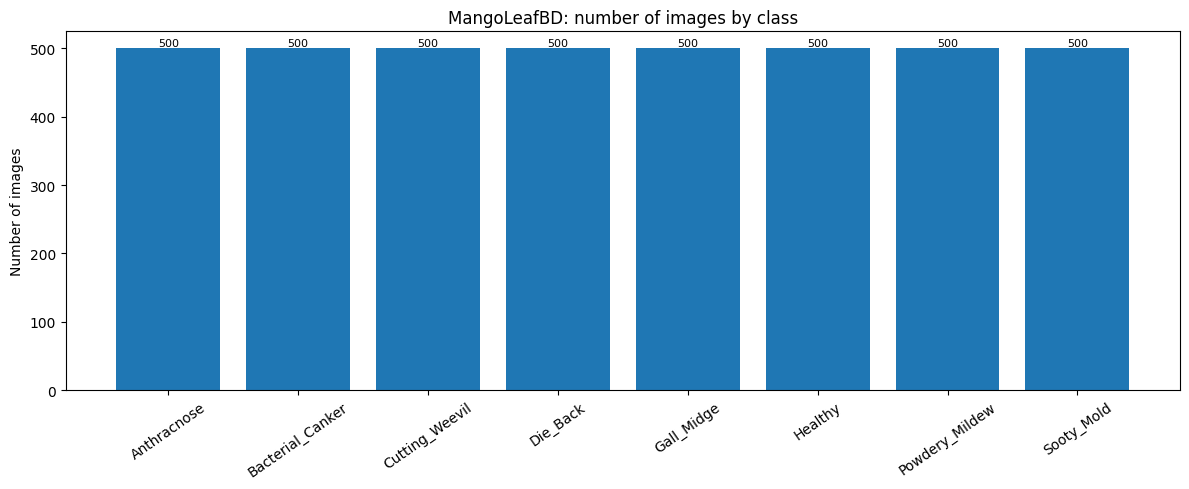

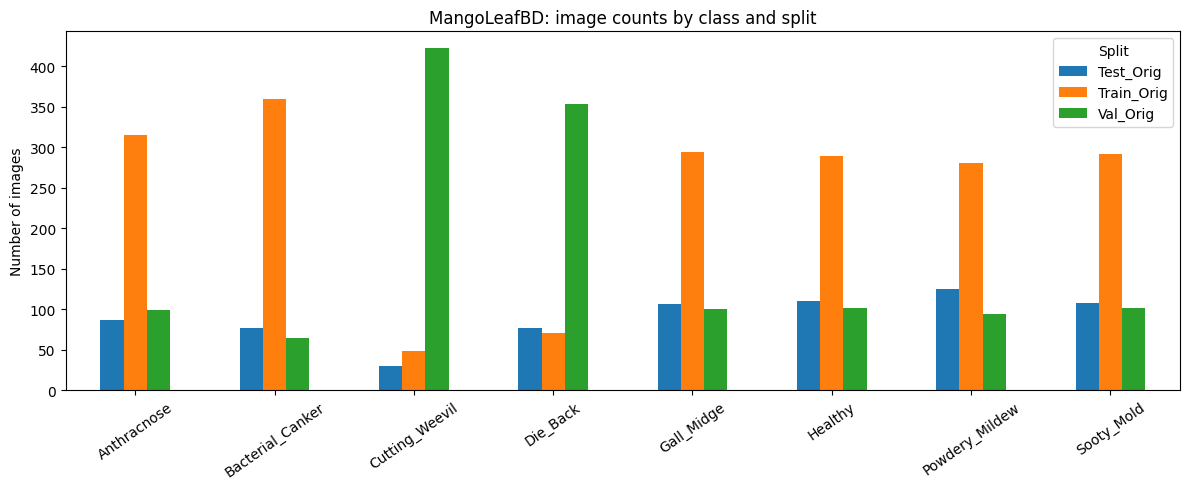

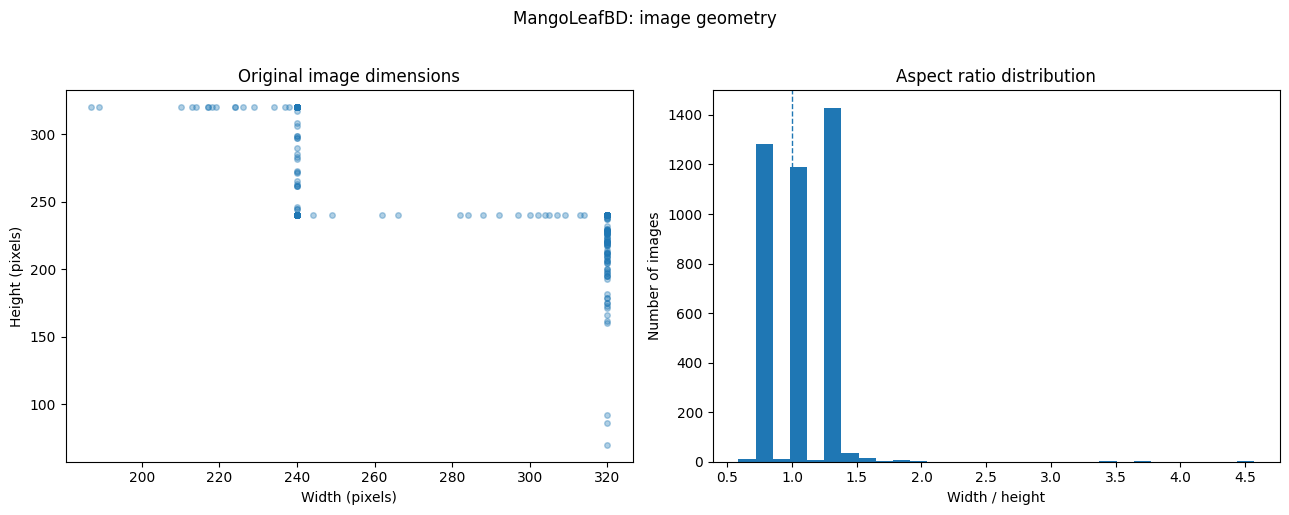

/tmp/ipykernel_569/2036143845.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/2036143845.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/2036143845.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/2036143845.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(g

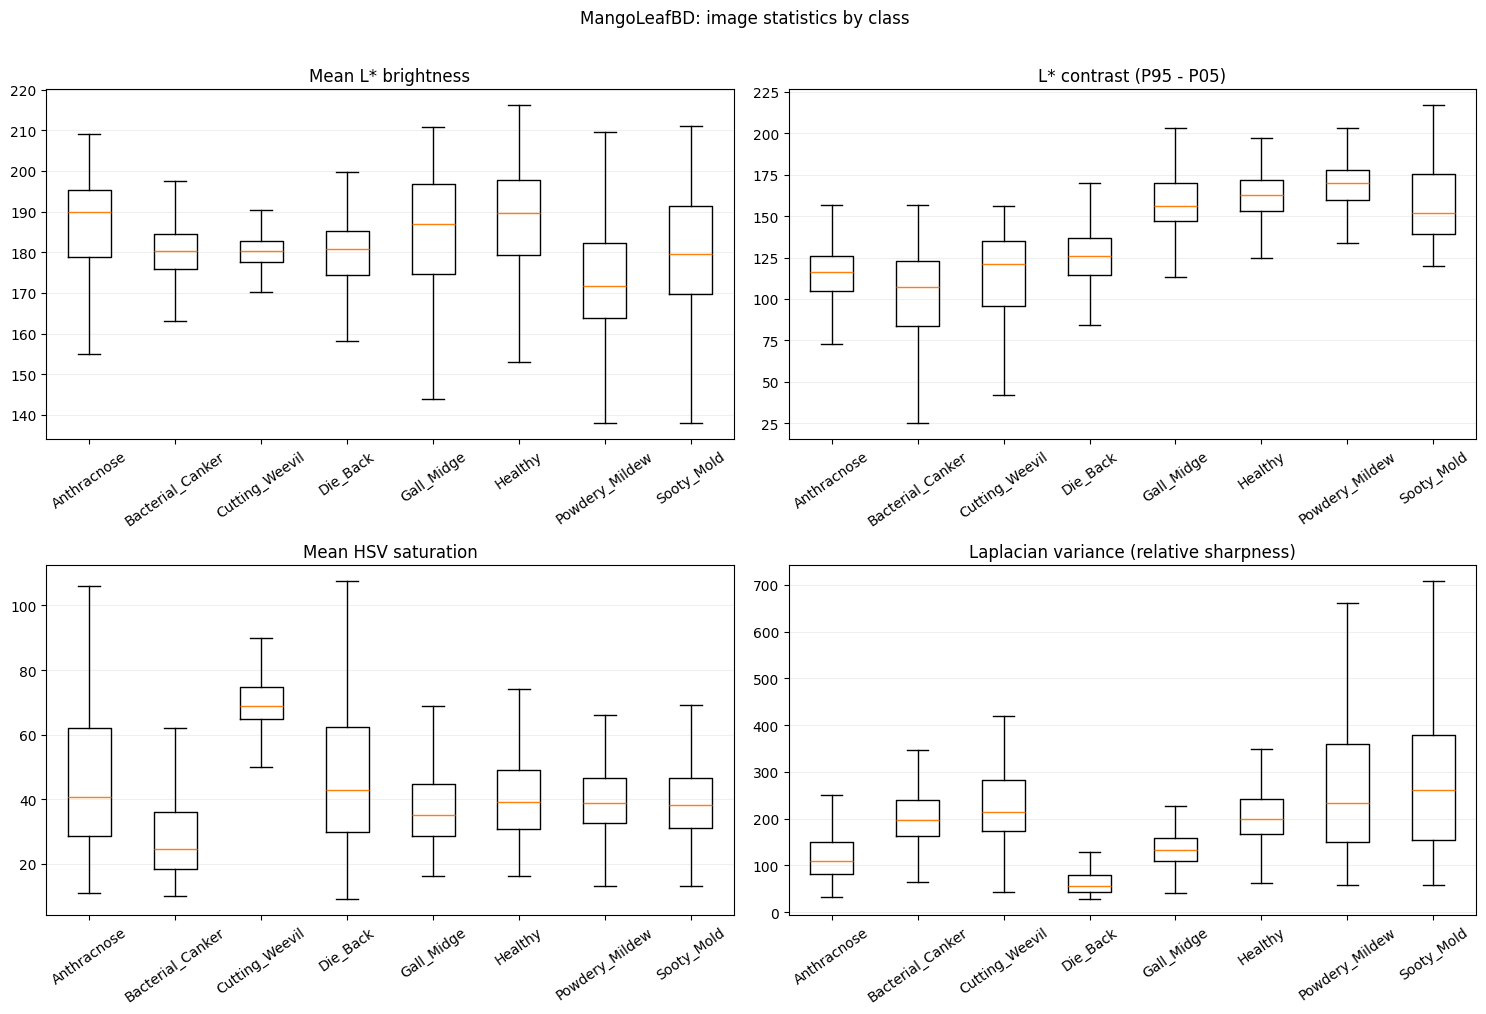

/tmp/ipykernel_569/3613657332.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/3613657332.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/3613657332.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/3613657332.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(g

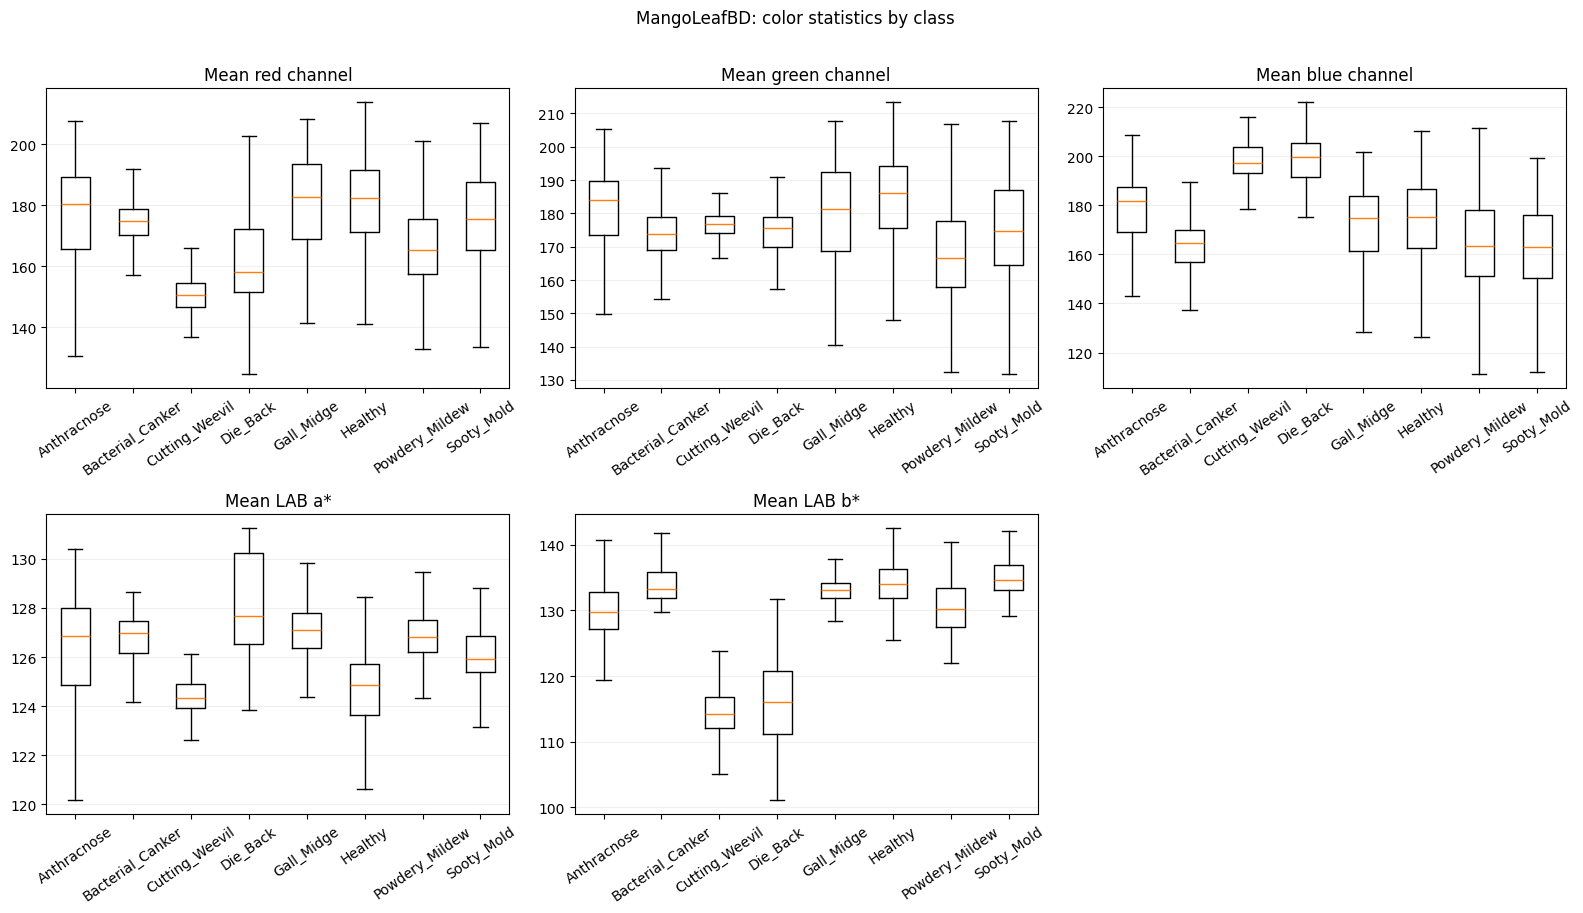

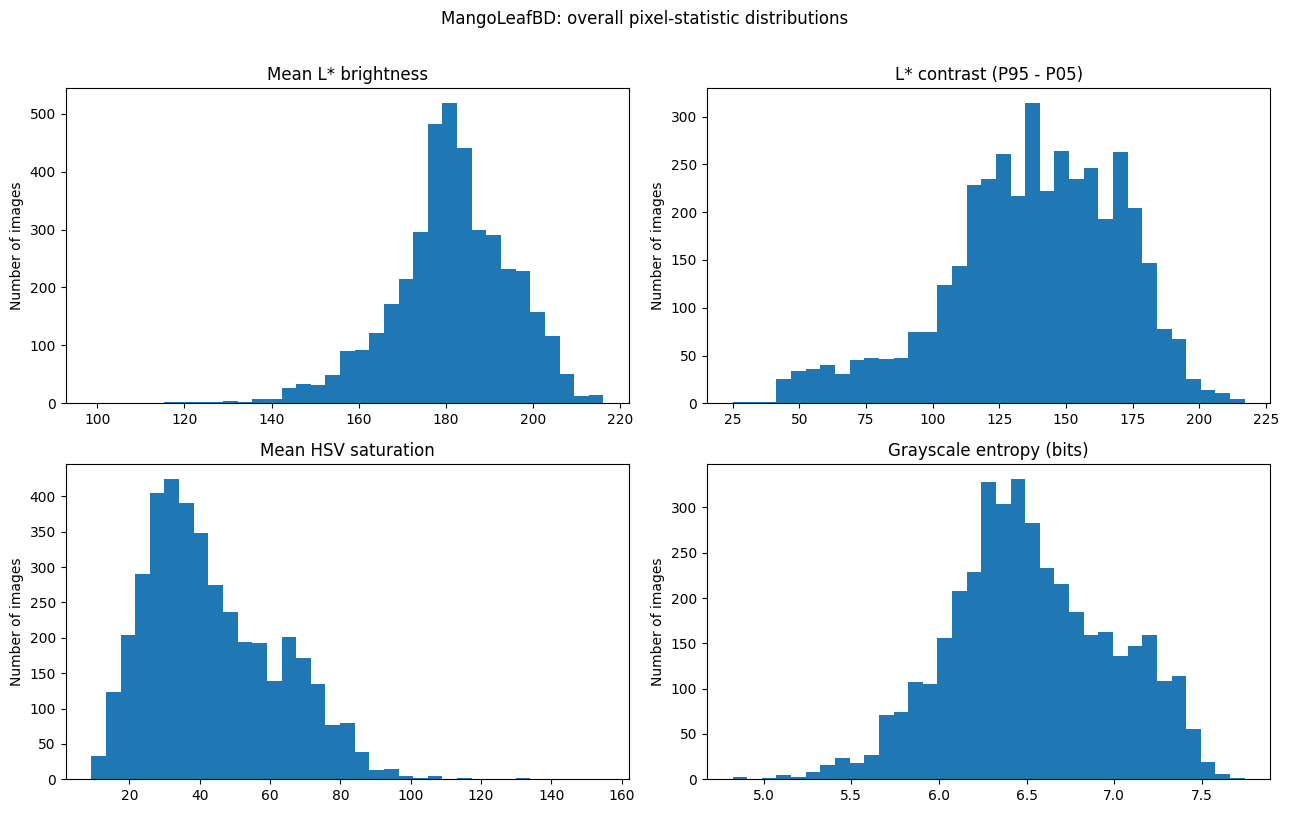

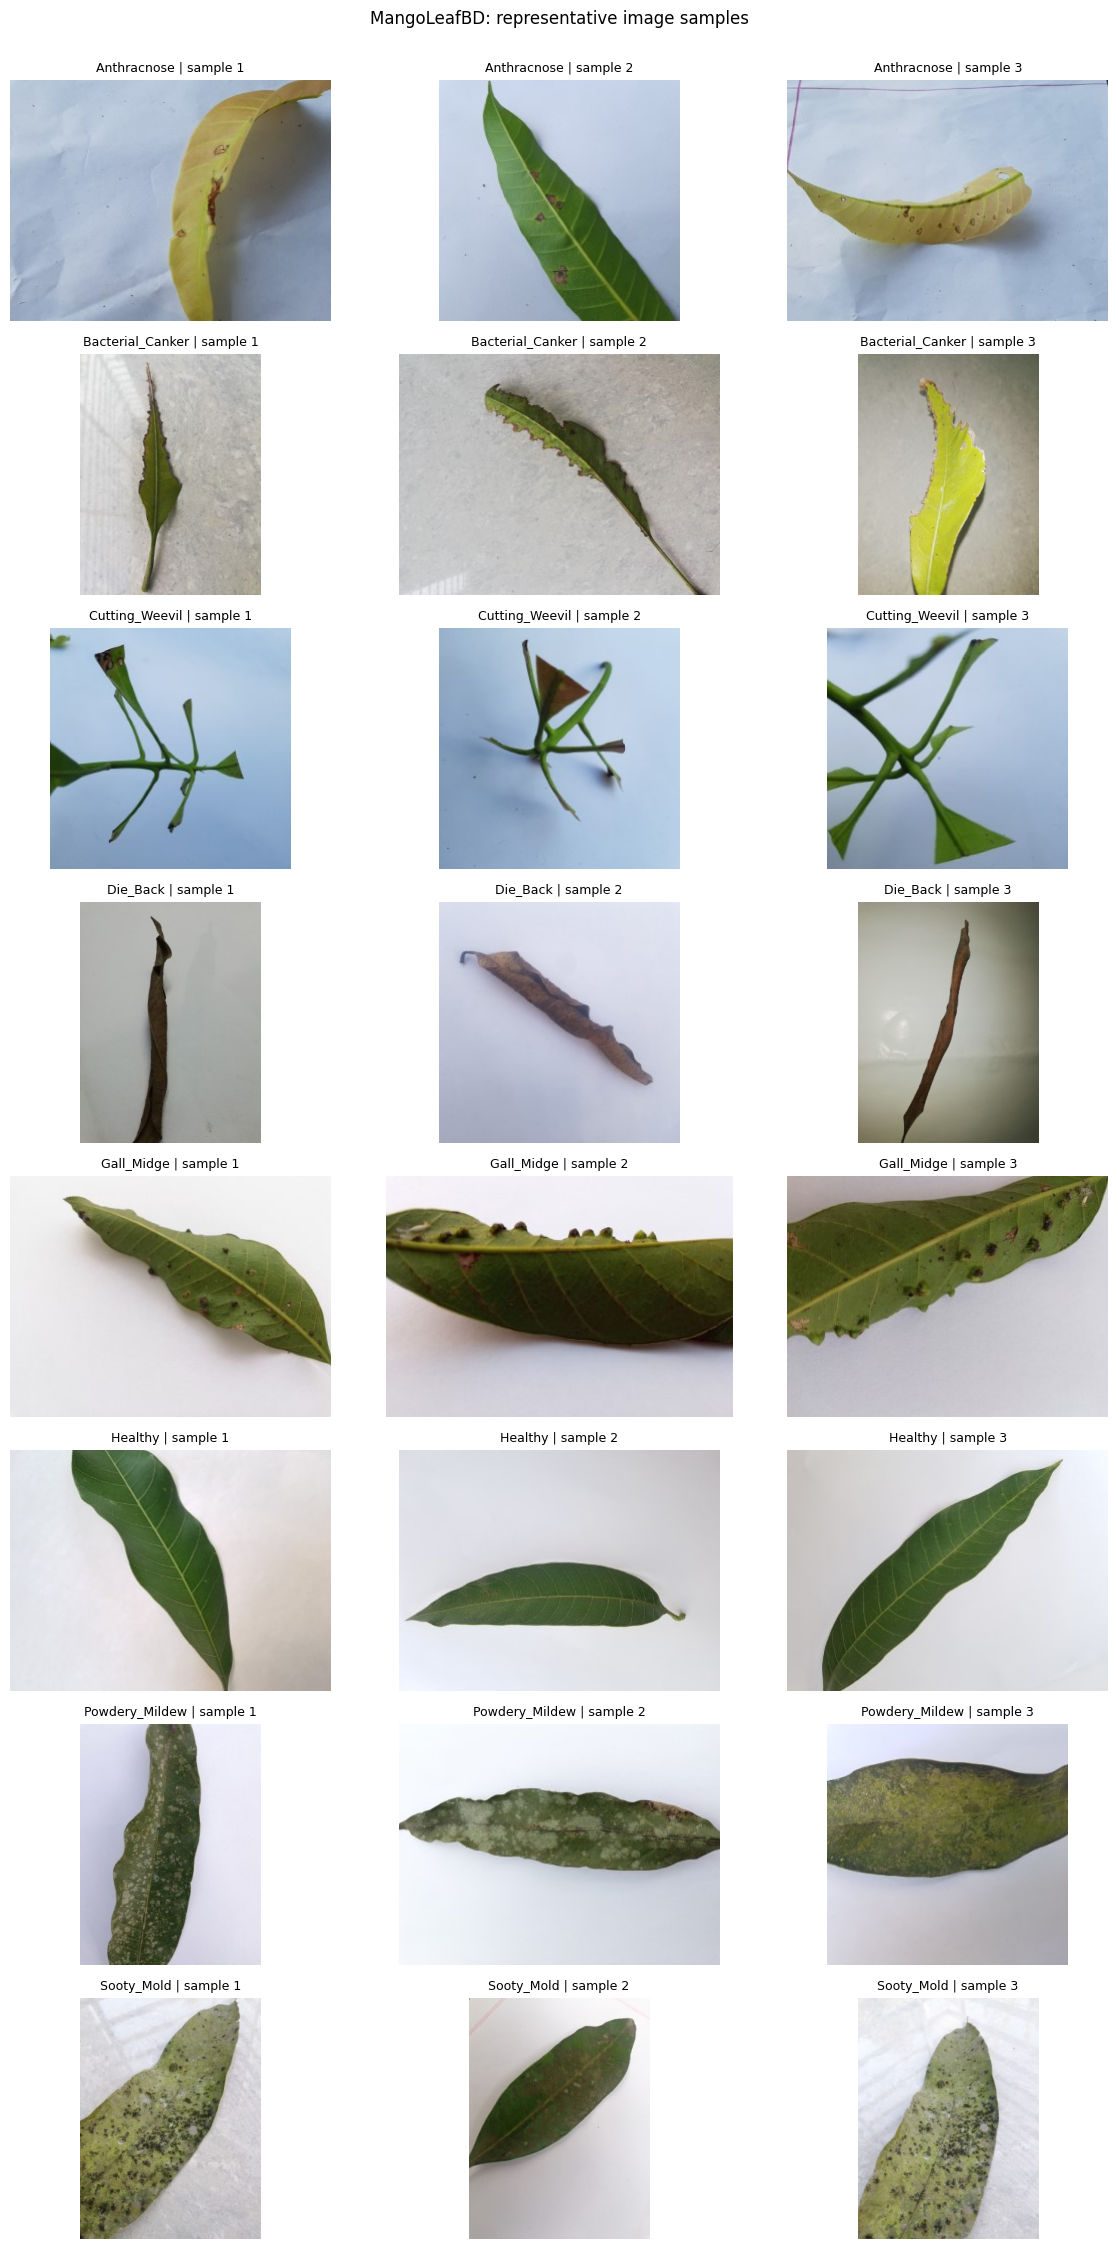

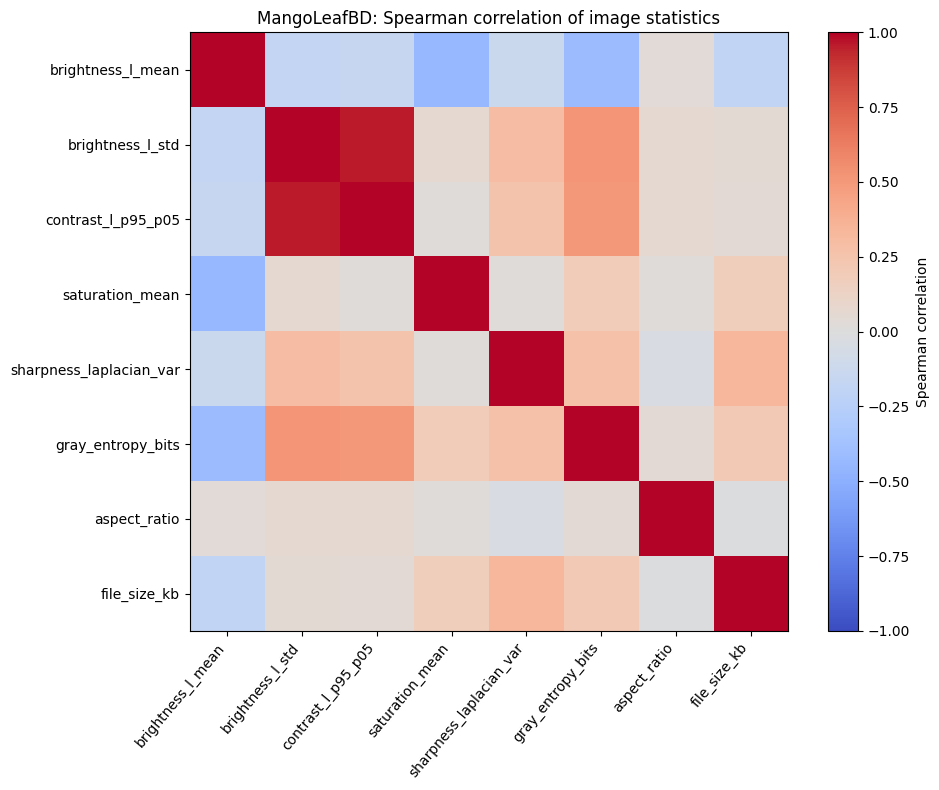


=== BẢNG 2: KIỂM TOÁN 5 PHÉP THỬ LỐI TẮT PHÔNG NỀN (MANGO) ===


Running Shortcut Audit:   0%|          | 0/4000 [00:00<?, ?it/s]

,Track,Input Representation View,Group-Split Test Acc (%),Group-Split Macro-F1
0,MANGO,1. Whole ROI (Center-Crop r=0.86),98.33,0.9833
1,MANGO,2. Segmented Organ Only (Background Masked Out),94.84,0.9440
2,MANGO,3. Background Only (Organ Masked Out),94.84,0.9396
3,MANGO,4. Four Corner Patches Only (32x32 Borders),85.08,0.8332
4,MANGO,5. Image File Metadata Only (Size + Global Stats),59.14,0.5742


[FEATURE EXTRACTION] 4,000 images x 6 variants using 2 thread(s); HOG=numpy_sobel_vectorized_shared_gradient


Extracting All Feature Variants:   0%|          | 0/4000 [00:00<?, ?it/s]

[CACHE SAVED] Đã lưu đặc trưng nén tại: /content/drive/MyDrive/Agri_EdgeAI_Research/MANGO/cache_MANGO/MANGO_features_v8_mango.npz
[EDA EXTERNAL] 3,000 mapped images | 5 mapped classes | 0 image folder(s) not mapped


... (4 outputs left out)

[EDA RESOLUTION] 1 distinct width-height combinations.


,resolution,Images
0,512x512,3000


[EDA REVIEW] 3,000 image(s) marked for manual inspection.


,file_path,label_name,review_reasons
0,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
1,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
2,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
3,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
4,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
5,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
6,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
7,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
8,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail
9,/content/agri_edgeai_ssd/MANGO/external_data/R...,Anthracnose,unusual_aspect_ratio_tail


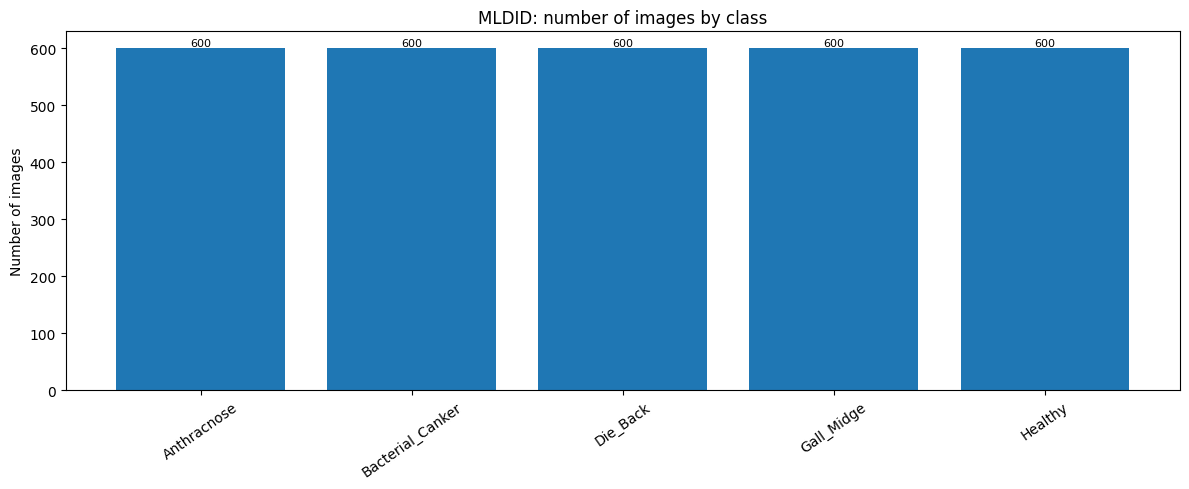

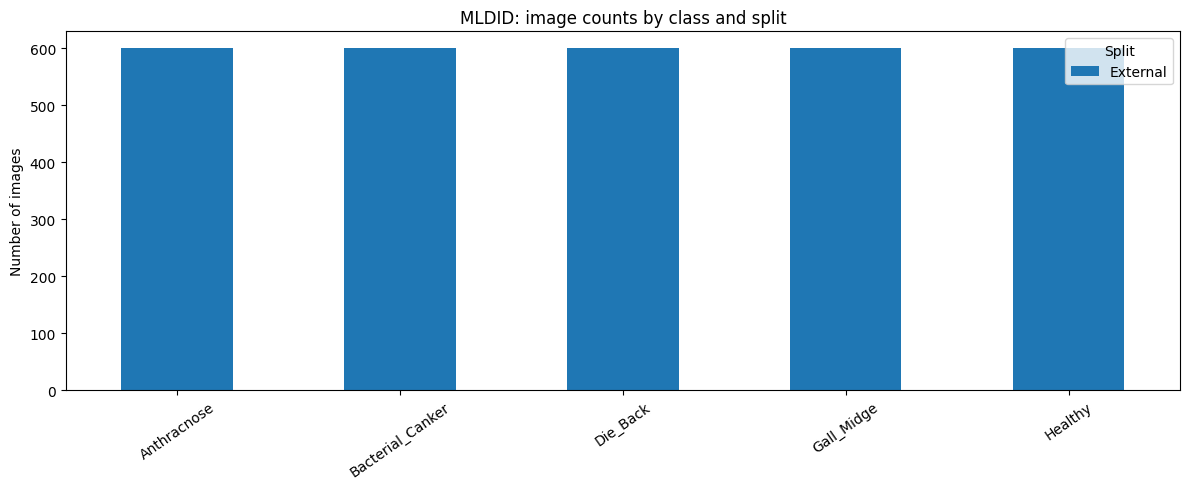

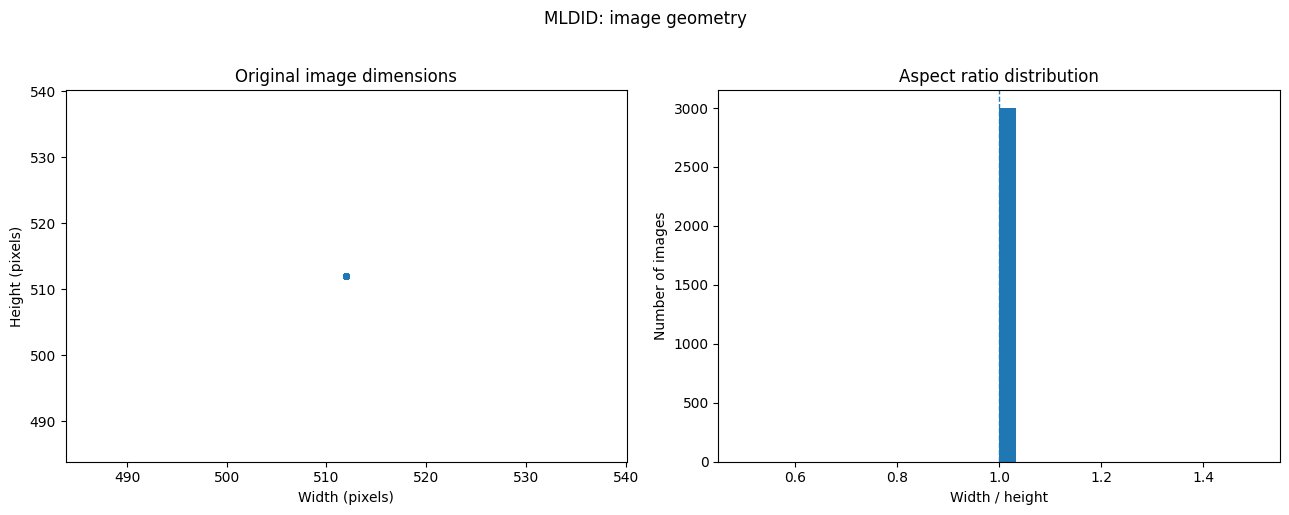

/tmp/ipykernel_569/2036143845.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/2036143845.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/2036143845.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/2036143845.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(g

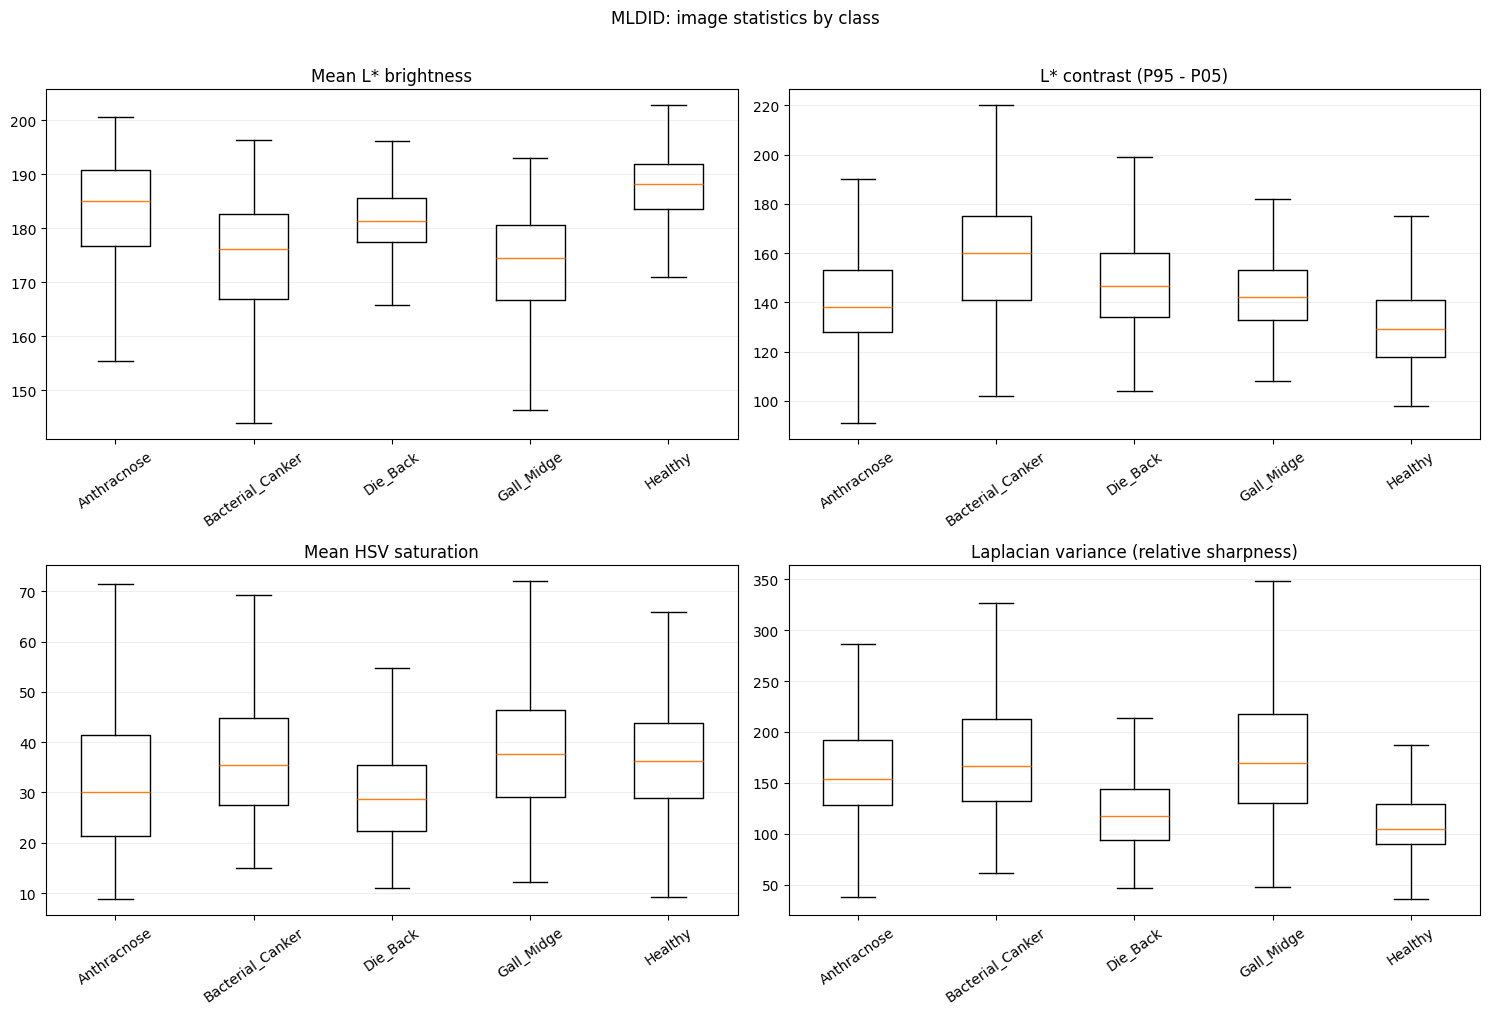

/tmp/ipykernel_569/3613657332.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/3613657332.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/3613657332.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels, showfliers=False)
/tmp/ipykernel_569/3613657332.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(g

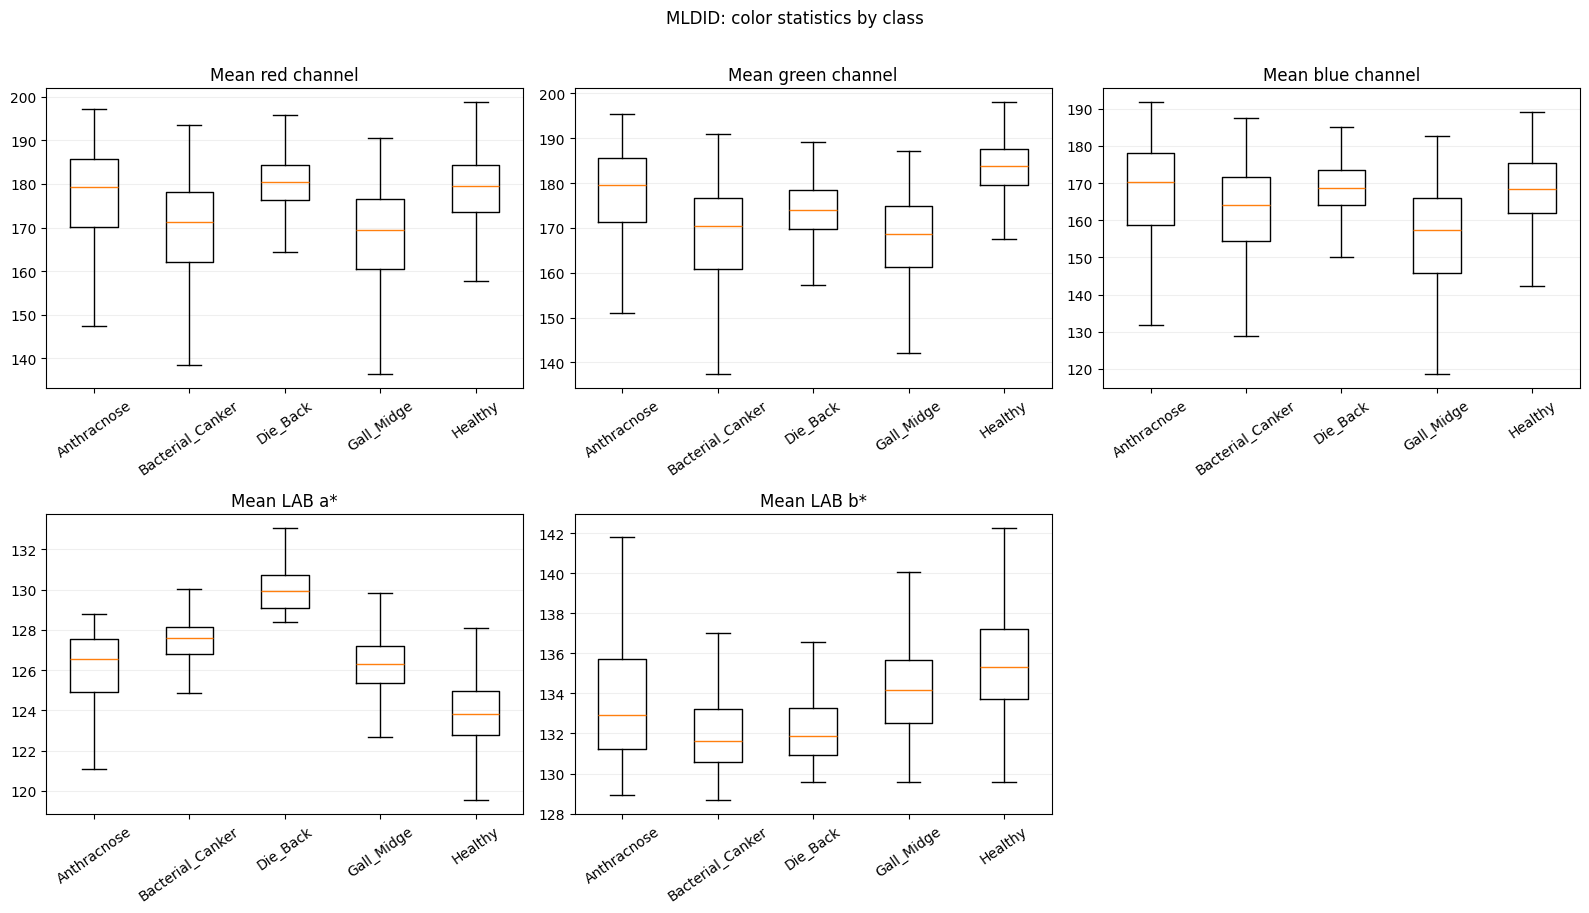

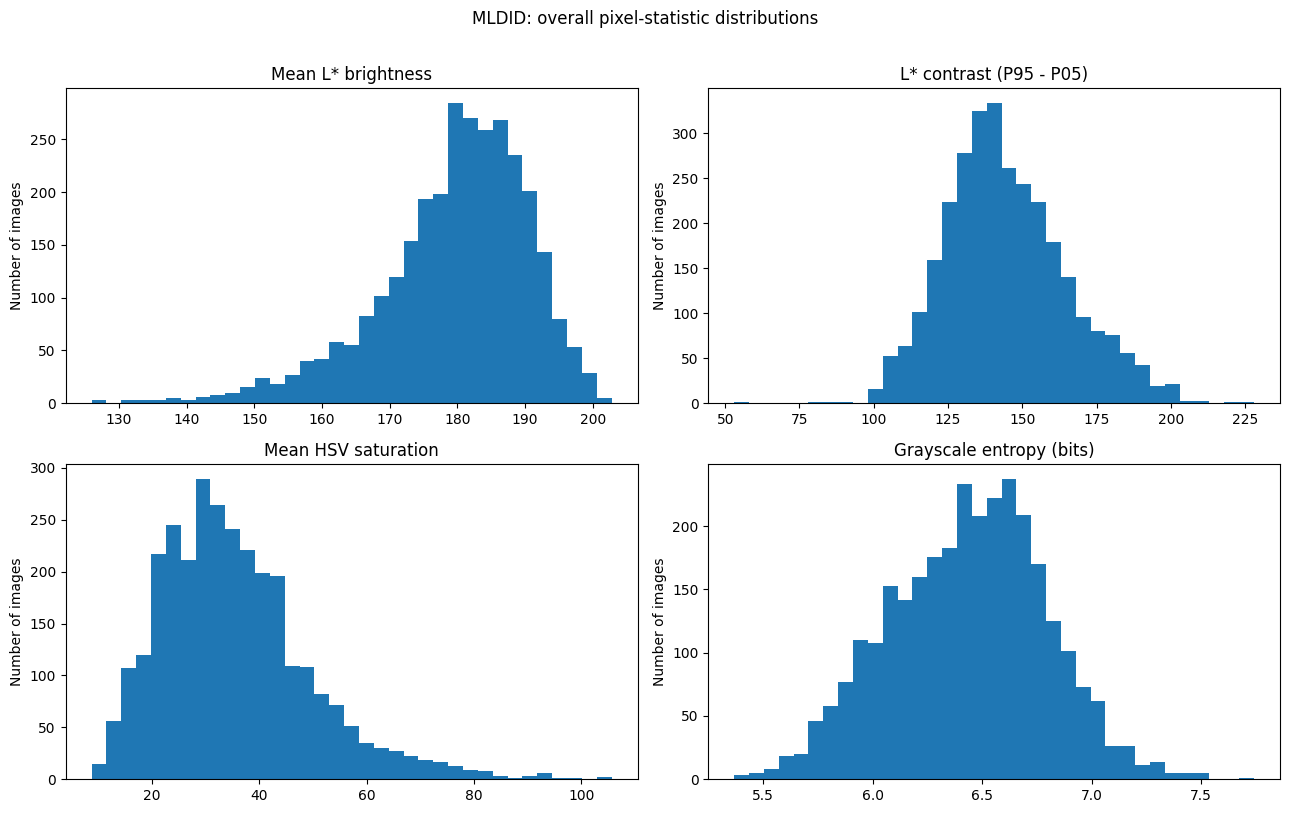

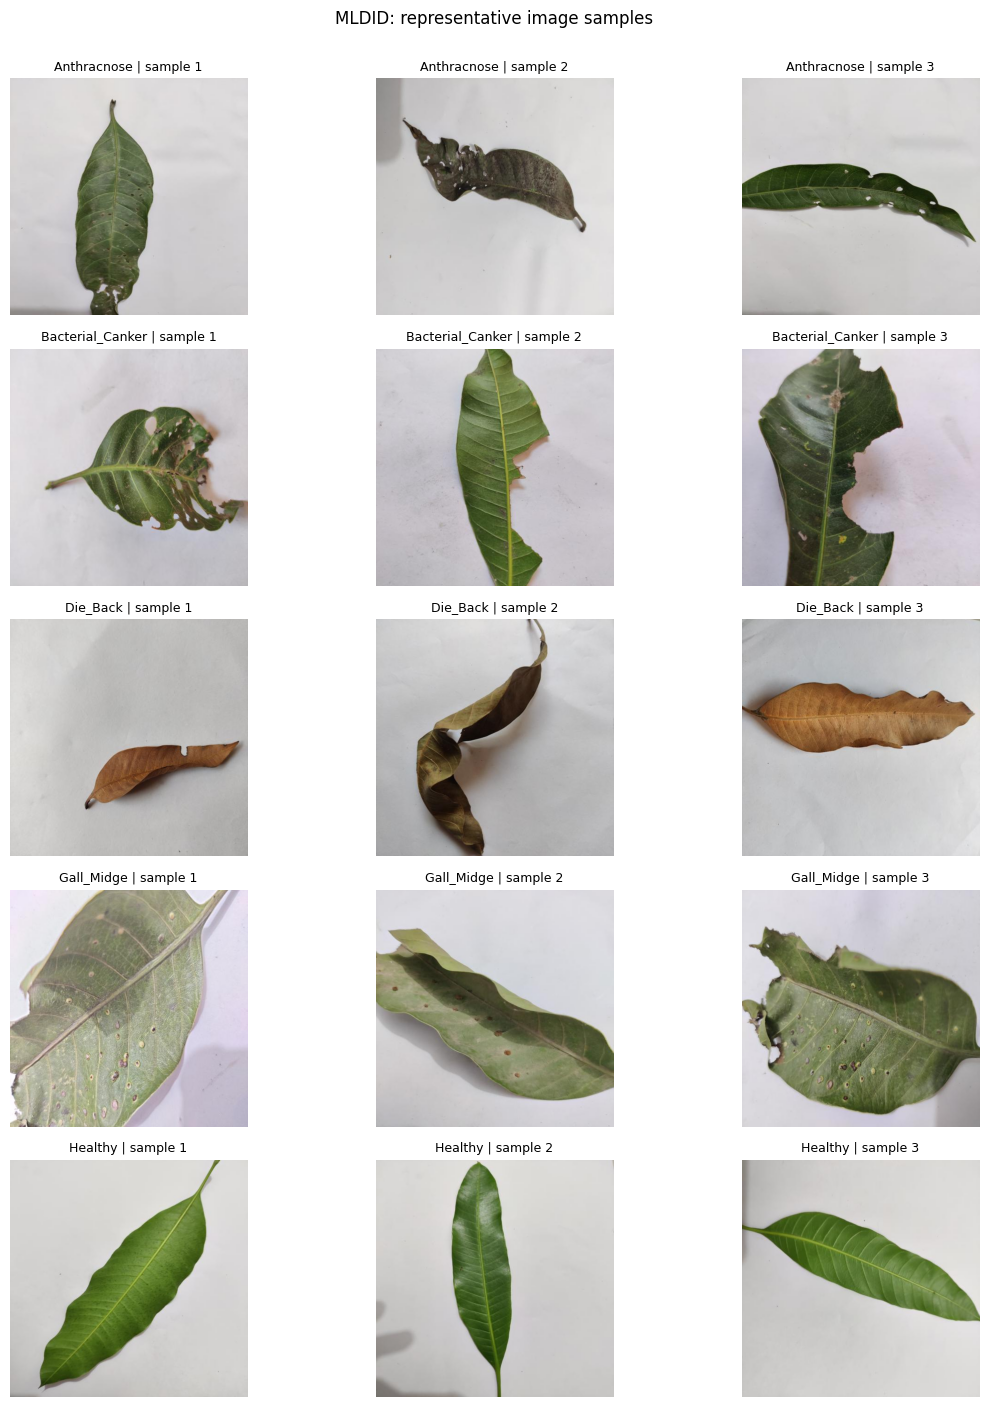

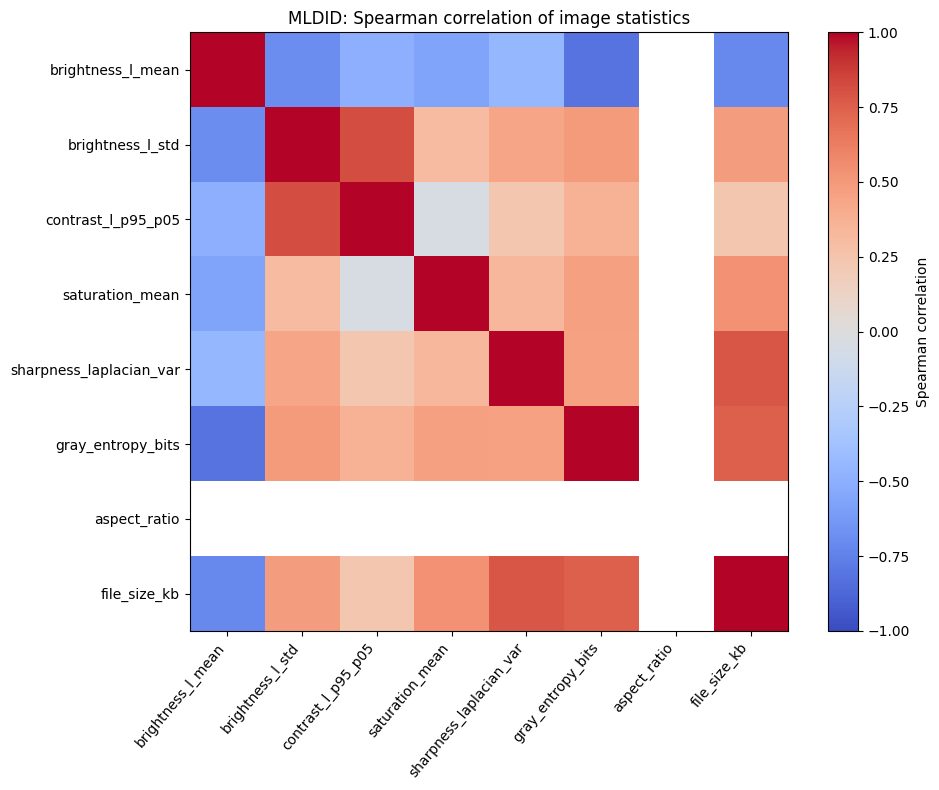


=== BẢNG 3: NGHIÊN CỨU CẮT BỎ ĐA CẤU HÌNH (ABLATION STUDY - MANGO) ===


,Configuration,Dims,3-Fold Train Group-CV F1,Test Acc (%),Macro-Precision,Macro-Recall,Test Macro-F1,95% Bootstrap CI,McNemar p-val,Estimated Relative Latency (proxy)
0,M1. HSV Only (OvR LR),52,0.8670 ± 0.0181,90.38,0.9008,0.9012,0.8997,"[0.8763, 0.9231]",0.0589,0.61x
1,M2. HSV + Fast Multi-Scale LBP (OvR LR),80,0.9548 ± 0.0103,97.35,0.9764,0.9718,0.9739,"[0.9607, 0.9848]",0.0000,0.81x
2,M3. HSV + Vectorized Sobel HOG (OvR LR),1816,0.7751 ± 0.0480,83.68,0.8565,0.7831,0.7849,"[0.7487, 0.8209]",0.0001,0.85x
3,M4. Baseline: HSV + LBP + HOG (OvR LR),1844,0.8156 ± 0.0396,86.61,0.8820,0.8356,0.8453,"[0.8122, 0.8770]",0.3018,1.04x
4,M5. M4 + CIE LAB Color Space,1901,0.8720 ± 0.0382,90.66,0.9186,0.8848,0.8948,"[0.8658, 0.9209]",0.0001,1.30x
5,M6. M5 + 5-Patch Spatial Moments,1946,0.8898 ± 0.0342,92.19,0.9313,0.8980,0.9079,"[0.8814, 0.9314]",0.0000,1.51x
6,M7a. M6 + Specular Glare Inpainting Only,1946,0.8894 ± 0.0337,92.33,0.9324,0.8996,0.9092,"[0.8824, 0.9330]",0.0000,2.59x
7,M7b. M6 + CLAHE Contrast Only,1946,0.8824 ± 0.0362,92.19,0.9307,0.8978,0.9074,"[0.8797, 0.9312]",0.0000,1.67x
8,M7c. M6 + Morphological Top/Black-Hat Only,1946,0.8892 ± 0.0357,92.05,0.9276,0.8967,0.9053,"[0.8784, 0.9297]",0.0000,2.04x
9,M7d. M6 + Quality-Gated Conditional Preproc,1946,0.8735 ± 0.0287,91.07,0.9205,0.8862,0.8964,"[0.8696, 0.9216]",0.0016,1.63x


[GATE SELECTED ON VAL] tau=0.65 | T=0.758 | Stage-1 val Macro-F1=0.9778 | Stage-1 val AURC=0.00055 | route penalty=0.0002
[GATE SELECTED ON VAL] tau=0.00 | T=1.741 | Stage-1 val Macro-F1=0.9215 | Stage-1 val AURC=0.01055 | route penalty=0.0002
[VIEW SELECTED ON VALIDATION] MANGO: adaptive | Val Macro-F1=0.9817 | tau=0.65
[GATE SELECTED ON VAL] tau=0.70 | T=0.955 | Stage-1 val Macro-F1=0.9837 | Stage-1 val AURC=0.00197 | route penalty=0.0002

=== TABLE 4 | CONFIDENCE-GATED EVALUATION — MANGO ===


,Routing Mode,Gate Threshold (tau_gate),Selected on Validation,Stage-2 Routed Samples (%),Test Accuracy (%),Group-Split Macro-F1,95% Bootstrap CI,Calibration ECE,Selective Risk AURC
0,Stage-1 LR Only,0.00,False,0.00,97.91,0.9789,"[0.9655, 0.9891]",0.0094,0.00164
1,Confidence-Gated (tau=0.60),0.60,False,0.98,98.33,0.9825,"[0.9697, 0.9921]",0.0108,0.00160
2,Confidence-Gated (tau=0.65),0.65,True,1.53,98.47,0.9836,"[0.9712, 0.9932]",0.0104,0.00158
3,Confidence-Gated (tau=0.70),0.70,False,1.95,98.61,0.9847,"[0.9729, 0.9940]",0.0122,0.00157
4,Confidence-Gated (tau=0.75),0.75,False,2.37,98.61,0.9847,"[0.9729, 0.9940]",0.0121,0.00156
5,Confidence-Gated (tau=0.80),0.80,False,3.07,98.61,0.9847,"[0.9729, 0.9940]",0.0124,0.00157
6,Confidence-Gated (tau=0.85),0.85,False,4.32,98.74,0.9859,"[0.9742, 0.9952]",0.0144,0.00151
7,Confidence-Gated (tau=0.90),0.90,False,5.86,98.74,0.9859,"[0.9742, 0.9952]",0.0142,0.00151
8,Confidence-Gated (tau=0.95),0.95,False,7.53,98.74,0.9859,"[0.9742, 0.9952]",0.0173,0.00151
9,Full Stage-2 Ensemble,1.00,False,100.00,98.74,0.9859,"[0.9742, 0.9952]",0.0386,0.00259


Table 5 robustness:   0%|          | 0/7 [00:00<?, ?it/s]


=== TABLE 5 | ROBUSTNESS — MANGO ===


... (14 outputs left out)

[GATE SELECTED ON VAL] tau=0.00 | T=0.955 | Stage-1 val Macro-F1=0.9731 | Stage-1 val AURC=0.00072 | route penalty=0.0002


Canonical MLDID features:   0%|          | 0/3000 [00:00<?, ?it/s]


=== TABLE 7 | MANGO -> MLDID EXTERNAL VALIDATION ===


,Protocol,Adaptation,Samples,Shared classes,Accuracy (%),Balanced Acc (%),Macro-F1,95% Bootstrap CI,Source view
0,Source-view in-domain Group-Split Test,None; source-only training,455,5,99.34,99.30,0.9929,"[0.9841, 1.0000]",adaptive
1,MLDID source-view Zero-Shot,No target statistics used; source-trained shar...,3000,5,31.27,31.27,0.2886,"[0.2767, 0.3005]",adaptive
2,Canonical-pose in-domain Group-Split Test,Same source/target transform; color mode=lab_l,455,5,97.36,97.24,0.9726,"[0.9568, 0.9868]",canonical_pose
3,MLDID Canonical-pose Zero-Shot,No target stats used; PCA-axis pose + foregrou...,3000,5,41.17,41.17,0.4276,"[0.4136, 0.4406]",canonical_pose
4,MLDID Canonical-pose + CORAL,Transductive; unsupervised covariance alignmen...,3000,5,31.03,31.03,0.3208,"[0.3058, 0.3355]",canonical_pose + CORAL


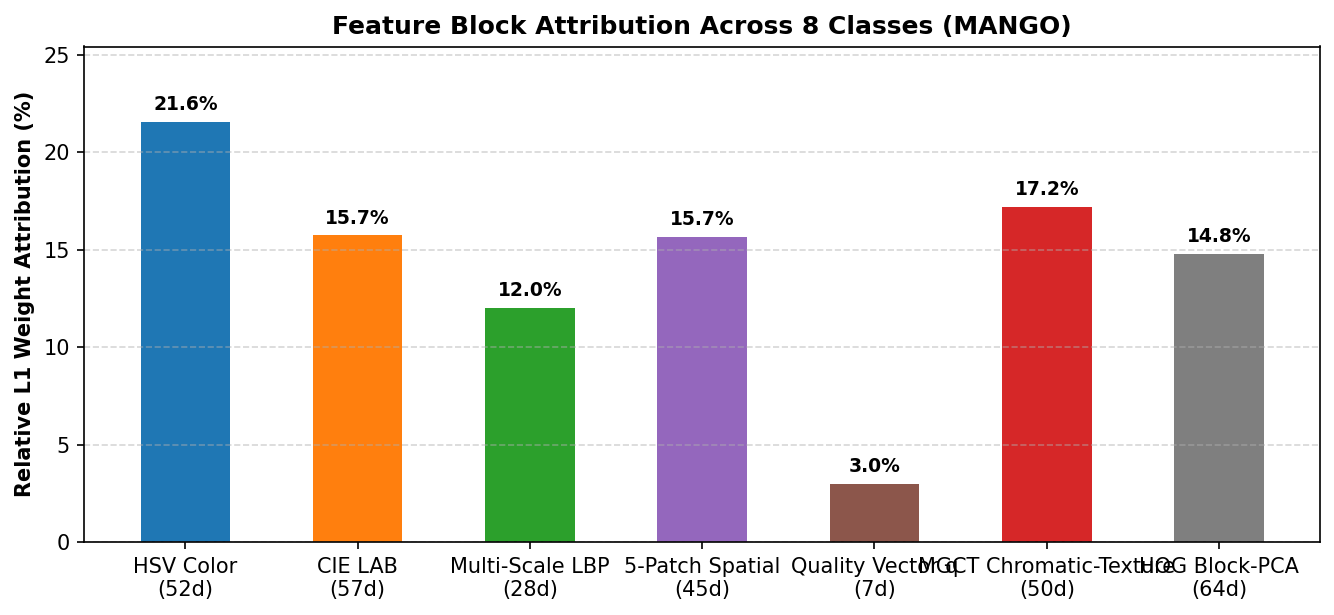


   BẢN TỔNG KẾT THỰC NGHIỆM (MANGO) — HÃY COPY TOÀN BỘ KHỐI NÀY GỬI LẠI
- Track đang chạy: MANGO | Số lớp: 8 (['Anthracnose', 'Bacterial_Canker', 'Cutting_Weevil', 'Die_Back', 'Gall_Midge', 'Healthy', 'Powdery_Mildew', 'Sooty_Mold'])
- Tổng số ảnh gốc đã kiểm toán: 4,000 ảnh

[1] TÓM TẮT KIỂM TOÁN RÒ RỈ & GẦN-TRÙNG (TABLE 1):
 Class ID       Class Name  Total Images  Unique Specimen Clusters (pHash<=6 | HSV cosine>=0.992)  Near-Duplicate / Aug-Mix Ratio (%) Dominant Resolution  Random-Split Test Leakage (%)
        0      Anthracnose           500                                                      352                                29.6             320x240                           39.0
        1 Bacterial_Canker           500                                                      275                                45.0             240x320                           39.0
        2   Cutting_Weevil           500                                                       31                   

,Track,Main dataset,External dataset configured,Main images after audit,Number of classes,CV-ranked ablation configuration,Best ablation Test Macro-F1,Validation-selected gate mode,Validation-selected gate Test Macro-F1,External validation completed,Artifacts directory,Status
0,MANGO,"MangoLeafBD Dataset (8 classes, ~4,000 images)",Raw Images of Five Class (Resized) / MLDID (5 ...,4000,8,M10. M9 + Block-PCA Compression (Proposed Stag...,0.9789,Confidence-Gated (tau=0.65),0.9836,True,/content/drive/MyDrive/Agri_EdgeAI_Research/MA...,SUCCESS


[MANGO PIPELINE COMPLETE] Summary saved to /content/drive/MyDrive/Agri_EdgeAI_Research/Mango_Overall_Summary.csv


In [ ]:
all_track_results = []
for index, track_cfg in enumerate(TRACKS, start=1):
    track_name = track_cfg["track_name"]
    print(
        f"\n{'=' * 96}\n"
        f"[MASTER] Track {index}/{len(TRACKS)}: {track_name}\n"
        f"{'=' * 96}"
    )
    try:
        track_result = run_one_track(track_cfg)
        track_result["Status"] = "SUCCESS"
    except Exception as exc:
        error_text = f"{type(exc).__name__}: {exc}"
        print(f"[TRACK FAILED] {track_name}: {error_text}")
        traceback.print_exc()
        error_path = os.path.join(
            BASE_DRIVE_DIR, f"ERROR_{track_name}.txt"
        )
        with open(error_path, "w", encoding="utf-8") as error_file:
            error_file.write(f"Track: {track_name}\n")
            error_file.write(f"Dataset: {track_cfg['main_dataset']}\n")
            error_file.write(f"Error: {error_text}\n")
        track_result = {
            "Track": track_name,
            "Main dataset": track_cfg["main_dataset"],
            "Status": "FAILED",
            "Error": error_text,
            "Artifacts directory": os.path.join(
                BASE_DRIVE_DIR,
                track_cfg["drive_folder"],
                f"artifacts_{track_name}",
            ),
        }
    all_track_results.append(track_result)
    gc.collect()

summary_df = pd.DataFrame(all_track_results)
display(summary_df)
summary_path = os.path.join(BASE_DRIVE_DIR, "Mango_Overall_Summary.csv")
summary_df.to_csv(summary_path, index=False)
print(f"[MANGO PIPELINE COMPLETE] Summary saved to {summary_path}")


## 17. Output cuối cùng

Kết quả được lưu trong:
`/content/drive/MyDrive/Agri_EdgeAI_Research/MANGO/artifacts_MANGO/`

Các file chính:
- `manifest_MANGO_audited_v5.csv`
- `Table1_Dataset_Leakage_and_Group_Audit.csv`
- `Table2_Background_Shortcut_Audit.csv`
- `Table3_Progressive_Ablation_Study.csv`
- `Table4_Confidence_Gated_and_Calibration.csv`
- `Table5_MultiSeverity_Robustness.csv`
- `Table6_Fair_EndToEnd_CPU_Benchmark.csv`
- `Table7_External_Dataset_Validation.csv` nếu có đủ nhãn chung
- `EDA_MangoLeafBD/`: metrics từng ảnh, thống kê theo lớp/split, danh sách cần xem lại và các biểu đồ EDA.
- `EDA_MLDID/`: báo cáo EDA riêng cho tập external nếu root được phân giải và có nhãn hợp lệ.
- Hình attribution, bản tổng kết Markdown/CSV và cache `v8`.

Bảng tổng kết đơn track nằm tại `Agri_EdgeAI_Research/MANGO/Mango_Overall_Summary.csv`.

**Trước khi viết paper:** chạy lại từ đầu, kiểm tra class counts, log lỗi và trạng thái benchmark. Báo cáo Group-Split là kết quả chính; Random-Split là tham chiếu có rủi ro leakage; CORAL là transductive. Không dùng các con số lịch sử trong HTML như kết quả của phiên v5.
